# KKBox 데이터 컬럼 정리

**KKBox** = 대만의 음악 스트리밍 앱 (멜론·스포티파이 같은 서비스). 구독(정기 결제)으로 운영됨.
데이터 출처: Kaggle *WSDM - KKBox's Churn Prediction Challenge* (2단계 v2 데이터)

| 데이터 | 내용 | 한 줄의 의미 | 기간 |
|---|---|---|---|
| `members` | 유저 특성 (도시, 나이, 성별, 가입 경로, 가입일) | 유저 1명 | 가입일 2004 ~ 2017.4 |
| `user_logs` | 일별 음악 청취 기록 | 유저 1명의 하루 청취 요약 | **2017.3.1 ~ 3.31 (31일, 빠진 날 없음)** |
| `transactions` | 결제·구독 기록 | 결제 1건 | 대부분 2017.3 |

모든 데이터는 **`msno`(유저 ID)** 로 서로 연결됨.

# 1부. 데이터 전처리

데이터를 불러오고 컬럼의 의미·타입·결측을 정리함. 분석에 쓸 표를 만드는 단계임.

- 1절 데이터 불러오기 / 2절 컬럼 정리 함수
- 3절 `members` · 4절 `user_logs` · 5절 `transactions`


In [1]:
import pandas as pd

# 표를 볼 때 행·열이 잘리지 않도록 설정 (컬럼 정리 표가 길어서 필요)
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 100)
pd.set_option('display.max_colwidth', 80)

## 1. 데이터 불러오기
CSV 대신 **parquet**으로 읽음. `data/` 폴더에 parquet 파일이 없으면 먼저 `python scripts/csv_to_parquet.py`를 한 번 돌리면 됨.

4개를 모두 불러도 3초쯤 걸리고 메모리는 2.2GB 정도 씀. (같은 걸 CSV로 읽으면 1분 이상 걸리고 5GB 넘게 먹음.)
일부 컬럼만 필요하면 `columns=`로 잘라 읽으면 훨씬 가벼움 — 예: `pd.read_parquet('data/user_logs_v2.parquet', columns=['msno', 'date'])`

In [26]:
# 데이터 파일은 모두 data 폴더 안에 있음 (scripts/csv_to_parquet.py로 CSV를 변환해 둔 것)
# transactions(결제 기록)는 2,298만 행 1.9GB라 여기서 상시로 올리지 않음.
#   쓰는 셀에서 필요한 컬럼만 그때그때 읽음 (5절·8-1절·10절)
#   병합본이므로 scripts/merge_transactions.py 를 먼저 한 번 실행해야 함
# user_logs는 두 개임 — 컬럼은 완전히 같고 담긴 달만 다름
#   user_logs     = 2017년 3월. 기준일과 결과 변수(D1)를 만드는 분석 기간임 (8~12절)
#   user_logs_feb = 2017년 2월. 평소 습관 변수(D)를 한 번 재서 고정하는 측정 창임 (13절)
#   2월분은 v1 원본(user_logs.csv, 28.4GB)에서 scripts/extract_user_logs_feb.py 로 뽑아 둔 것임
members = pd.read_parquet('data/members_v3.parquet')
user_logs = pd.read_parquet('data/user_logs_v2.parquet')          # 2017년 3월 = 분석 기간
user_logs_feb = pd.read_parquet('data/user_logs_feb2017.parquet')  # 2017년 2월 = 평소 습관 측정 창

# shape = (행 개수, 컬럼 개수)
print('members      :', members.shape)
print('user_logs    :', user_logs.shape, ' (2017-03, 분석 기간)')
print('user_logs_feb:', user_logs_feb.shape, ' (2017-02, 습관 측정 창)')

members      : (6769473, 6)
user_logs    : (18396362, 9)  (2017-03, 분석 기간)
user_logs_feb: (16079619, 9)  (2017-02, 습관 측정 창)


## 2. 컬럼 정리 함수
데이터마다 컬럼 정리 표를 만드는 함수임. 표에 들어가는 항목:
- **타입**: 숫자(int/float)인지 글자(object)인지
- **결측 수**: 비어 있는 칸 개수
- **고유값 수**: 서로 다른 값이 몇 종류인지 (2면 0/1 같은 예·아니오 값, 아주 많으면 ID나 숫자값)
- **최솟값 / 최댓값**: 숫자 컬럼의 범위 (이상한 값이 있는지 확인용)
- **예시 값**: 실제로 들어 있는 값 몇 개
- **설명**: 컬럼의 의미

In [4]:
def summarize_columns(df, descriptions):
    """df의 컬럼마다 타입·결측·고유값·범위·예시·설명을 한 줄씩 정리한 표를 돌려줌."""
    rows = []
    for col in df.columns:
        is_number = pd.api.types.is_numeric_dtype(df[col])   # 숫자 컬럼인지 (숫자일 때만 최솟값·최댓값 표시)
        rows.append({
            '컬럼': col,
            '타입': str(df[col].dtype),
            '결측 수': df[col].isna().sum(),                               # 빈 칸 개수
            '고유값 수': df[col].nunique(),                                 # 서로 다른 값의 종류 수
            '최솟값': df[col].min() if is_number else '',
            '최댓값': df[col].max() if is_number else '',
            '예시 값': ', '.join(map(str, df[col].dropna().unique()[:4])),  # 실제 값 4개
            '설명': descriptions.get(col, ''),                              # 아래에서 정의한 설명
        })
    return pd.DataFrame(rows)

## 3. `members` 컬럼 정리 (유저 특성, 약 677만 명)
⚠️ `city`, `registered_via`는 숫자 코드로만 되어 있고 **실제 이름(어느 도시, 어떤 가입 경로)은 공개되지 않았음.** 숫자는 크기가 아니라 **그룹 번호**임.

In [5]:
members_desc = {
    'msno': '유저 ID (암호화된 문자열). 모든 데이터를 연결하는 키',
    'city': '거주 도시 코드 (1~22, 이름 비공개). 1번이 약 71%로 대부분 → 1은 "정보 없음"일 가능성',
    'bd': '나이. ⚠️ 67%가 0(미입력)이고 -7168, 2016 같은 말이 안 되는 값도 있음 → 분석 시 정상 범위(예: 10~80세)만 사용',
    'gender': '성별 (male / female). ⚠️ 약 65%가 비어 있음',
    'registered_via': '가입 경로 코드 (이름 비공개). 4, 3, 9, 7번이 대부분',
    'registration_init_time': '가입일 (YYYYMMDD 숫자) ★리텐션 분석의 Day 0 후보',
}
summarize_columns(members, members_desc)

,컬럼,타입,결측 수,고유값 수,최솟값,최댓값,예시 값,설명
0,msno,object,0,6769473,,,"Rb9UwLQTrxzBVwCB6+bCcSQWZ9JiNLC9dXtM1oEsZA8=, +tJonkh+O1CA796Fm5X60UMOtB6POH...",유저 ID (암호화된 문자열). 모든 데이터를 연결하는 키
1,city,int32,0,21,1,22,"1, 6, 4, 5","거주 도시 코드 (1~22, 이름 비공개). 1번이 약 71%로 대부분 → 1은 ""정보 없음""일 가능성"
2,bd,int32,0,386,-7168,2016,"0, 32, 30, 34","나이. ⚠️ 67%가 0(미입력)이고 -7168, 2016 같은 말이 안 되는 값도 있음 → 분석 시 정상 범위(예: 10~80세)만 사용"
3,gender,object,4429505,2,,,"female, male",성별 (male / female). ⚠️ 약 65%가 비어 있음
4,registered_via,int32,0,18,-1,19,"11, 7, 9, 3","가입 경로 코드 (이름 비공개). 4, 3, 9, 7번이 대부분"
5,registration_init_time,int32,0,4782,20040326,20170429,"20110911, 20110914, 20110915, 20110916",가입일 (YYYYMMDD 숫자) ★리텐션 분석의 Day 0 후보


결측치 제거한 member 데이터

In [6]:
# 결측치가 있는 행을 모두 뺀 members (members_clean)
# 결측 기준: gender가 비어 있음(NaN) + bd(나이)가 0(미입력)이거나 말이 안 되는 값(10~80세 밖) + city가 1번("정보 없음"으로 봄)
# city 1번 근거: 전체의 약 71%가 1번인데, 성별·나이를 입력한 행에서는 약 19%로 크게 줄어듦 → 미입력 시 1번으로 채워진 것으로 보임
gender_missing = members['gender'].isna()
bd_missing = ~members['bd'].between(10, 80)
city_missing = members['city'] == 1

any_missing = gender_missing | bd_missing | city_missing
members_clean = members[~any_missing].copy()

print(f'전체 행               : {len(members):,}')
print(f'gender 결측           : {gender_missing.sum():,}')
print(f'bd 결측·이상값         : {bd_missing.sum():,}')
print(f'city 1번              : {city_missing.sum():,}')
print(f'셋 중 하나라도 결측     : {any_missing.sum():,}')
print(f'남은 행(members_clean): {len(members_clean):,} ({len(members_clean) / len(members):.1%})')

summarize_columns(members_clean, members_desc)

전체 행               : 6,769,473
gender 결측           : 4,429,505
bd 결측·이상값         : 4,550,558
city 1번              : 4,804,326
셋 중 하나라도 결측     : 5,002,167
남은 행(members_clean): 1,767,306 (26.1%)


,컬럼,타입,결측 수,고유값 수,최솟값,최댓값,예시 값,설명
0,msno,object,0,1767306,,,"WFLY3s7z4EZsieHCt63XrsdtfTEmJ+2PnnKLH5GY4Tk=, yLkV2gbZ4GLFwqTOXLVHz0VGrMYcgB...",유저 ID (암호화된 문자열). 모든 데이터를 연결하는 키
1,city,int32,0,20,3,22,"6, 4, 5, 13","거주 도시 코드 (1~22, 이름 비공개). 1번이 약 71%로 대부분 → 1은 ""정보 없음""일 가능성"
2,bd,int32,0,71,10,80,"32, 30, 34, 19","나이. ⚠️ 67%가 0(미입력)이고 -7168, 2016 같은 말이 안 되는 값도 있음 → 분석 시 정상 범위(예: 10~80세)만 사용"
3,gender,object,0,2,,,"female, male",성별 (male / female). ⚠️ 약 65%가 비어 있음
4,registered_via,int32,0,7,3,14,"9, 7, 3, 4","가입 경로 코드 (이름 비공개). 4, 3, 9, 7번이 대부분"
5,registration_init_time,int32,0,4782,20040326,20170429,"20110915, 20110916, 20110917, 20110918",가입일 (YYYYMMDD 숫자) ★리텐션 분석의 Day 0 후보


## 4. `user_logs` 컬럼 정리 (일별 청취 기록, 약 1,840만 줄)

아래 설명은 **3월분(`user_logs`)** 기준임. 1절에서 같이 올린 **2월분(`user_logs_feb`, 1,608만 줄)** 은 컬럼 구성이 완전히 같고 담긴 달만 다름 — 평소 습관 변수(D)를 재는 **측정 창**으로 13절에서 씀.
한 줄 = **유저 1명이 하루 동안 들은 음악의 요약**임. 그날 음악을 안 들었으면 줄이 없음
→ 이 데이터에 줄이 있는 날 = **그 유저가 앱을 사용한(음악을 재생한) 날**

`num_25` ~ `num_100`은 곡을 **얼마나 끝까지 들었는지**로 나눈 곡 수임.

In [7]:
user_logs_desc = {
    'msno': '유저 ID',
    'date': '청취 날짜 (YYYYMMDD 숫자). 2017-03-01 ~ 03-31, 31일 모두 있음',
    'num_25': '곡 길이의 25% 미만만 듣고 넘긴 곡 수 (거의 바로 스킵)',
    'num_50': '25% ~ 50% 들은 곡 수',
    'num_75': '50% ~ 75% 들은 곡 수',
    'num_985': '75% ~ 98.5% 들은 곡 수',
    'num_100': '98.5% 이상, 거의 끝까지 들은 곡 수',
    'num_unq': '그날 들은 서로 다른 곡 수 (같은 곡 반복은 1곡으로)',
    'total_secs': '그날 총 청취 시간 (초). ⚠️ 하루(86,400초)를 넘는 이상한 값이 4,200건 있음',
}
summarize_columns(user_logs, user_logs_desc)

,컬럼,타입,결측 수,고유값 수,최솟값,최댓값,예시 값,설명
0,msno,object,0,1103894,,,"u9E91QDTvHLq6NXjEaWv8u4QIqhrHk72kE+w31Gnhdg=, nTeWW/eOZA/UHKdD5L7DEqKKFTjaAj...",유저 ID
1,date,int32,0,31,20170301,20170331,"20170331, 20170330, 20170324, 20170325","청취 날짜 (YYYYMMDD 숫자). 2017-03-01 ~ 03-31, 31일 모두 있음"
2,num_25,int32,0,743,0,5639,"8, 2, 52, 176",곡 길이의 25% 미만만 듣고 넘긴 곡 수 (거의 바로 스킵)
3,num_50,int32,0,356,0,912,"4, 2, 3, 1",25% ~ 50% 들은 곡 수
4,num_75,int32,0,193,0,508,"0, 1, 5, 2",50% ~ 75% 들은 곡 수
5,num_985,int32,0,340,0,1561,"1, 0, 3, 2",75% ~ 98.5% 들은 곡 수
6,num_100,int32,0,1115,0,41107,"21, 9, 84, 19","98.5% 이상, 거의 끝까지 들은 곡 수"
7,num_unq,int32,0,776,1,4925,"18, 11, 110, 191",그날 들은 서로 다른 곡 수 (같은 곡 반복은 1곡으로)
8,total_secs,float64,0,10701475,0.001,9194058.522,"6309.273, 2390.699, 23203.337, 7100.454","그날 총 청취 시간 (초). ⚠️ 하루(86,400초)를 넘는 이상한 값이 4,200건 있음"


## 5. `transactions` 컬럼 정리 (결제 기록, 약 2,298만 건)

한 줄 = 결제(구독 신청·연장·취소) 1건. 금액 단위는 대만 달러(NTD), 1 NTD ≈ 40원.

**v1 + v2 병합본(`transactions_all.parquet`)을 씀.** `transactions_v2.csv`만 쓰면 과거 이력이 거의 없음 —
3월에 30일 월 구독을 결제한 100만 명 중 2월 기록이 남아 있는 사람이 8.6%뿐이라,
기준일 t 이전의 구독 상태를 알 수 없는 행이 정상 기간(3/8~3/14)에서 약 48%였음.
병합 후 그 결측이 1.8%로 떨어지고, "거래 기록 없음"이 **실제로 결제한 적 없는 유저**를 뜻하게 됨.

| | v2만 | 병합본 |
|---|---|---|
| 행 수 | 143만 | **2,298만** |
| 고유 유저 | 120만 | **243만** |
| 유저당 거래 | 1.20건 | **9.47건** |
| 3월 결제자의 2월 기록 보유 | 8.6% | **90.4%** |


In [8]:
# 컬럼 정리에는 전체가 필요하므로 여기서만 읽고, 끝나면 바로 메모리에서 비움
import gc
transactions = pd.read_parquet('data/transactions_all.parquet')

transactions_desc = {
    'msno': '유저 ID',
    'payment_method_id': '결제 수단 코드 (이름 비공개). 41번이 약 절반',
    'payment_plan_days': '구독 기간 (일). 30일(월 구독)이 대부분, 0일·410일 같은 특이값도 있음',
    'plan_list_price': '요금제 정가 (NTD)',
    'actual_amount_paid': '실제 낸 금액 (NTD). 정가보다 적으면 할인',
    'is_auto_renew': '자동 연장 여부 (1 = 자동 결제 켜 둠)',
    'transaction_date': '결제한 날짜 (YYYYMMDD). 2015-01-01 ~ 2017-03-31, 월별로 고르게 분포함',
    'membership_expire_date': '이 결제로 정해진 구독 만료일 (YYYYMMDD)',
    'is_cancel': '구독 취소 여부 (1 = 이번 거래가 취소). 요금제 변경 때도 1이 될 수 있음',
}
out = summarize_columns(transactions, transactions_desc)
del transactions; gc.collect()   # 1.9GB 반환
out

,컬럼,타입,결측 수,고유값 수,최솟값,최댓값,예시 값,설명
0,msno,string,0,2426143,,,"+++FOrTS7ab3tIgIh8eWwX4FqRv8w/FoiOuyXsFvphY=, +++IZseRRiQS9aaSkH6cMYU6bGDcxU...",유저 ID
1,payment_method_id,int32,0,40,1,41,"35, 38, 22, 41",결제 수단 코드 (이름 비공개). 41번이 약 절반
2,payment_plan_days,int32,0,37,0,450,"7, 410, 395, 30","구독 기간 (일). 30일(월 구독)이 대부분, 0일·410일 같은 특이값도 있음"
3,plan_list_price,int32,0,55,0,2000,"0, 1788, 1599, 99",요금제 정가 (NTD)
4,actual_amount_paid,int32,0,65,0,2000,"0, 1788, 1599, 99",실제 낸 금액 (NTD). 정가보다 적으면 할인
5,is_auto_renew,int32,0,2,0,1,"0, 1",자동 연장 여부 (1 = 자동 결제 켜 둠)
6,transaction_date,int32,0,821,20150101,20170331,"20160909, 20151121, 20161023, 20161116","결제한 날짜 (YYYYMMDD). 2015-01-01 ~ 2017-03-31, 월별로 고르게 분포함"
7,membership_expire_date,int32,0,3473,19700101,20361015,"20160914, 20170104, 20180206, 20161215",이 결제로 정해진 구독 만료일 (YYYYMMDD)
8,is_cancel,int32,0,2,0,1,"0, 1",구독 취소 여부 (1 = 이번 거래가 취소). 요금제 변경 때도 1이 될 수 있음


# 2부. 탐색적 분석 (EDA)

연구 설계의 근거가 되는 분석임. 결과 정리본은 `docs/EDA_정리.docx`에 있고, 아래 절 번호와 1:1로 대응함.

| 노트북 | EDA 정리 | 내용 |
|---|---|---|
| 7절 (7-1~7-3) | 1장 | 유저 특성과 결측 구조 |
| 8절 (8-1) | 2장 | N-Day 리텐션, 결제 여부별 |
| 9절 | 3장 | 결과 시점 선택 (D1 vs D7) |
| 10절 | 4장 | 요일·월말 효과 |
| 11절 (11-1·11-2) | 5장 | 이용 주기와 청취 습관 |


## 7. 유저 특성과 결측 구조

`members`의 결측을 어떻게 다룰지 정하기 위한 분석임. 핵심 질문은 "결측 행을 빼도 되는가"임.


### 7-1. `members_clean` 간단 EDA
결측 없는 유저(성별·나이·도시를 모두 입력, 약 177만 명)의 분포를 확인함.
나이·성별·도시·가입 경로·가입 연도를 숫자 요약과 히스토그램으로 봄.

※ 위 셀(`members_clean` 생성)을 먼저 실행해야 함.

나이(bd) 요약:
count    1767306.0
mean          29.3
std            9.9
min           10.0
10%           18.0
25%           22.0
50%           27.0
75%           35.0
90%           43.0
max           80.0

성별 비율:
gender
male      0.514
female    0.486

성별 평균 나이:
gender
female    29.2
male      29.4

도시 상위 5 (비율):
city
5     0.196
13    0.159
4     0.126
22    0.108
15    0.097

가입 경로 (비율):
registered_via
3     0.444
9     0.399
4     0.097
7     0.059
13    0.000
11    0.000
14    0.000


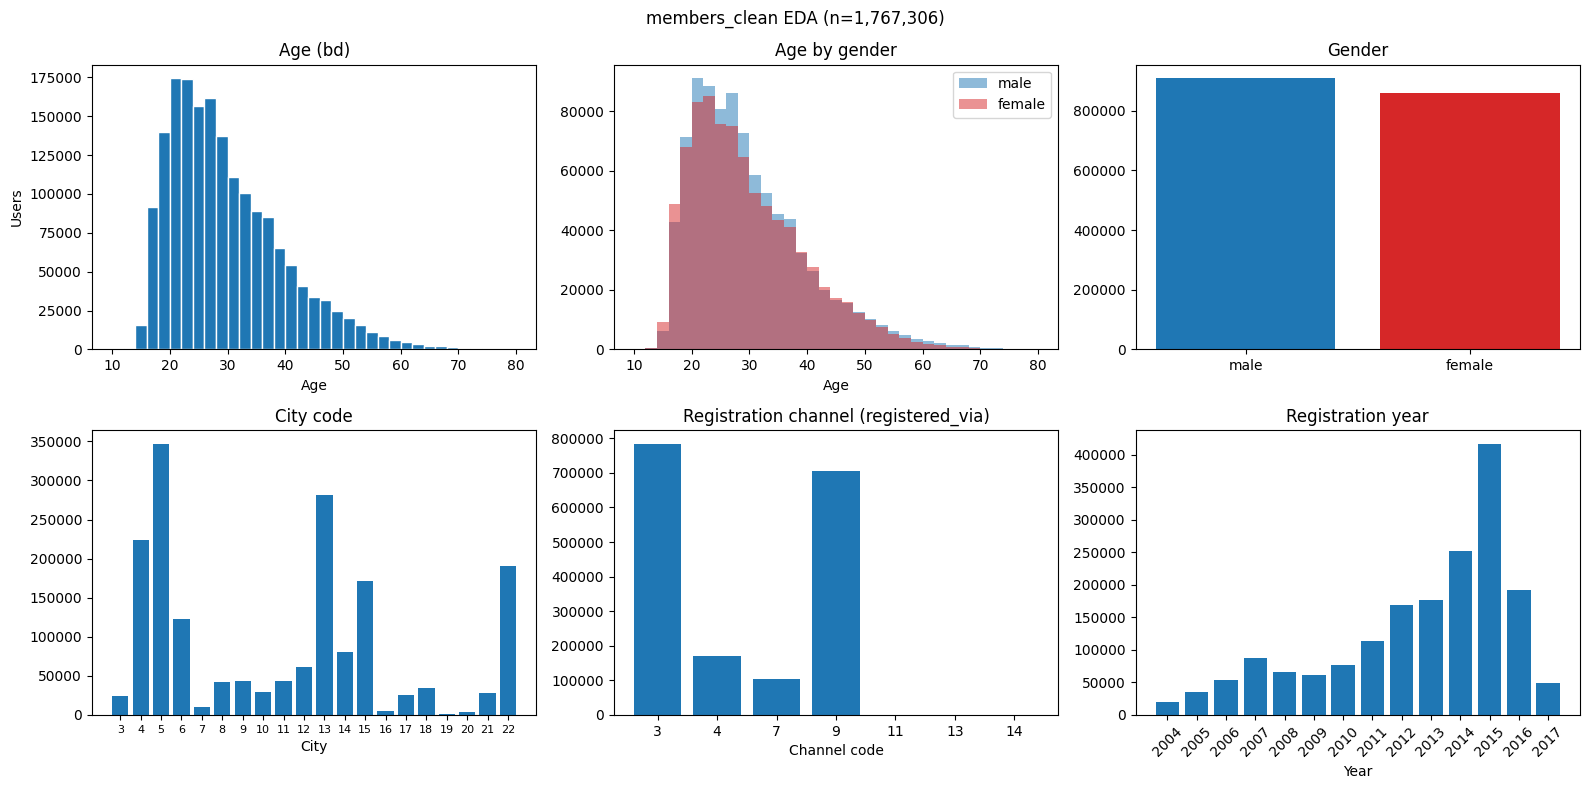

In [9]:
import matplotlib.pyplot as plt   # 그래프 그리는 도구

mc = members_clean.copy()
mc['reg_date'] = pd.to_datetime(mc['registration_init_time'].astype(str), format='%Y%m%d')
mc['reg_year'] = mc['reg_date'].dt.year

# 1) 숫자로 요약
print('나이(bd) 요약:')
print(mc['bd'].describe(percentiles=[.1, .25, .5, .75, .9]).round(1).to_string())
print('\n성별 비율:')
print(mc['gender'].value_counts(normalize=True).round(3).to_string())
print('\n성별 평균 나이:')
print(mc.groupby('gender')['bd'].mean().round(1).to_string())
print('\n도시 상위 5 (비율):')
print(mc['city'].value_counts(normalize=True).head(5).round(3).to_string())
print('\n가입 경로 (비율):')
print(mc['registered_via'].value_counts(normalize=True).round(3).to_string())

# 2) 분포 그래프 6개 (2행 × 3열)
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

# (1) 나이 분포
ax = axes[0, 0]
ax.hist(mc['bd'], bins=range(10, 82, 2), edgecolor='white')
ax.set_title('Age (bd)')
ax.set_xlabel('Age')
ax.set_ylabel('Users')

# (2) 성별 나이 분포 — 남녀가 나이대별로 다른가
ax = axes[0, 1]
for g, color in [('male', 'tab:blue'), ('female', 'tab:red')]:
    ax.hist(mc.loc[mc['gender'] == g, 'bd'], bins=range(10, 82, 2), alpha=0.5, color=color, label=g)
ax.set_title('Age by gender')
ax.set_xlabel('Age')
ax.legend()

# (3) 성별 인원
ax = axes[0, 2]
gender_counts = mc['gender'].value_counts()
ax.bar(gender_counts.index, gender_counts.values, color=['tab:blue', 'tab:red'])
ax.set_title('Gender')

# (4) 도시 코드별 인원 (번호는 크기가 아니라 그룹 번호)
ax = axes[1, 0]
city_counts = mc['city'].value_counts().sort_index()
ax.bar(city_counts.index.astype(str), city_counts.values)
ax.set_title('City code')
ax.set_xlabel('City')
ax.tick_params(axis='x', labelsize=8)

# (5) 가입 경로 코드별 인원
ax = axes[1, 1]
via_counts = mc['registered_via'].value_counts().sort_index()
ax.bar(via_counts.index.astype(str), via_counts.values)
ax.set_title('Registration channel (registered_via)')
ax.set_xlabel('Channel code')

# (6) 가입 연도별 인원
ax = axes[1, 2]
year_counts = mc['reg_year'].value_counts().sort_index()
ax.bar(year_counts.index.astype(str), year_counts.values)
ax.set_title('Registration year')
ax.set_xlabel('Year')
ax.tick_params(axis='x', rotation=45)

fig.suptitle(f'members_clean EDA (n={len(mc):,})')
plt.tight_layout()
plt.show()

**결과 해석**
- **나이**: 20대 초중반에 몰려 있고 오른쪽으로 꼬리가 긴 분포임. 중앙값 27세, 절반이 22~35세, 90%가 43세 이하 → 젊은 유저 중심 서비스.
- **성별**: 남 51%, 여 49%로 거의 반반이고, 남녀의 나이 분포도 거의 같음.
- **도시**: 5번(약 20%), 13번(16%), 4번(13%), 22번(11%), 15번(10%)이 많음. 이름은 비공개라 어느 도시인지는 알 수 없음.
- **가입 경로**: 3번(44%)과 9번(40%)이 대부분이고 4번·7번이 나머지. 11·13·14번은 거의 없음.
- **가입 연도**: 2004년부터 꾸준히 늘다가 **2015년에 가장 많고** 이후 줄어듦. 2017년은 4월까지만 있어서 적음.

⚠️ 이 데이터는 성별·나이·도시를 모두 입력한 **26%만**의 분포임. 입력하지 않은 74%와는 분포가 다를 수 있으므로 전체 유저의 특성으로 일반화하면 안 됨.

### 7-2. `members` 전체 EDA (결측 포함)
7-1과 같은 형식으로, 결측을 빼지 않은 전체 유저(약 677만 명)의 분포를 봄. 결측은 따로 범주로 표시함.
- 나이 0(미입력)과 10~80세 밖의 이상값은 따로 셈. 나이 히스토그램은 10~80세만 그림.
- 성별 빈칸은 `missing`, 도시 1번은 회색(정보 없음으로 추정).
- 마지막에 **가입 경로·가입 연도별 결측 비율**을 봄 → 결측이 무작위인지, 특정 집단에 몰리는지 확인.

전체 유저: 6,769,473
나이 0(미입력): 67.1%  /  0이 아닌 이상값(10~80 밖): 0.2%  /  정상: 32.8%

정상 범위 나이 요약 (10~80세만):
count    2218915.0
mean          29.4
std           10.2
min           10.0
10%           18.0
25%           22.0
50%           27.0
75%           35.0
90%           44.0
max           80.0

성별 비율 (missing = 빈칸):
gender_filled
missing    0.654
male       0.177
female     0.169

도시 상위 5 (비율):
city
1     0.710
5     0.057
13    0.047
4     0.036
22    0.031

가입 경로 (비율, 상위 5):
registered_via
4     0.413
3     0.243
9     0.219
7     0.119
11    0.004


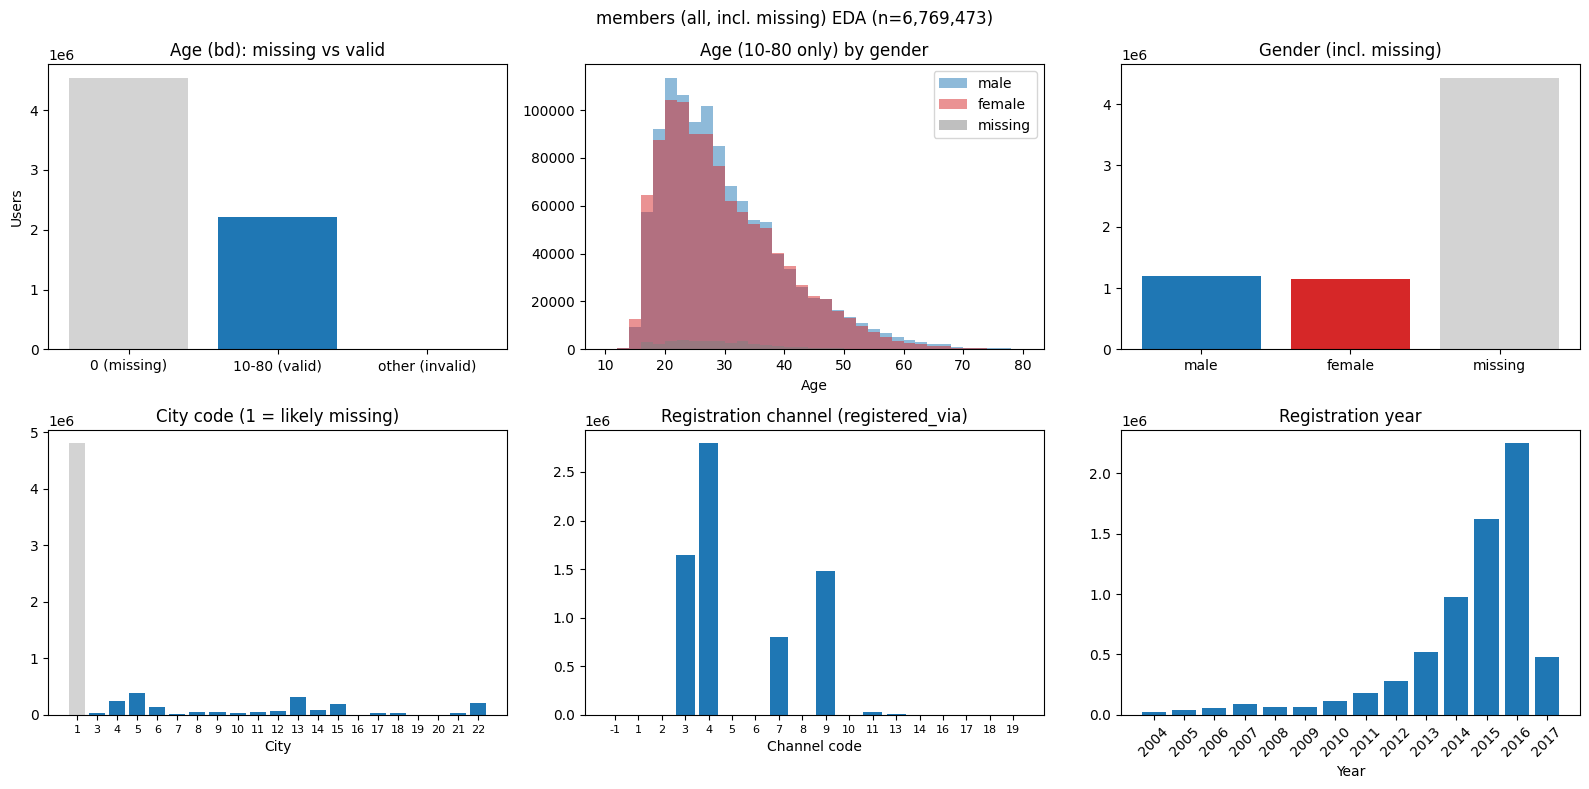


전체 결측 비율: 73.9%

가입 경로별 결측 비율 (1만 명 이상인 경로만):
                 rate    users
registered_via                
3               0.522  1643208
4               0.939  2793213
7               0.870   805895
9               0.524  1482863
11              0.999    25047

가입 연도별 결측 비율:
reg_year
2004    0.246
2005    0.155
2006    0.016
2007    0.020
2008    0.025
2009    0.045
2010    0.332
2011    0.369
2012    0.404
2013    0.664
2014    0.742
2015    0.743
2016    0.914
2017    0.899


In [10]:
import numpy as np                # 숫자 배열 계산 도구
import matplotlib.pyplot as plt   # 그래프 그리는 도구

ma = members.copy()
ma['reg_date'] = pd.to_datetime(ma['registration_init_time'].astype(str), format='%Y%m%d')
ma['reg_year'] = ma['reg_date'].dt.year
ma['gender_filled'] = ma['gender'].fillna('missing')           # 성별 빈칸을 'missing' 범주로 보이게 함
bd_ok = ma['bd'].between(10, 80)                                # 정상 나이 범위

# 1) 숫자로 요약 — 결측을 빼지 않았으므로 결측·이상값이 얼마나 있는지 먼저 봄
print(f'전체 유저: {len(ma):,}')
print(f"나이 0(미입력): {(ma['bd'] == 0).mean():.1%}  /  0이 아닌 이상값(10~80 밖): {(~bd_ok & (ma['bd'] != 0)).mean():.1%}  /  정상: {bd_ok.mean():.1%}")
print('\n정상 범위 나이 요약 (10~80세만):')
print(ma.loc[bd_ok, 'bd'].describe(percentiles=[.1, .25, .5, .75, .9]).round(1).to_string())
print('\n성별 비율 (missing = 빈칸):')
print(ma['gender_filled'].value_counts(normalize=True).round(3).to_string())
print('\n도시 상위 5 (비율):')
print(ma['city'].value_counts(normalize=True).head(5).round(3).to_string())
print('\n가입 경로 (비율, 상위 5):')
print(ma['registered_via'].value_counts(normalize=True).head(5).round(3).to_string())

# 2) 분포 그래프 6개 (2행 × 3열)
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

# (1) 나이 — 0(미입력)이 대부분이라 그대로 그리면 막대 하나만 보임 → 0·정상·이상값으로 나눠서 봄
ax = axes[0, 0]
bd_group = pd.Series(np.select([ma['bd'] == 0, bd_ok], ['0 (missing)', '10-80 (valid)'], 'other (invalid)'))
bd_counts = bd_group.value_counts().reindex(['0 (missing)', '10-80 (valid)', 'other (invalid)'])
ax.bar(bd_counts.index, bd_counts.values, color=['lightgray', 'tab:blue', 'tab:orange'])
ax.set_title('Age (bd): missing vs valid')
ax.set_ylabel('Users')

# (2) 정상 범위 나이 분포 (10~80세), 성별 빈칸도 함께 표시
ax = axes[0, 1]
for g, color in [('male', 'tab:blue'), ('female', 'tab:red'), ('missing', 'gray')]:
    ax.hist(ma.loc[bd_ok & (ma['gender_filled'] == g), 'bd'], bins=range(10, 82, 2), alpha=0.5, color=color, label=g)
ax.set_title('Age (10-80 only) by gender')
ax.set_xlabel('Age')
ax.legend()

# (3) 성별 인원 (빈칸 포함)
ax = axes[0, 2]
gender_counts = ma['gender_filled'].value_counts().reindex(['male', 'female', 'missing'])
ax.bar(gender_counts.index, gender_counts.values, color=['tab:blue', 'tab:red', 'lightgray'])
ax.set_title('Gender (incl. missing)')

# (4) 도시 코드별 인원 — 1번(정보 없음으로 추정)은 회색
ax = axes[1, 0]
city_counts = ma['city'].value_counts().sort_index()
ax.bar(city_counts.index.astype(str), city_counts.values,
       color=['lightgray' if c == 1 else 'tab:blue' for c in city_counts.index])
ax.set_title('City code (1 = likely missing)')
ax.set_xlabel('City')
ax.tick_params(axis='x', labelsize=8)

# (5) 가입 경로 코드별 인원
ax = axes[1, 1]
via_counts = ma['registered_via'].value_counts().sort_index()
ax.bar(via_counts.index.astype(str), via_counts.values)
ax.set_title('Registration channel (registered_via)')
ax.set_xlabel('Channel code')
ax.tick_params(axis='x', labelsize=8)

# (6) 가입 연도별 인원
ax = axes[1, 2]
year_counts = ma['reg_year'].value_counts().sort_index()
ax.bar(year_counts.index.astype(str), year_counts.values)
ax.set_title('Registration year')
ax.set_xlabel('Year')
ax.tick_params(axis='x', rotation=45)

fig.suptitle(f'members (all, incl. missing) EDA (n={len(ma):,})')
plt.tight_layout()
plt.show()

# 3) 결측이 특정 집단에 몰리나? — 가입 경로·가입 연도별 결측 비율 (결측 = 성별·나이·도시 중 하나라도 빠짐, 3절 기준과 같음)
ma['any_missing'] = ma['gender'].isna() | ~bd_ok | (ma['city'] == 1)
print(f"\n전체 결측 비율: {ma['any_missing'].mean():.1%}")
via_missing = ma.groupby('registered_via')['any_missing'].agg(rate='mean', users='size')
print('\n가입 경로별 결측 비율 (1만 명 이상인 경로만):')
print(via_missing[via_missing['users'] >= 10000].round(3).to_string())
print('\n가입 연도별 결측 비율:')
print(ma.groupby('reg_year')['any_missing'].mean().round(3).to_string())

**결과 해석 (7-1 결측 제거본과 비교)**

| 항목 | 전체 (결측 포함, 677만) | 결측 제거 (7-1, 177만) |
|---|---|---|
| 나이 | 67%가 0(미입력). 정상값만 보면 중앙값 27세 | 중앙값 27세 |
| 성별 | **65%가 빈칸**, 남 18% · 여 17% | 남 51% · 여 49% |
| 도시 | **1번이 71%**, 그다음 5·13·4·22번 | 5·13·4·22·15번 |
| 가입 경로 | **4번 41%**, 3번 24%, 9번 22%, 7번 12% | 3번 44%, 9번 40%, 4번 10% |
| 가입 연도 | **2016년이 가장 많음** | 2015년이 가장 많음 |

- **입력한 값끼리의 분포는 비슷함**: 정상 나이의 분포, 남녀 비율, 1번을 뺀 도시 순서는 결측 제거본과 거의 같음.
- **하지만 결측은 무작위가 아님**:
  - 가입 경로별 결측 비율: 4번 94%, 7번 87%, 11번 거의 100% vs 3번·9번 약 52%
  - 가입 연도별 결측 비율: 2006~2009년 가입자 2~5% → 2013년 이후 66~74% → 2016~2017년 약 90%
  - → 최근 가입자, 특정 가입 경로(4·7번)일수록 프로필을 입력하지 않음. 그래서 결측 제거본은 **오래된 가입자, 3·9번 경로 가입자 쪽으로 치우침**.
- **연구에 주는 의미**: 결측 행을 빼면 최근 가입자·4번 경로 유저가 크게 빠져 대표성이 깨짐 → 계획서대로 **결측을 "미입력" 범주로 남겨 두는 방식**이 맞음. "미입력"과 가입 경로·가입 연도가 서로 강하게 얽혀 있다는 점도 기대 모델 해석 때 고려해야 함.

### 7-3. 결측 있음 vs 결측 없음 — 가입 경로·가입 연도 비교
두 집단(`missing` 약 500만 명 / `complete` 약 177만 명)의 가입 경로·가입 연도 분포를 나란히 비교함.
- **집단 안 비율(share)**: 각 집단을 100%로 놓고 그 값이 차지하는 비율 → 집단 크기가 달라도 모양을 비교할 수 있음
- **결측 비율(missing_rate)**: 그 값을 가진 사람 중 결측인 사람의 비율

※ 7-2 코드 셀(`ma`, `any_missing`)을 먼저 실행해야 함.

                 users  share
missing_group                
missing        5002167  0.739
complete       1767306  0.261

가입 경로별 비교 (1만 명 이상 경로만):
                  users             share         missing_rate
missing_group  complete  missing complete missing             
registered_via                                                
3                784692   858516    0.444   0.172        0.522
4                171448  2621765    0.097   0.526        0.939
7                104789   701106    0.059   0.141        0.870
9                705987   776876    0.400   0.156        0.524
11                   37    25010    0.000   0.005        0.999

가입 연도별 비교:
                 users             share         missing_rate
missing_group complete  missing complete missing             
reg_year                                                     
2004             19770     6464    0.011   0.001        0.246
2005             34940     6409    0.020   0.001        0.155
2006             53098      

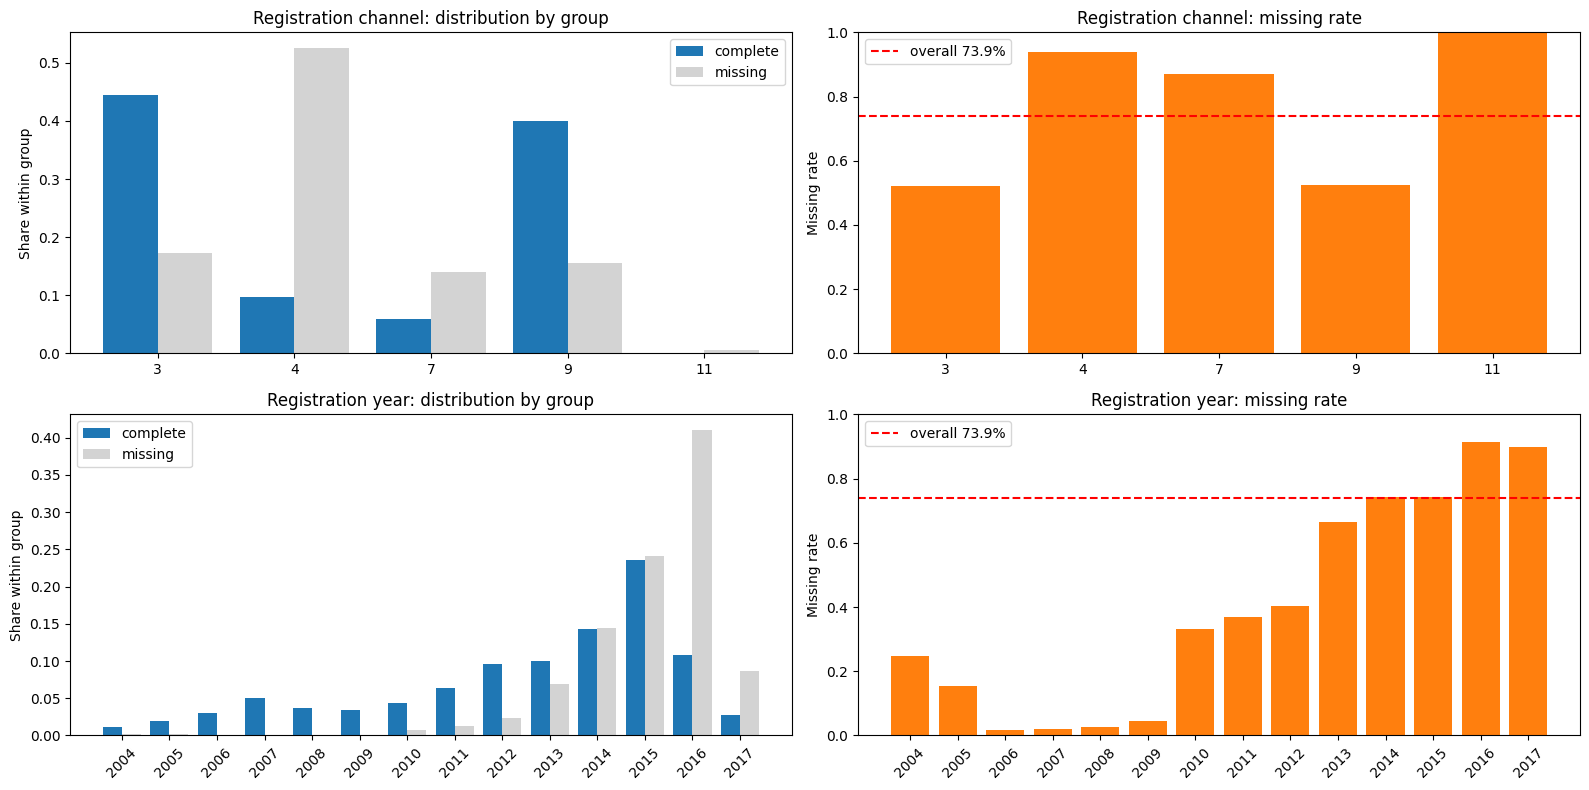

In [11]:
# 결측 있음 / 결측 없음 두 집단의 가입 경로·가입 연도 분포 비교
# 결측 기준은 3절과 같음 (성별 빈칸, 나이 0·10~80세 밖, 도시 1번 중 하나라도 해당)
ma['missing_group'] = np.where(ma['any_missing'], 'missing', 'complete')
print(ma['missing_group'].value_counts().to_frame('users').assign(share=lambda d: (d['users'] / d['users'].sum()).round(3)).to_string())

# 1) 집단별 분포표 — 인원(users)과 집단 안 비율(share). 비율은 각 집단을 100%로 놓고 계산
def compare(col, min_users=0):
    counts = pd.crosstab(ma[col], ma['missing_group'])                  # 행 = 값, 열 = 집단, 값 = 인원
    counts = counts[counts.sum(axis=1) >= min_users]                    # 너무 작은 값은 표에서 제외
    share = counts / counts.sum()                                       # 집단 안 비율 (열 합 = 100%)
    table = pd.concat({'users': counts, 'share': share.round(3)}, axis=1)
    table['missing_rate'] = (counts['missing'] / counts.sum(axis=1)).round(3)   # 이 값을 가진 사람 중 결측 비율
    return table, share

via_table, via_share = compare('registered_via', min_users=10000)
year_table, year_share = compare('reg_year')
print('\n가입 경로별 비교 (1만 명 이상 경로만):')
print(via_table.to_string())
print('\n가입 연도별 비교:')
print(year_table.to_string())

# 2) 그래프: 집단 안 비율을 나란히 놓고 비교 (막대 높이 = 그 집단에서 차지하는 비율)
# 위 줄 = 가입 경로, 아래 줄 = 가입 연도 / 왼쪽 = 집단별 분포, 오른쪽 = 값별 결측 비율
fig, axes = plt.subplots(2, 2, figsize=(16, 8))
colors = {'complete': 'tab:blue', 'missing': 'lightgray'}

for row, (share, table, title) in enumerate([(via_share, via_table, 'Registration channel'),
                                              (year_share, year_table, 'Registration year')]):
    # (왼쪽) 집단별 분포 — 두 집단의 막대를 나란히
    ax = axes[row, 0]
    x = np.arange(len(share))
    for i, g in enumerate(['complete', 'missing']):
        ax.bar(x + (i - 0.5) * 0.4, share[g], width=0.4, color=colors[g], label=g)
    ax.set_xticks(x)
    ax.set_xticklabels(share.index.astype(str), rotation=45 if row == 1 else 0)
    ax.set_ylabel('Share within group')
    ax.set_title(f'{title}: distribution by group')
    ax.legend()

    # (오른쪽) 값별 결측 비율 — 이 값을 가진 사람 중 몇 %가 결측인가
    ax = axes[row, 1]
    ax.bar(table.index.astype(str), table['missing_rate'], color='tab:orange')
    ax.axhline(ma['any_missing'].mean(), color='red', linestyle='--', label=f"overall {ma['any_missing'].mean():.1%}")
    ax.set_ylim(0, 1)
    ax.set_ylabel('Missing rate')
    ax.set_title(f'{title}: missing rate')
    ax.tick_params(axis='x', rotation=45 if row == 1 else 0)
    ax.legend()

plt.tight_layout()
plt.show()

**결과 해석**

| | 결측 없음 (complete, 26%) | 결측 있음 (missing, 74%) |
|---|---|---|
| 가장 많은 가입 경로 | **3번 44%, 9번 40%** | **4번 53%** (3번 17%, 9번 16%, 7번 14%) |
| 가장 많은 가입 연도 | 2015년 24%, 2014년 14% | **2016년 41%**, 2015년 24% |
| 2012년 이전 가입자 | 약 31% | 약 5% |

- **가입 경로**: 두 집단의 구성이 거의 뒤집혀 있음. 결측 없는 집단은 3·9번 경로가 84%인데, 결측 있는 집단은 4번 경로가 절반 이상임. 4번 경로 가입자의 94%, 11번은 거의 100%가 결측 → 이 경로는 가입 때 프로필을 받지 않는 방식일 가능성이 있음.
- **가입 연도**: 결측 없는 집단은 2004~2015년에 고르게 퍼져 있고, 결측 있는 집단은 2014~2017년에 몰려 있음. 결측 비율은 2006~2009년 2~5% → 2010~2012년 33~40% → 2013~2015년 66~74% → 2016~2017년 약 90%로 계단식으로 오름 → 시기에 따라 가입 절차(프로필 입력 여부)가 바뀌었을 가능성이 있음.
- **정리**: 결측은 무작위가 아니라 **가입 경로와 가입 시기에 따라 정해지는 구조적 결측**에 가까움. 결측 행을 빼면 최근 가입자와 4번 경로 유저가 대부분 사라지므로, 본 분석에서는 결측을 **"미입력" 범주로 유지**함. 또 "미입력"이 사실상 가입 경로·시기 정보를 함께 담고 있으므로, 기대 모델에서 이 변수들의 효과를 따로 해석할 때 주의해야 함.

## 8. N-Day 리텐션 분석
참고: [에어브릿지 블로그 — N-Day 리텐션](https://blog.ab180.co/posts/retention-series-3-1)

**N-Day 리텐션** = Day 0에 활동한 유저 중, **정확히 N일째 되는 날**에 다시 활동한 유저 비율
- 예: Day 3 리텐션은 **딱 3일째 되는 날** 재방문한 유저만 셈. 1·2일째나 4일째 이후에 온 건 Day 3에 포함되지 않음

이 분석에서의 정의
| 항목 | 정의 |
|---|---|
| 활동(액티브) 기준 | 그날 **음악을 재생함** = `user_logs`에 그날 기록이 있음 |
| Day 0 | **가입한 날** (`registration_init_time`) |
| 코호트 (분석 대상) | **2017년 3월에 가입하고, 가입 당일 음악을 재생한 유저** (가입일별로 묶음) |
| 분석 기간 | 2017-03-01 ~ 03-31 한 달 전체 |
| 핵심 지표 | **Day 3 리텐션** (+ Day 0~30 전체 곡선) |

⚠️ 3월 말에 가입한 유저는 Day N 날짜가 4월로 넘어가서 볼 수 없음. (예: 3/31 가입자는 Day 1부터 알 수 없음)
그래서 날짜별 결과를 합칠 때는 **Day N을 관측할 수 있는 코호트만 모아 가중 평균** 계산

In [12]:
import matplotlib.pyplot as plt   # 그래프 그리는 도구

# 1) 활동 기록: (유저, 음악 들은 날) — user_logs 한 줄이 곧 '그날 재생함'
active = user_logs[['msno', 'date']].copy()
active['date'] = pd.to_datetime(active['date'].astype(str), format='%Y%m%d')

# 2) 3월 가입자와 가입일(= Day 0)
new_users = members[(members['registration_init_time'] >= 20170301) &
                    (members['registration_init_time'] <= 20170331)][['msno', 'registration_init_time']].copy()
new_users['day0'] = pd.to_datetime(new_users['registration_init_time'].astype(str), format='%Y%m%d')

# 3) 가입자의 활동 기록에 'Day 몇'인지 붙이기 (Day N = 활동한 날 - 가입일)
logs = active.merge(new_users[['msno', 'day0']], on='msno')     # 3월 가입자의 활동만 남음
logs['day_n'] = (logs['date'] - logs['day0']).dt.days

# 4) 코호트 = 가입 당일(Day 0)에 음악을 재생한 유저
cohort_users = logs.loc[logs['day_n'] == 0, ['msno', 'day0']].drop_duplicates()
logs = logs[logs['msno'].isin(cohort_users['msno'])]

print('3월 가입자 수               :', len(new_users))
print('그중 가입 당일 재생한 유저(코호트):', len(cohort_users))

3월 가입자 수               : 99072
그중 가입 당일 재생한 유저(코호트): 75826


가입일별 N-Day 리텐션 (%) — 빈칸(NaN)은 3/31 이후라 관측 불가
day_n  users      0     1     2     3     4     5     6     7
day0                                                         
03-01   2420  100.0  48.2  41.1  34.2  23.3  15.5  12.8  12.4
03-02   2489  100.0  47.5  39.3  35.5  21.5  13.4  11.2  10.6
03-03   2714  100.0  49.7  39.6  33.2  21.8  12.8  10.1   9.5
03-04   3773  100.0  50.6  32.4  29.6  19.5  10.8   9.9  10.9
03-05   3596  100.0  40.1  33.9  30.6  18.7  12.0  10.6   9.3
03-06   2441  100.0  49.8  41.9  36.4  22.7  13.4  11.8  11.6
03-07   2430  100.0  48.9  41.8  37.0  23.3  13.2  11.7  10.1
03-08   2557  100.0  48.4  40.7  35.3  21.1  12.9   9.5   9.9
03-09   2520  100.0  47.8  40.7  35.8  21.5  12.7  10.4   9.9
03-10   2830  100.0  50.2  40.5  32.6  20.4  11.4   8.9   9.2
03-11   4048  100.0  51.8  34.7  30.1  19.7  11.1  10.1  10.6
03-12   3646  100.0  41.6  34.9  31.0  18.8  12.4  11.7  10.4
03-13   2577  100.0  48.3  41.2  37.9  23.4  14.1  11.8  11.2
03-14   2614  100.0  48.4

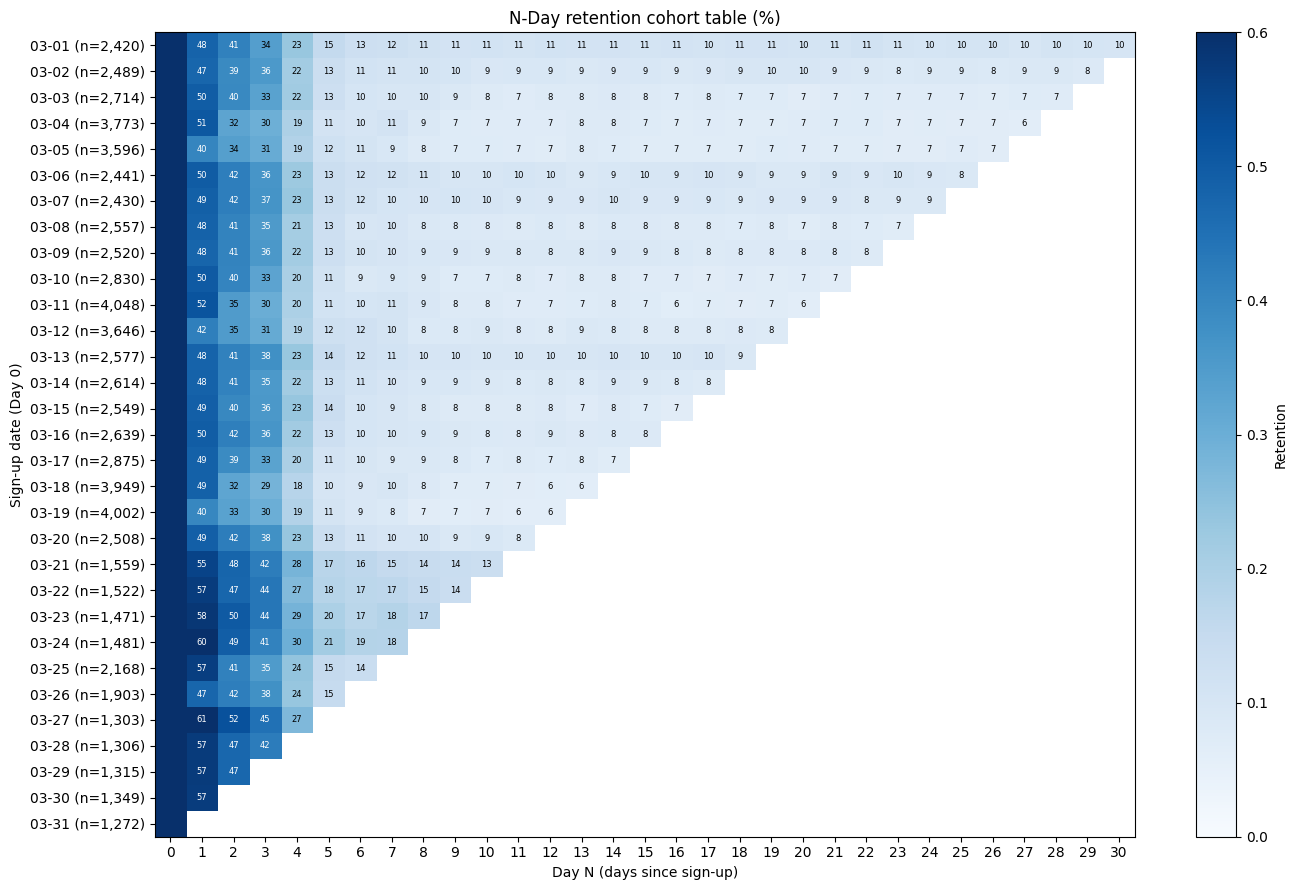

In [13]:
# 5) 코호트 표: 행 = 가입일(Day 0), 열 = Day 0 ~ 30, 값 = 그날 재방문한 비율
LAST_DATE = pd.Timestamp('2017-03-31')   # 데이터 마지막 날
MAX_N = 30

cohort_size = cohort_users.groupby('day0')['msno'].nunique()                 # 가입일별 코호트 인원
returned = logs.groupby(['day0', 'day_n'])['msno'].nunique().unstack()       # 가입일 × Day N 재방문 인원
returned = returned.reindex(columns=range(MAX_N + 1))

retention = returned.div(cohort_size, axis=0)       # 인원 → 비율

# 3월 31일을 넘어가는 칸은 아직 알 수 없는 날이므로 빈칸(NaN)으로 둠 (0%와 구분)
for d0 in retention.index:
    observable_days = (LAST_DATE - d0).days          # 이 코호트가 관측 가능한 마지막 Day
    retention.loc[d0, retention.columns > observable_days] = float('nan')

retention.index = retention.index.strftime('%m-%d')

# 표로 보기: 앞쪽 Day 0~7만 % 로 출력 (코호트 인원 users 포함)
table = (retention.loc[:, 0:7] * 100).round(1)
table.insert(0, 'users', cohort_size.values)
print('가입일별 N-Day 리텐션 (%) — 빈칸(NaN)은 3/31 이후라 관측 불가')
print(table.to_string())

# 히트맵으로 보기: Day 0~30 전체. 색이 진할수록 리텐션이 높음, 흰 칸은 관측 불가
fig, ax = plt.subplots(figsize=(14, 9))
im = ax.imshow(retention.values, cmap='Blues', vmin=0, vmax=0.6, aspect='auto')
ax.set_xticks(range(MAX_N + 1))
ax.set_xticklabels(range(MAX_N + 1))
ax.set_yticks(range(len(retention)))
ax.set_yticklabels([f'{d} (n={n:,})' for d, n in zip(retention.index, cohort_size.values)])
for i in range(retention.shape[0]):              # 칸마다 % 숫자 적기
    for j in range(retention.shape[1]):
        v = retention.values[i, j]
        if v == v and j > 0:                     # NaN이 아니고 Day 0(항상 100%)이 아닐 때만
            ax.text(j, i, f'{v*100:.0f}', ha='center', va='center', fontsize=6,
                    color='white' if v > 0.35 else 'black')
ax.set_xlabel('Day N (days since sign-up)')
ax.set_ylabel('Sign-up date (Day 0)')
ax.set_title('N-Day retention cohort table (%)')
fig.colorbar(im, ax=ax, label='Retention')
plt.tight_layout()
plt.show()

 day  cohorts  users retention
   0       31  75826    100.0%
   1       30  74554     49.4%
   2       29  73205     39.6%
   3       28  71890     34.6%
   7       24  65210     10.7%
  14       17  48718      8.5%
  21       10  27770      8.1%
  28        3   7623      8.7%
  30        1   2420     10.0%


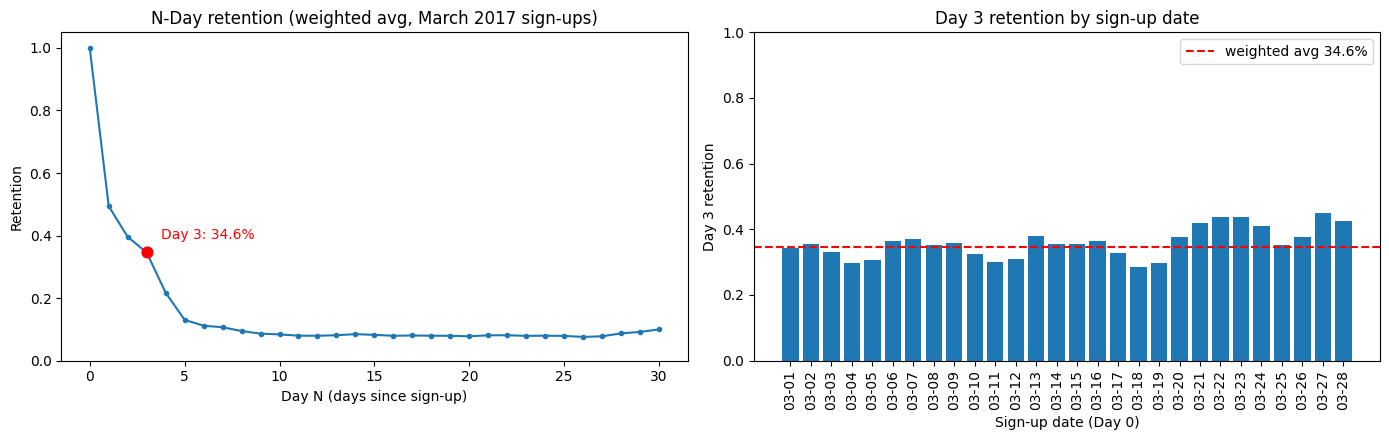

In [14]:
# 6) Day 0~30 가중 평균 곡선 + Day 3 리텐션
# 가중 평균: Day N을 관측할 수 있는 코호트만 모아 (재방문 인원 합) ÷ (코호트 인원 합)
curve = []
for n in range(MAX_N + 1):
    ok = [d0 for d0 in cohort_size.index if d0 + pd.Timedelta(days=n) <= LAST_DATE]   # Day N이 3월 안에 있는 코호트
    num = returned.loc[ok, n].fillna(0).sum()
    den = cohort_size.loc[ok].sum()
    curve.append({'day': n, 'cohorts': len(ok), 'users': den, 'retention': num / den})
curve = pd.DataFrame(curve)

print(curve[curve['day'].isin([0, 1, 2, 3, 7, 14, 21, 28, 30])].to_string(index=False, formatters={'retention': '{:.1%}'.format}))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# (왼쪽) N-Day 리텐션 곡선, Day 3 강조
ax = axes[0]
ax.plot(curve['day'], curve['retention'], marker='o', markersize=3)
d3 = curve.loc[curve['day'] == 3, 'retention'].iloc[0]
ax.scatter([3], [d3], color='red', zorder=3, s=60)
ax.annotate(f'Day 3: {d3:.1%}', (3, d3), textcoords='offset points', xytext=(10, 10), color='red')
ax.set_ylim(0, 1.05)
ax.set_xlabel('Day N (days since sign-up)')
ax.set_ylabel('Retention')
ax.set_title('N-Day retention (weighted avg, March 2017 sign-ups)')

# (오른쪽) 가입일별 Day 3 리텐션 (3/29 이후 가입자는 Day 3가 4월이라 없음)
day3 = retention[3].dropna()
ax = axes[1]
ax.bar(day3.index, day3.values)
ax.axhline(d3, color='red', linestyle='--', label=f'weighted avg {d3:.1%}')
ax.set_ylim(0, 1)
ax.set_xlabel('Sign-up date (Day 0)')
ax.set_ylabel('Day 3 retention')
ax.set_title('Day 3 retention by sign-up date')
ax.tick_params(axis='x', rotation=90)
ax.legend()

plt.tight_layout()
plt.show()

### 8-1. 결제 여부별 리텐션 — Day 4~5 급락은 무료 체험 종료 때문인가?

8절 곡선에서 Day 3 → Day 5 사이에 리텐션이 크게 꺾임. 무료 체험이 끝나는 시점인지 보려고, 코호트 유저를 **기준일(가입일)까지의 3월 결제 기록**으로 나눠 리텐션을 비교함.

| 그룹 | 정의 |
|---|---|
| 결제 없음 (`no_tx`) | 기준일까지 결제 기록이 하나도 없음 |
| 유료 결제 (`paid`) | 기준일까지의 첫 결제 금액이 0보다 큼 |
| 0원 결제 (`free`) | 기준일까지의 첫 결제가 0원 (무료 체험·프로모션 쿠폰 등) |

**기간을 기준일까지로 자르는 이유 (누수 방지)**: 8절의 기준일 t는 **가입일(Day 0)**임. 가입한 뒤에 한 결제로 그룹을 정하면 아직 결제 전이던 Day 1~3 리텐션에까지 미래 정보가 섞임. 실제로 결제 기록이 있는 9,868명 중 **2,943명(29.8%)은 첫 결제가 가입 이후**였음 (Day 4 이후만 1,977명). 3월로 자르는 것은 병합본(2015~2017)의 과거 기록을 배제하려는 것이나, 이 코호트에서 3월 이전 결제 보유자는 6명뿐임.

※ 8절 첫 두 코드 셀(`cohort_users`, `logs`, `LAST_DATE`)을 먼저 실행해야 함.

그룹별 인원:
       users   share
group               
no_tx  68901  0.9087
paid    6507  0.0858
free     418  0.0055

0원 첫 결제의 구독 기간(일) 상위:
payment_plan_days
30     194
60      68
7       59
240     57
120     26
10       5
90       4
14       4

[검증] 기간 무제한 → 기준일까지로 제한했을 때의 그룹 이동 (명):
기준일까지   free  no_tx  paid
기간 무제한                   
free     418    177     3
no_tx      0  65958     0
paid       0   2766  6504
가입 후에 처음 결제해 no_tx로 옮겨진 유저: 2,943명

결제 그룹별 N-Day 리텐션 (%):
day       0     1     2     3     4     5     6     7     8     9     10    11    12    13    14
group                                                                                           
free   100.0  83.5  78.2  73.9  67.8  71.1  70.0  73.3  68.1  66.7  65.2  60.7  59.5  60.4  65.9
no_tx  100.0  46.3  36.3  31.2  17.3   8.0   6.1   5.5   4.4   3.9   3.7   3.4   3.4   3.4   3.6
paid   100.0  80.3  72.7  69.8  68.1  66.3  66.3  67.5  65.8  62.7  63.0  62.0  62.4  62.8  64.1


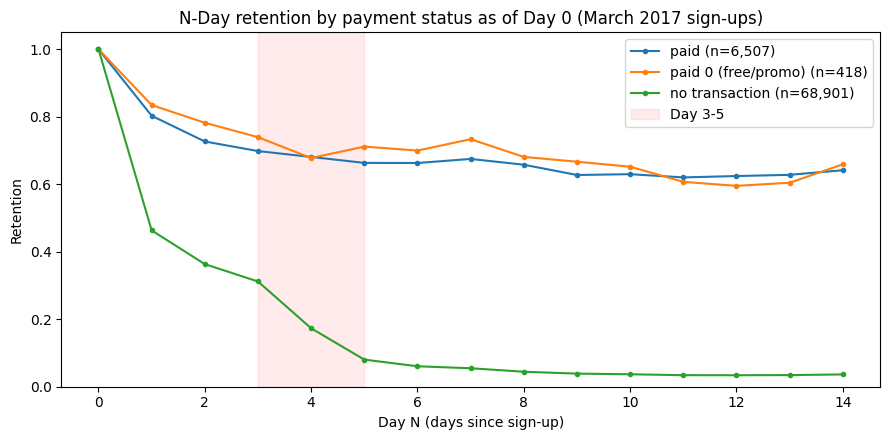

In [15]:
# 1) 코호트 유저의 결제 기록 중 '기준일(가입일)까지의 3월 결제'만 남겨 첫 결제를 찾음
# 결제 기록은 필요한 컬럼만 읽음 (전체를 올리면 1.9GB)
_tx_all = pd.read_parquet('data/transactions_all.parquet',
                          columns=['msno', 'transaction_date', 'actual_amount_paid', 'payment_plan_days'])
tx = _tx_all[_tx_all['msno'].isin(cohort_users['msno'])].copy()
del _tx_all
tx['tdate'] = pd.to_datetime(tx['transaction_date'].astype(str), format='%Y%m%d')
tx = tx.merge(cohort_users[['msno', 'day0']], on='msno')        # 유저별 기준일(= 가입일) 붙임

# 누수 방지: 기준일 t(가입일)까지 관측 가능한 결제만 씀. 가입 당일 결제는 t 시점 정보라 포함함
MARCH_START = pd.Timestamp('2017-03-01')
tx_elig = tx[(tx['tdate'] >= MARCH_START) & (tx['tdate'] <= tx['day0'])]
first_tx = tx_elig.sort_values(['msno', 'tdate']).groupby('msno').first()

# 2) 결제 그룹 붙이기: 기록 없음 / 0원 결제 / 유료 결제
pay = cohort_users.copy()
pay['group'] = 'no_tx'                                                 # 기본값 = 결제 없음
paid_amount = pay['msno'].map(first_tx['actual_amount_paid'])          # 기준일까지의 첫 결제 금액 (없으면 NaN)
pay.loc[paid_amount == 0, 'group'] = 'free'
pay.loc[paid_amount > 0, 'group'] = 'paid'
print('그룹별 인원:')
print(pay['group'].value_counts().to_frame('users').assign(share=lambda d: (d['users'] / d['users'].sum()).round(4)).to_string())

# 0원 결제의 구독 기간 — 7~14일처럼 짧으면 체험, 30일 이상이면 쿠폰·프로모션에 가까움
print()
print('0원 첫 결제의 구독 기간(일) 상위:')
print(first_tx.loc[first_tx['actual_amount_paid'] == 0, 'payment_plan_days'].value_counts().head(8).to_string())

# 검증) 기간 제한을 안 걸었을 때와 비교 — 미래 결제로 분류됐던 인원이 얼마나 옮겨졌는지 확인함
_new = pay.set_index('msno')['group']
_first_any = tx.sort_values(['msno', 'tdate']).groupby('msno').first()  # 기간 무제한일 때의 첫 결제
_old = pd.Series('no_tx', index=_new.index)
_amt_any = _first_any['actual_amount_paid']
_old[_amt_any.index[_amt_any == 0]] = 'free'
_old[_amt_any.index[_amt_any > 0]] = 'paid'
print()
print('[검증] 기간 무제한 → 기준일까지로 제한했을 때의 그룹 이동 (명):')
print(pd.crosstab(_old, _new, rownames=['기간 무제한'], colnames=['기준일까지']).to_string())
print(f"가입 후에 처음 결제해 no_tx로 옮겨진 유저: {((_old != 'no_tx') & (_new == 'no_tx')).sum():,}명")

# 3) 그룹별 N-Day 리텐션 (Day 0~14, Day N을 관측할 수 있는 유저만 분모로 씀 — 8절과 같은 가중 평균)
logs_g = logs.merge(pay[['msno', 'group']], on='msno')
rows = []
for g, users in pay.groupby('group'):
    for n in range(15):
        ok = users[users['day0'] + pd.Timedelta(days=n) <= LAST_DATE]      # Day N이 3월 안에 있는 유저
        came = logs_g[(logs_g['group'] == g) & (logs_g['day_n'] == n) & logs_g['msno'].isin(ok['msno'])]['msno'].nunique()
        rows.append({'group': g, 'day': n, 'retention': came / len(ok)})
by_group = pd.DataFrame(rows).pivot(index='group', columns='day', values='retention')
print()
print('결제 그룹별 N-Day 리텐션 (%):')
print((by_group * 100).round(1).to_string())

# 4) 그래프: 결제 없음 그룹만 Day 3~5에 급락하는지 확인
labels = {'no_tx': 'no transaction', 'paid': 'paid', 'free': 'paid 0 (free/promo)'}
fig, ax = plt.subplots(figsize=(9, 4.5))
for g in ['paid', 'free', 'no_tx']:
    ax.plot(by_group.columns, by_group.loc[g], marker='o', markersize=3,
            label=f"{labels[g]} (n={(pay['group'] == g).sum():,})")
ax.axvspan(3, 5, color='red', alpha=0.08, label='Day 3-5')
ax.set_ylim(0, 1.05)
ax.set_xlabel('Day N (days since sign-up)')
ax.set_ylabel('Retention')
ax.set_title('N-Day retention by payment status as of Day 0 (March 2017 sign-ups)')
ax.legend()
plt.tight_layout()
plt.show()

**결과 해석**
- **코호트의 90.9%는 가입일까지 결제 기록이 없음.** 유료 결제 8.6%, 0원 결제 0.6%.
- **Day 3~5 급락은 결제 없음 그룹에서만 나타남**: 31% → 17% → 8%로 떨어지고 Day 10쯤엔 3.7%. 유료·0원 결제 그룹은 처음 며칠만 조금 내려가고 약 66~70%에서 평평함.
- 8절의 "Day 30에 약 10%만 남음"은 **가입일까지 결제한 9%가 대부분 남고, 결제 안 한 91%가 거의 다 떠난 결과**임.
- **무료 체험 종료인가?** 0원 결제 중 7~14일짜리는 소수이고 대부분 30일 이상(쿠폰·프로모션에 가까움) → 체험 기간이 결제 기록으로 남지 않음. 결제 없는 유저가 특정 시점(3~5일째)에 몰려서 떠나는 모양은 **기록되지 않은 며칠짜리 무료 이용 기간이 끝나는 것과 맞지만, 데이터로 직접 확인은 불가**함.
- **기간 제한의 영향**: 기간을 안 자르던 이전 방식과 비교하면 곡선의 모양(결제 없음 그룹만 급락)은 그대로이고, `no_tx` 수준만 조금 올라감 (Day 3 29% → 31%, Day 5 5% → 8%). 가입 후에 결제해 실제로는 남았던 2,943명이 `no_tx`로 들어왔기 때문임 → **결론은 바뀌지 않으면서 누수만 제거됨**.

**연구에 주는 의미**: 신규 유저 리텐션은 결제 여부로 거의 갈림 → 신규 유저 보조 분석에서 이 효과가 다른 요인을 덮을 수 있음.
또 구독 관련 변수(자동 연장 여부, 요금제 기간, 할인 여부, 결제 수단, 만료까지 남은 일수)는 **결제 기록이 있어야 계산되는 값**이라, 결제 기록이 없는 유저는 이 값들이 전부 빔.
이때 "결제 기록 없음"은 단순한 결측이 아니라 **아직 돈을 내지 않은 상태라는 분명한 정보**이므로, 기대 모델에서 버리지 말고 하나의 값으로 두어 모델이 쓸 수 있게 해야 함.
단, 이 값들도 **기준일 t까지의 결제 기록만으로 계산**해야 함 — 위 비교처럼 t 이후의 결제를 쓰면 결과를 미리 아는 셈이 됨.

### 8-2. 유저 특성별 리텐션 — 어느 특성이 집단을 가르나

7절에서 유저 특성(B군: 도시·연령대·성별·가입 경로)의 **분포와 결측 구조**를 봤음. 이 절은 그 특성이 **리텐션과 어떤 관계인지**를 봄. 기대 모델의 설명 변수로서, 그리고 집단 탐색의 축으로서 B군이 쓸 만한지 판단하는 근거임.

두 각도에서 같은 질문을 던짐.

| | 대상 | 결과 변수 | 뜻 |
|---|---|---|---|
| **[A]** | 3월 신규 코호트 (75,826명) | **N-Day 리텐션** (Day 1~30) | 새로 온 유저가 어떻게 빠져나가나 |
| **[B]** | 3월 활동 유저 전체 (110만 명) × 기준일 | **D1** | **기대 모델이 실제로 예측할 대상** (계획서 7.1의 주 분석 단위) |

비교 잣대는 **스프레드**임 (13절과 같은 정의).

> **스프레드 = 가장 높은 칸의 리텐션 − 가장 낮은 칸의 리텐션**
> 그 특성 하나가 유저를 얼마나 갈라놓는가. 다만 칸이 작으면 우연히 벌어질 수 있어 **칸의 인원도 같이 봐야 함** (여기서는 코호트 300명·전체 2만 행 미만인 칸은 제외).

특성 라벨은 **7-3절과 같은 기준**으로 만듦 — 결측은 지우지 않고 **"미입력(unknown)"이라는 하나의 값**으로 둠. 7-3절에서 결측이 가입 경로·가입 시기와 강하게 얽혀 있어 결측 행을 빼면 특정 집단이 통째로 사라지는 것을 확인했기 때문임.

| 특성 | 값 |
|---|---|
| `city` | 1번(= 정보 없음) / 많은 순 5개 / 기타 |
| `age` | 10대 / 20대 / 30대 / 40대+ / 미입력(10~80세 밖) |
| `gender` | male / female / 미입력 |
| `channel` | 가입 경로 3·4·7·9번 / 기타 / 미입력 |
| `profile` | 입력 / 미입력 (성별·나이·도시 중 하나라도 비면 미입력) |

분모 처리: [A]의 Day N 리텐션은 **그날을 관측할 수 있는 유저만** 분모로 씀 (가입일 + N ≤ 3/31). 3월 하순 가입자는 Day 14·30을 아직 볼 수 없으므로, 이를 분모에 넣으면 리텐션이 낮게 나옴 (8절과 같은 방식).

※ 8절 첫 코드 셀(`cohort_users`, `logs`, `LAST_DATE`)을 먼저 실행해야 함. [B]는 9절이 만들어 두는 `data/cache/` 를 파일에서 직접 읽으므로, 캐시가 없으면 [B]만 건너뛰고 나머지는 그대로 돌아감.

신규 코호트 75,826명에 특성 라벨을 붙임 (members에 없는 유저는 unknown)

[A-city] 특성별 N-Day 리텐션 (분모 = Day N을 관측할 수 있는 코호트 유저)
             users     D1     D3     D5     D7    D14    D30
group                                                       
unknown (1)  65331 0.4685 0.3211 0.1091 0.0842 0.0614 0.0676
other         3298 0.6457 0.5129 0.2830 0.2858 0.3092    NaN
city 5        2266 0.6342 0.4843 0.2557 0.2603 0.3085    NaN
city 4        1563 0.6477 0.4985 0.2496 0.2551 0.2949    NaN
city 22       1302 0.6622 0.5087 0.2656 0.2629 0.3006    NaN
city 13       1087 0.7283 0.5986 0.4146 0.4430 0.4578    NaN
city 15        979 0.6688 0.5126 0.2882 0.3141 0.3465    NaN

[A-age] 특성별 N-Day 리텐션 (분모 = Day N을 관측할 수 있는 코호트 유저)
         users     D1     D3     D5     D7    D14    D30
group                                                   
unknown  61276 0.4626 0.3171 0.1101 0.0852 0.0610 0.0664
20s       5714 0.6631 0.5178 0.2901 0.2964 0.3252    NaN
10s       4068 0.6837 0.5165 0.2126 0.2002 0.2291    NaN
30s    

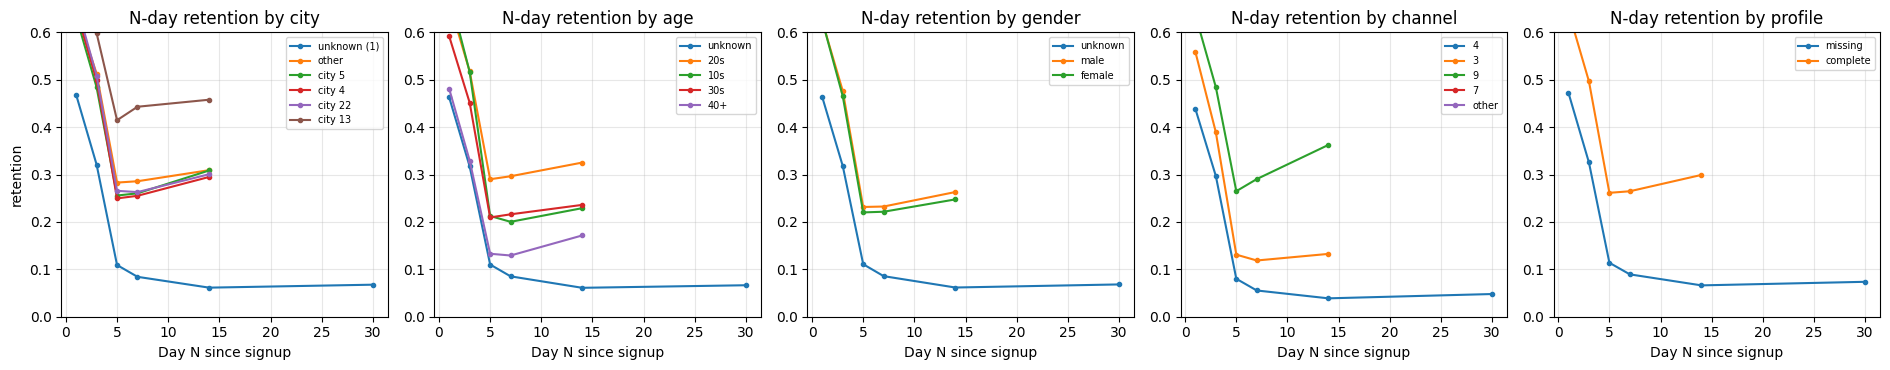

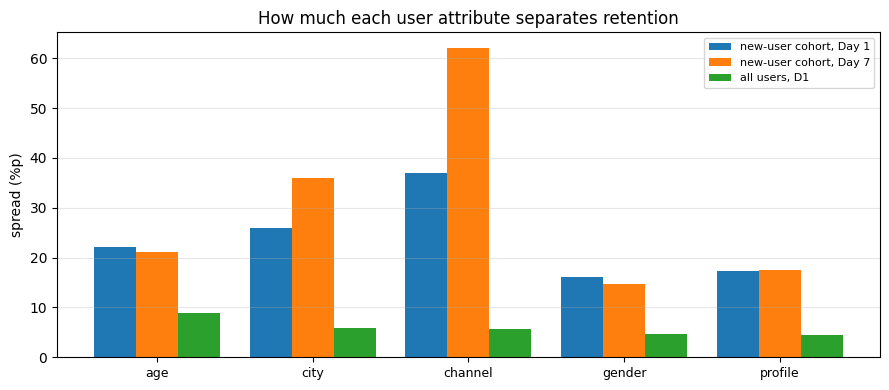

In [28]:
import numpy as np                # 숫자 배열 계산 도구
import matplotlib.pyplot as plt   # 그래프 그리는 도구

# 유저 특성(B군)이 리텐션을 얼마나 가르는지 봄. 두 각도에서 같은 질문을 던짐.
#   [A] 신규 코호트의 N-Day 리텐션 — "새로 온 유저가 어떻게 빠져나가나"
#   [B] 전체 유저의 D1 (유저 × 기준일) — "기대 모델이 실제로 예측할 대상"
# 비교 잣대는 13절과 같은 **스프레드**(가장 높은 칸 − 가장 낮은 칸)를 씀

# ── 1) 특성 라벨 만들기 (11절 users와 같은 기준이되, 이 절이 먼저라 여기서 다시 정의함) ──
FEATS = ['city', 'age', 'gender', 'channel', 'profile']


def label(df):
    """members 행에 특성 라벨 5개를 붙임. '미입력'은 지우지 않고 하나의 값으로 둠 (7-3절 결론)"""
    out = pd.DataFrame(index=df.index)
    # 도시: 1번은 입력한 행에서 19%뿐이라 '정보 없음'으로 봄 (7-2절). 나머지는 많은 순으로 5개 + 기타
    _top = df.loc[df['city'] != 1, 'city'].value_counts().head(5).index
    out['city'] = np.where(df['city'] == 1, 'unknown (1)',
                           np.where(df['city'].isin(_top), 'city ' + df['city'].astype(str), 'other'))
    # 나이: 10~80세 밖은 입력하지 않은 것으로 봄
    _bd = df['bd']
    out['age'] = np.select([~_bd.between(10, 80), _bd < 20, _bd < 30, _bd < 40],
                           ['unknown', '10s', '20s', '30s'], '40+')
    out['gender'] = df['gender'].fillna('unknown')
    # 가입 경로: 3·4·7·9번이 대부분이라 그것만 따로 두고 나머지는 묶음
    out['channel'] = df['registered_via'].map(
        lambda v: str(int(v)) if v in (3, 4, 7, 9) else ('unknown' if pd.isna(v) else 'other'))
    # 프로필 입력 여부: 7-3절과 같은 기준 (성별·나이·도시 중 하나라도 비면 미입력)
    out['profile'] = np.where(df['registered_via'].isna(), 'unknown',
                              np.where(df['gender'].isna() | ~_bd.between(10, 80) | (df['city'] == 1),
                                       'missing', 'complete'))
    return out


_mi = members.set_index('msno')
_cf = label(_mi.loc[_mi.index.isin(cohort_users['msno'])])
coh = cohort_users.set_index('msno').join(_cf, how='left').reset_index()
for c in FEATS:
    coh[c] = coh[c].fillna('unknown')
print('신규 코호트 {:,}명에 특성 라벨을 붙임 (members에 없는 유저는 unknown)'.format(len(coh)))

# ── 2) [A] 특성별 N-Day 리텐션 ────────────────────────────────────────
# 분모는 8-1절과 같은 방식 — Day N을 관측할 수 있는 유저(day0 + N ≤ 3/31)만 셈
DAYS = [1, 3, 5, 7, 14, 30]
_lg = logs.merge(coh[['msno'] + FEATS], on='msno')
nday = {}
for f in FEATS:
    _rows = []
    for g, sub in coh.groupby(f):
        _ok = sub.set_index('msno')['day0']
        _r = {'group': g, 'users': len(sub)}
        for n in DAYS:
            _den = (_ok + pd.Timedelta(days=n) <= LAST_DATE)
            _elig = set(_ok.index[_den])
            if len(_elig) < 300:                       # 너무 작은 집단은 비워 둠
                _r[f'D{n}'] = np.nan
                continue
            _ret = _lg[(_lg[f] == g) & (_lg['day_n'] == n) & (_lg['msno'].isin(_elig))]['msno'].nunique()
            _r[f'D{n}'] = _ret / len(_elig)
        _rows.append(_r)
    nday[f] = pd.DataFrame(_rows).set_index('group').sort_values('users', ascending=False)
    print(f'\n[A-{f}] 특성별 N-Day 리텐션 (분모 = Day N을 관측할 수 있는 코호트 유저)')
    print(nday[f].to_string(float_format='{:.4f}'.format))

# ── 3) [B] 전체 유저 × 기준일의 D1 ────────────────────────────────────
# 9절이 만들어 둔 정수 키 캐시를 파일에서 바로 읽음 (이 절이 9절보다 앞이라 변수를 못 씀)
import os
_CACHE = 'data/cache/active_keys.npz'
_has_cache = os.path.exists(_CACHE) and os.path.exists('data/cache/active_users.parquet')
if not _has_cache:
    print('\n[B] 건너뜀 — data/cache 가 없음. 9절 코드 셀을 한 번 실행하면 캐시가 만들어짐')
else:
    _z = np.load(_CACHE)
    _key = _z['key_all']
    _uniq = pd.read_parquet('data/cache/active_users.parquet')['msno']
    _d = (_key % 64).astype('int16')
    _u = (_key // 64).astype('int32')
    _b = _d <= 29                                      # 기준일 3/1~3/30 (3/31은 결과일이 없음)
    _bk, _bu = _key[_b], _u[_b]
    _pos = np.searchsorted(_key, _bk + 1)              # 같은 유저의 다음 날이 있나 = D1
    base_d1 = ((_pos < len(_key)) & (_key[np.minimum(_pos, len(_key) - 1)] == _bk + 1)).astype(float)
    _af = label(_mi.reindex(_uniq))                    # 3월 활동 유저 전체의 특성 라벨
    print('\n[B] 기준일 행 {:,} / 유저 {:,}명 / 전체 D1 {:.4f}'.format(
        len(_bu), len(_uniq), base_d1.mean()))
    allg = {}
    for f in FEATS:
        _v = _af[f].to_numpy()[_bu]
        _t = pd.DataFrame({'g': _v, 'd1': base_d1}).groupby('g')['d1'].agg(rows='size', D1='mean')
        _t['share'] = _t['rows'] / len(_bu)
        allg[f] = _t[['rows', 'share', 'D1']].sort_values('rows', ascending=False)
        print(f'\n[B-{f}] 특성별 D1 (전체 유저 × 기준일)')
        print(allg[f].to_string(float_format='{:.4f}'.format))

# ── 4) [C] 스프레드 순위 — 어느 특성이 가장 잘 가르나 ──────────────────
# 스프레드 = 가장 높은 칸 − 가장 낮은 칸 (13절과 같은 정의). 칸이 작으면 우연히 벌어지므로 칸 수도 같이 봄
print('\n' + '=' * 78)
print('[C] 특성별 스프레드 (%p) — 클수록 그 특성 하나로 집단이 잘 갈림')
print('=' * 78)
_rows = []
for f in FEATS:
    _r = {'특성': f, '칸 수': len(nday[f])}
    for n in (1, 7):
        _c = nday[f][f'D{n}'].dropna()
        _c = _c[nday[f].loc[_c.index, 'users'] >= 300]
        _r[f'코호트 D{n}'] = (_c.max() - _c.min()) * 100 if len(_c) > 1 else np.nan
    if _has_cache:
        _c = allg[f]
        _c = _c[_c['rows'] >= 20000]['D1']
        _r['전체 D1'] = (_c.max() - _c.min()) * 100 if len(_c) > 1 else np.nan
    _rows.append(_r)
spread_b = pd.DataFrame(_rows).sort_values('전체 D1' if _has_cache else '코호트 D1', ascending=False)
print(spread_b.to_string(index=False, float_format='{:.1f}'.format))
print('\n참고) 같은 잣대로 잰 다른 변수: 평소 습관 ① 활동일 수 48.6%p, 기준일까지의 결제 기록 29.4%p (12·13절)')

# ── 5) [D] 특성끼리 얽힘 — 따로 해석하면 안 되는 이유 ──────────────────
print('\n' + '=' * 78)
print('[D] 가입 경로 × 프로필 입력 여부 (전체 3월 활동 유저)')
print('=' * 78)
if _has_cache:
    _x = pd.crosstab(_af['channel'], _af['profile'], normalize='index')
    print((_x * 100).round(1).to_string())
    print('\n→ 가입 경로마다 미입력 비율이 크게 달라, "프로필 미입력"의 효과와 "가입 경로"의 효과를 따로 떼기 어려움')

# ── 6) 그래프 ─────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 5, figsize=(19, 3.8))
for ax, f in zip(axes, FEATS):
    _t = nday[f]
    for g in _t.index[:6]:
        ax.plot(DAYS, [_t.loc[g, f'D{n}'] for n in DAYS], marker='o', markersize=3, label=str(g))
    ax.set_title(f'N-day retention by {f}')
    ax.set_xlabel('Day N since signup')
    ax.set_ylim(0, 0.6)
    ax.grid(alpha=.3)
    ax.legend(fontsize=7)
axes[0].set_ylabel('retention')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
_w = 0.27
_x = np.arange(len(spread_b))
for i, (col, lab) in enumerate([('코호트 D1', 'new-user cohort, Day 1'),
                                ('코호트 D7', 'new-user cohort, Day 7'),
                                ('전체 D1', 'all users, D1')]):
    if col in spread_b:
        ax.bar(_x + (i - 1) * _w, spread_b[col].fillna(0), _w, label=lab)
ax.set_xticks(_x); ax.set_xticklabels(spread_b['특성'], fontsize=9)
ax.set_ylabel('spread (%p)')
ax.set_title('How much each user attribute separates retention')
ax.legend(fontsize=8); ax.grid(axis='y', alpha=.3)
plt.tight_layout()
plt.show()

**결과 해석**

**(1) 가장 큰 발견 — 신규 유저에서는 아주 강하고, 전체 유저에서는 약하다**

| 특성 | 코호트 D1 | 코호트 D7 | **전체 유저 D1** |
|---|---|---|---|
| **가입 경로** | 37.0%p | **62.1%p** | 5.6%p |
| 도시 | 26.0%p | 35.9%p | 5.8%p |
| 연령대 | 22.1%p | 21.1%p | **8.9%p** |
| 프로필 입력 여부 | 17.2%p | 17.5%p | 4.4%p |
| 성별 | 16.1%p | 14.7%p | 4.7%p |
| *(참고) 평소 습관 ① 활동일 수* | — | — | ***48.6%p*** |
| *(참고) 기준일까지의 결제 기록* | — | — | ***29.4%p*** |

👉 계획서에 "유저 특성(B)은 결측이 많아 설명력이 약하다"고 적었는데, 정확히는 이렇습니다.

- **주 분석(전체 유저 × 기준일)에서는 맞음** — 4.4~8.9%p로, 습관(48.6%p)·결제 기록(29.4%p)에 한참 못 미침
- **신규 유저 보조 실험에서는 틀림** — 가입 경로 하나가 Day 7 리텐션을 **62%p**나 가름

**(2) 가입 경로가 신규 유저 리텐션을 지배함**

| 가입 경로 | 코호트 인원 | Day 1 | Day 3 | **Day 7** | Day 14 |
|---|---|---|---|---|---|
| **4번** | 53,011 (**70%**) | 0.439 | 0.297 | **0.055** | 0.039 |
| 3번 | 10,036 | 0.559 | 0.389 | 0.119 | 0.133 |
| 9번 | 8,293 | 0.637 | 0.484 | 0.290 | 0.363 |
| **7번** | 4,057 | **0.765** | **0.659** | **0.628** | 0.607 |

- **경로 4번이 코호트의 70%** 를 차지하는데 Day 7에 **5.5%** 만 남습니다. 반면 **7번은 62.8%** 로 거의 떨어지지 않습니다 — **11배 차이**
- 8절에서 본 "Day 3~5 급락"은 사실상 **경로 4번 집단의 현상**입니다. 8-1절에서 "결제 없음 그룹에서만 급락"이라고 했는데, 그 집단과 경로 4번이 크게 겹칩니다
- 경로 7번은 Day 1부터 Day 14까지 0.77 → 0.61로 거의 평평 → **다른 성격의 유입 경로**로 보입니다

**(3) ⚠️ 가장 주의해야 할 결과 — 가입 경로의 방향이 집단에 따라 뒤집힌다**

| 가입 경로 | 코호트 비중 | 코호트 Day 7 | 전체 유저 행 비중 | 전체 유저 D1 |
|---|---|---|---|---|
| **7번** | 5.4% | **0.628 (1위)** | 37.9% | **0.7537 (4위)** |
| 3번 | 13.2% | 0.119 (3위) | 17.1% | **0.8098 (1위)** |
| 9번 | 10.9% | 0.290 (2위) | 35.3% | 0.8016 (2위) |
| **4번** | **69.9%** | 0.055 (4위) | 9.5% | 0.7681 (3위) |

**경로 7번은 신규 코호트에서 1위인데 전체 유저에서는 네 경로 중 꼴찌입니다.** 경로 3번은 그 반대입니다.
두 집단의 구성이 완전히 달라서 생기는 역전입니다 — 코호트는 경로 4번이 69.9%인데 전체 행에서는 9.5%뿐입니다.
→ **어느 한쪽에서 얻은 "경로 7번은 좋다/나쁘다"를 다른 쪽으로 옮길 수 없습니다.**

그래서 **"미입력이 리텐션을 낮춘다"는 해석도 성립하지 않습니다.**

| 가입 경로 | 프로필 미입력 비율 | 코호트 Day 7 | 전체 유저 D1 |
|---|---|---|---|
| 3번 | 24.2% | 0.119 | 0.8098 |
| **4번** | **75.0%** | 0.055 | 0.7681 |
| **7번** | **83.2%** | **0.628** | **0.7537** |
| 9번 | 21.1% | 0.290 | 0.8016 |

전체 유저에서 미입력 칸의 D1이 낮은 것(0.7583 vs 0.8024)은 사실이지만, 가입 경로마다 미입력 비율이
24%~83%로 크게 달라 **미입력의 효과와 경로의 효과를 떼어낼 수 없습니다.** 실제로 신규 코호트에서는
미입력이 83.2%인 경로 7번이 리텐션 **1위**입니다.

→ 7-3절에서 "결측은 가입 경로·가입 시기와 강하게 얽혀 있다"고 한 것의 **리텐션 쪽 증거**입니다. 계획서의 "**유저 특성(B)의 효과는 따로 해석하지 않는다**"는 결정이 이 결과로 뒷받침됩니다.

**(4) 전체 유저에서는 연령대가 그나마 가장 큼**

| 연령대 | 행 비중 | D1 |
|---|---|---|
| **10대** | 5.3% | **0.844** |
| 20대 | 30.2% | 0.817 |
| 30대 | 14.8% | 0.768 |
| 40대+ | 6.2% | 0.777 |
| 미입력 | 43.6% | 0.755 |

8.9%p로 B군 중 1위지만, **행의 43.6%가 "미입력"** 이라 실제로 쓸 수 있는 범위가 좁습니다. 미입력을 뺀 입력 집단 안에서는 0.768~0.844로 **7.6%p**입니다.

도시·성별·프로필도 모두 **"미입력" 칸이 가장 낮고**(0.750~0.755), 입력한 값들끼리는 차이가 작습니다(도시 0.798~0.808, 성별 0.8020 vs 0.8019로 **사실상 동일**).

**연구에 주는 의미**

| | |
|---|---|
| 기대 모델 | B군은 주 분석에서 설명력이 약하므로 **넣되 기대는 낮게.** 습관(D)·구독 상태(C)가 주력이라는 계획서 6.3의 판단이 수치로 확인됨 |
| 집단 탐색 | B군 조건은 **해석 가능하지만 신호가 약함.** 다만 "미입력" 칸이 일관되게 낮으므로 **미입력 플래그**는 조건으로 쓸 가치가 있음 |
| 보조 실험 (신규 유저) | **가입 경로를 반드시 넣어야 함.** Day 7 기준 62%p를 가르므로, 빼면 신규 유저 쪽 결과가 통째로 왜곡됨 |
| 해석 주의 | 특성끼리 강하게 얽혀 있고(경로 ↔ 미입력) **집단에 따라 방향까지 뒤집히므로 단일 변수 해석은 금지.** 집단 탐색이 단일 조건이 아니라 조합 조건을 찾는 이유이기도 함 |

## 9. 결과 시점 선택: D1 vs D7

본 분석의 결과 변수를 "며칠 뒤 재방문"으로 할지 정하기 위해 두 가지를 확인함.
1. 유저들이 음악을 **얼마나 자주** 듣는가 (3월 활동일 수)
2. 기준일 뒤 **며칠째를 보느냐**에 따라 재방문율이 어떻게 달라지는가
   - **정확히 N일 뒤**: t+N일에 들었나 (N-Day 방식)
   - **N일 안에 한 번이라도**: t+1 ~ t+N일 중 하루라도 들었나

결론(계획서 6.2): 정확히 N일째 재방문율은 D1과 D7이 비슷하고, "N일 안에" 방식은 천장 효과가 있음 → **주 결과는 D1, D7은 민감도 확인용**.

3월 활동 유저 수: 1,103,894
count    1103894.0
mean          16.7
std           10.3
min            1.0
10%            2.0
25%            7.0
50%           18.0
75%           26.0
90%           30.0
max           31.0
거의 매일(25일 이상): 31.5%  /  가끔(5일 이하): 22.2%


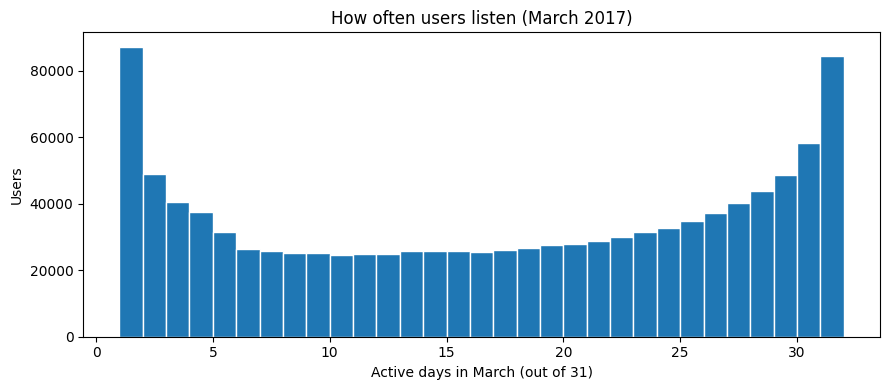

In [16]:
# 1) 유저별 3월 활동일 수 — "음악을 얼마나 자주 듣나"
# (유저, 음악 들은 날) 한 줄씩. user_logs는 원래 하루 한 줄로 정리돼 있어 중복이 없으므로
# (11절에서 확인: 1,840만 행 → 중복 제거 후에도 1,840만 행) 중복 제거를 생략함 — 1~2분 절약
active = user_logs[['msno', 'date']].copy()
active['date'] = pd.to_datetime(active['date'].astype(str), format='%Y%m%d')

active_days = active.groupby('msno')['date'].nunique()                 # 유저별 활동일 수 (최대 31일)
print('3월 활동 유저 수:', f'{len(active_days):,}')
print(active_days.describe(percentiles=[.1, .25, .5, .75, .9]).round(1).to_string())
print(f"거의 매일(25일 이상): {(active_days >= 25).mean():.1%}  /  가끔(5일 이하): {(active_days <= 5).mean():.1%}")

# 활동일 수 분포 그래프
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(active_days, bins=range(1, 33), edgecolor='white')
ax.set_xlabel('Active days in March (out of 31)')
ax.set_ylabel('Users')
ax.set_title('How often users listen (March 2017)')
plt.tight_layout()
plt.show()

캐시에서 불러옴: data/cache/active_keys.npz
기준 행 수: 8,210,278
           기준  재방문율
정확히 1일 뒤 (D1) 77.8%
정확히 2일 뒤 (D2) 75.5%
정확히 3일 뒤 (D3) 74.7%
정확히 7일 뒤 (D7) 75.4%
 3일 안에 한 번이라도 92.5%
 7일 안에 한 번이라도 97.2%


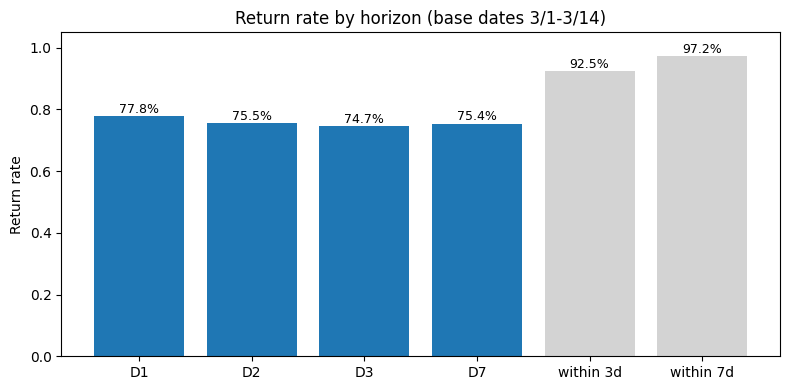

In [17]:
import numpy as np   # 숫자 배열 계산 도구

# 2) 며칠 뒤로 보느냐에 따른 재방문율
# 대상: 기준일 3/1~3/14에 음악을 들은 (유저, 기준일) 행 — 계획서의 정상 기간
#
# (유저, 날짜)를 정수 키 하나로 바꿔 두고 "그날 기록이 있나"를 이진 탐색으로 찾음.
# 표를 합치는 방식(merge)은 1,840만 줄 × 820만 줄을 10번 반복해야 해서 메모리가 모자람.
# 결과는 합치기 방식과 완전히 같음.
# 키를 만드는 데 1~2분 걸리는데 결과는 늘 같으므로 data/cache 에 저장해 두고 다음부터는 읽어 씀.
# 데이터가 바뀌면 행 수가 달라지므로 그때는 자동으로 다시 만듦.
import os
os.makedirs('data/cache', exist_ok=True)
_cache = 'data/cache/active_keys.npz'

_users_cache = 'data/cache/active_users.parquet'

if os.path.exists(_cache) and os.path.exists(_users_cache) and np.load(_cache)['n'][0] == len(active):
    _z = np.load(_cache)
    code, day, key_all = _z['code'], _z['day'], _z['key_all']
    uniq = pd.read_parquet(_users_cache)['msno']          # 유저 번호 → msno 대응표
    print('캐시에서 불러옴:', _cache)
else:
    code, uniq = pd.factorize(active['msno'])                                # 유저를 0, 1, 2… 번호로 바꿈
    day = (active['date'] - pd.Timestamp('2017-03-01')).dt.days.to_numpy()   # 3/1을 0일로 둔 날짜 번호
    key_all = np.sort(code.astype('int64') * 64 + day)                       # 활동한 (유저, 날) 키 — 정렬해 둠
    code, day = code.astype('int32'), day.astype('int8')                     # 저장 용량을 줄임
    uniq = pd.Series(uniq, name='msno')
    np.savez(_cache, code=code, day=day, key_all=key_all, n=np.array([len(active)]))
    uniq.to_frame().to_parquet(_users_cache, compression='zstd', index=False)
    print('캐시를 새로 만듦:', _cache)

# code는 user_logs의 각 행이 어느 유저인지를 가리킴 (active가 user_logs와 같은 순서·길이라서 성립)
assert len(code) == len(user_logs)

in_base = ((active['date'] >= '2017-03-01') & (active['date'] <= '2017-03-14')).to_numpy()
base_code, base_day = code[in_base], day[in_base]
n_base = int(in_base.sum())

def was_active(n):
    """기준일 t에 들은 행마다, t+n일에도 들었는지 (True/False 배열)"""
    k = base_code.astype('int64') * 64 + (base_day + n)
    i = np.searchsorted(key_all, k)                 # k가 들어갈 자리를 찾음
    i[i >= len(key_all)] = len(key_all) - 1         # 범위를 넘으면 마지막 칸으로 (아래에서 불일치 처리됨)
    return key_all[i] == k                          # 그 자리 값이 k와 같으면 그날 활동한 것

def exact_return(n):
    """기준일 t에 들은 행 중, 정확히 t+n일에도 들은 비율"""
    return was_active(n).mean()

def within_return(w):
    """기준일 t에 들은 행 중, t+1 ~ t+w일 안에 한 번이라도 들은 비율"""
    returned = np.zeros(n_base, dtype=bool)
    for n in range(1, w + 1):                       # 하루씩 확인해서 한 번이라도 있으면 True
        returned |= was_active(n)
    return returned.mean()

rows = [{'기준': f'정확히 {n}일 뒤 (D{n})', '재방문율': exact_return(n)} for n in [1, 2, 3, 7]]
rows += [{'기준': f'{w}일 안에 한 번이라도', '재방문율': within_return(w)} for w in [3, 7]]
horizon = pd.DataFrame(rows)
print(f'기준 행 수: {n_base:,}')
print(horizon.to_string(index=False, formatters={'재방문율': '{:.1%}'.format}))

# 막대그래프: 정확히 N일 뒤(파랑) vs N일 안에 한 번이라도(회색)
colors = ['tab:blue'] * 4 + ['lightgray'] * 2
labels = ['D1', 'D2', 'D3', 'D7', 'within 3d', 'within 7d']
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(labels, horizon['재방문율'], color=colors)
for i, v in enumerate(horizon['재방문율']):
    ax.text(i, v + 0.01, f'{v:.1%}', ha='center', fontsize=9)
ax.set_ylim(0, 1.05)
ax.set_ylabel('Return rate')
ax.set_title('Return rate by horizon (base dates 3/1-3/14)')
plt.tight_layout()
plt.show()

**결과 해석**
- **정확히 N일 뒤** 방식은 D1과 D7이 거의 같음 → 기간이 길어도 값이 크게 떨어지지 않음 (습관적으로 듣는 사람은 어느 날이든 비슷한 확률로 잡힘).
- **N일 안에 한 번이라도** 방식은 7일이면 거의 모두가 돌아와서(천장 효과) 하락이 드러나지 않음 → 사용하지 않음.
- 데이터가 1개월뿐이므로 평가 기간을 길게 쓰고 학습·평가 결과일의 겹침이 적은 **D1을 주 결과**로, **D7은 민감도 확인용**으로 씀.

## 10. 요일·월말 효과 확인

정상 기간(3/1~3/14)과 평가 기간(3/15~3/30)을 **시간 순서로** 나누기 때문에, 날짜에 따라 재방문율이 원래 달라지는 효과(요일, 월초·월말)가 있으면 평가 기간 편차에 섞일 수 있음. 그래서 두 가지를 확인함.
1. **기준일별 D1 재방문율**: 요일 효과, 한 달 동안의 완만한 변화, 월말 효과가 있는가
2. **구독 만료일 분포**: 만료(결제·갱신)가 월말에 몰리는가

※ 9절에서 만든 `active`와 정수 키(`code`, `day`, `key_all`)를 쓰므로 **9절 코드 셀 두 개를 먼저 실행**해야 함.

참고: 날짜를 무작위로 섞어 정상/평가 기간을 나누면 평가 기간의 이상이 학습에 섞여 "정상"으로 배워지므로, 기간은 반드시 시간 순서로 나눔.

               DAU     D1 weekday
2017-03-01  575889  0.794     Wed
2017-03-02  580623  0.793     Thu
2017-03-03  590594  0.752     Fri
2017-03-04  584124  0.767     Sat
2017-03-05  589177  0.745     Sun
2017-03-06  577955  0.791     Mon
2017-03-07  579079  0.793     Tue
2017-03-08  581288  0.796     Wed
2017-03-09  584919  0.794     Thu
2017-03-10  597915  0.756     Fri
2017-03-11  592497  0.773     Sat
2017-03-12  598768  0.750     Sun
2017-03-13  587823  0.794     Mon
2017-03-14  589627  0.799     Tue
2017-03-15  592706  0.799     Wed
2017-03-16  595837  0.799     Thu
2017-03-17  608931  0.756     Fri
2017-03-18  597723  0.774     Sat
2017-03-19  604289  0.760     Sun
2017-03-20  602846  0.800     Mon
2017-03-21  603087  0.804     Tue
2017-03-22  604399  0.805     Wed
2017-03-23  606033  0.796     Thu
2017-03-24  608478  0.751     Fri
2017-03-25  590241  0.768     Sat
2017-03-26  591254  0.761     Sun
2017-03-27  592870  0.805     Mon
2017-03-28  599412  0.805     Tue
2017-03-29  60

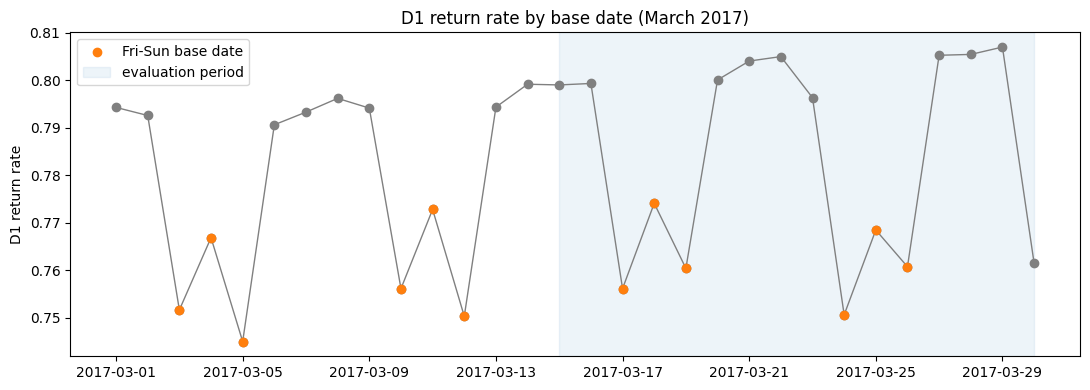

In [18]:
# 1) 기준일별 D1 재방문율 — 요일·월말 효과 확인
# 9절에서 만든 정수 키(code, day, key_all)를 그대로 써서 모든 행의 D1 여부를 구함.
# 표를 합치면 1,840만 줄끼리 맞붙어 메모리가 모자람 (9절 둘째 셀 참고).
k_next = code.astype('int64') * 64 + (day + 1)                   # 다음 날의 (유저, 날) 키
i = np.searchsorted(key_all, k_next)
i[i >= len(key_all)] = len(key_all) - 1
hit_next = key_all[i] == k_next                                  # 다음 날 들었으면 True
d1_by_date = pd.Series(hit_next, index=active['date'].to_numpy()).groupby(level=0).mean()   # 기준일별 D1

daily = pd.DataFrame({'DAU': active.groupby('date').size(),                      # 그날 음악을 들은 유저 수
                      'D1': d1_by_date}).loc['2017-03-01':'2017-03-30']         # 3/31은 다음 날이 없어 제외
daily['weekday'] = daily.index.day_name().str[:3]
print(daily.round(3).to_string())

# 요일별 평균 D1 — 요일 효과가 얼마나 큰가
print('\n요일별 평균 D1:')
print(daily.groupby('weekday')['D1'].mean()
           .reindex(['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']).round(3).to_string())

# 그래프: 금·토·일 기준일은 주황색, 평가 기간은 파란 배경
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(daily.index, daily['D1'], marker='o', color='gray', linewidth=1)
weekend = daily['weekday'].isin(['Fri', 'Sat', 'Sun'])
ax.scatter(daily.index[weekend], daily['D1'][weekend], color='tab:orange', zorder=3, label='Fri-Sun base date')
ax.axvspan(pd.Timestamp('2017-03-15'), pd.Timestamp('2017-03-30'), color='tab:blue', alpha=0.08, label='evaluation period')
ax.set_ylabel('D1 return rate')
ax.set_title('D1 return rate by base date (March 2017)')
ax.legend()
plt.tight_layout()
plt.show()

만료 건수가 가장 많은 날 (상위 8):
membership_expire_date
2017-03-31    124589
2017-04-30    117210
2017-03-01     40062
2017-03-06     39652
2017-04-06     37836
2017-04-01     37279
2017-03-16     36580
2017-03-04     36209

하루 평균 만료 건수: 34,159건


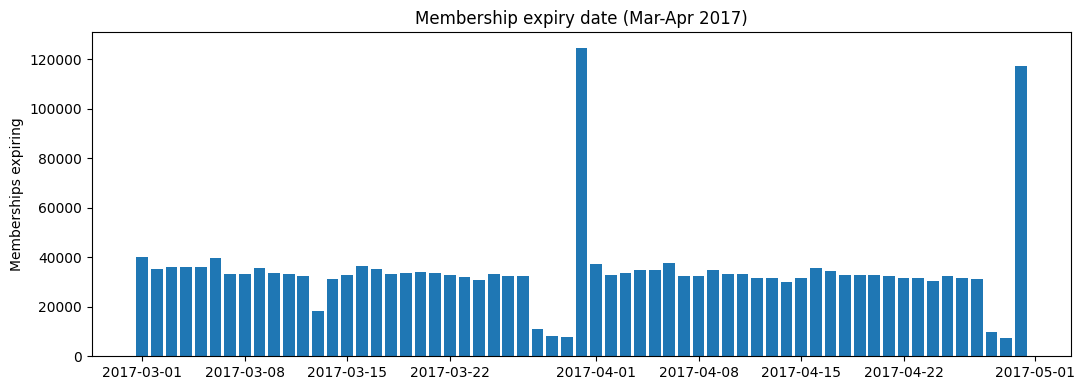

In [19]:
# 2) 구독 만료일 분포 — 만료(결제·갱신)가 월말에 몰리나?
# 만료일 컬럼 하나만 읽음
_exp = pd.read_parquet('data/transactions_all.parquet', columns=['membership_expire_date'])
expire = pd.to_datetime(_exp['membership_expire_date'].astype(str), format='%Y%m%d', errors='coerce')
del _exp
expire = expire[(expire >= '2017-03-01') & (expire <= '2017-04-30')]   # 3~4월 만료분만
counts = expire.value_counts().sort_index()

print('만료 건수가 가장 많은 날 (상위 8):')
print(counts.sort_values(ascending=False).head(8).to_string())
print(f'\n하루 평균 만료 건수: {counts.mean():,.0f}건')

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(counts.index, counts.values, width=0.8)
ax.set_ylabel('Memberships expiring')
ax.set_title('Membership expiry date (Mar-Apr 2017)')
plt.tight_layout()

plt.show()

**결과 해석**
- **요일 효과 (강함)**: 금·토·일 기준일은 D1이 약 75~77%, 월~목은 약 79~81%로 매주 반복됨 → 기대 모델의 요일 변수(기준일 요일, 결과일 요일)로 흡수함.
- **월중 완만한 상승 (약함)**: 같은 요일끼리 비교하면 한 달 동안 약 1%p 상승 → 평가 기간 편차가 전체적으로 약간 양수로 나올 수 있음. 피팅 절차 ④(평가 기간 전체의 p 평균과 실제 평균 비교)에서 확인함.
- **3/30 기준일만 낮음**: 다른 목요일(약 80%)보다 약 4%p 낮음(3/31에 덜 돌아옴). 월말 효과인지 데이터가 3/31에서 잘려서인지는 3월 데이터만으로 구분할 수 없음.
- **만료일이 월말에 몰림**: 4/30 만료가 다른 날의 약 3배 → 월말에 결제·갱신 관련 행동이 달라질 수 있으며, "만료까지 남은 일수" 변수로 일부 반영함.

**결정**: 일단 3월 데이터만 사용하고, 분석 중 월말 효과가 문제가 되면 v1 청취 기록(1~2월)을 추가해 확인함.

## 11. 이용 주기 EDA
유저들이 **얼마나 자주, 며칠 간격으로** 음악을 듣는지 봄. 하루에 여러 번 들어도 **(유저, 날짜) 한 줄 = 활동 1번**으로 셈.

| 지표 | 정의 |
|---|---|
| 활동일 수 | 3월 31일 중 음악을 들은 날 수 |
| 재방문 간격 (gap) | 같은 유저의 연속된 두 활동일 사이 일수 (1 = 다음 날 또 들음) |
| 이용 주기 유형 | 유저별 간격 **중앙값**으로 나눔: 매일형(1일) / 2~3일 / 주간형(4~7일) / 8일 이상 / 하루만 활동(간격 없음) |
| 활동 비율 | 활동일 수 ÷ 관측 가능 일수 (3월 신규 가입자는 가입일부터 3/31까지만 관측되므로 보정용) |

주요 코호트
- **가입 경과 기간 (tenure)**: 3월 신규 / 1년 미만 / 1~3년 / 3년 이상 (3/1 기준)
- **가입 경로 (channel)**: 주요 4개 경로 3·4·7·9번
- **프로필 입력 여부 (profile)**: 7-3절 기준 complete / missing

※ 9절 코드 셀 두 개(`code`, `day`, `key_all`, `uniq`)를 먼저 실행해야 함.
⚠️ 관측 기간이 3월 한 달뿐이라 8일 이상 긴 간격은 잘 안 잡힘(관측 기간 끝에서 잘림).

user_logs 행 수: 18,396,362 → (유저, 날짜) 중복 제거 후: 18,396,362  (원래 하루 한 줄이라 중복이 없음)
검증 통과: 표본 5명의 활동일 수가 원본과 일치

3월 활동 유저: 1,103,894명

유저별 3월 활동일 수:
count    1103894.0
mean          16.7
std           10.3
min            1.0
10%            2.0
25%            7.0
50%           18.0
75%           26.0
90%           30.0
max           31.0

재방문 간격 분포 (모든 간격 기준, 상위 7일):
gap
1    0.805
2    0.104
3    0.039
4    0.018
5    0.011
6    0.007
7    0.005
8일 이상: 1.1%

이용 주기 유형 (유저 기준):
cycle
daily (1d)       0.676
2-3d             0.162
4-7d (weekly)    0.057
8d+              0.027
single day       0.079


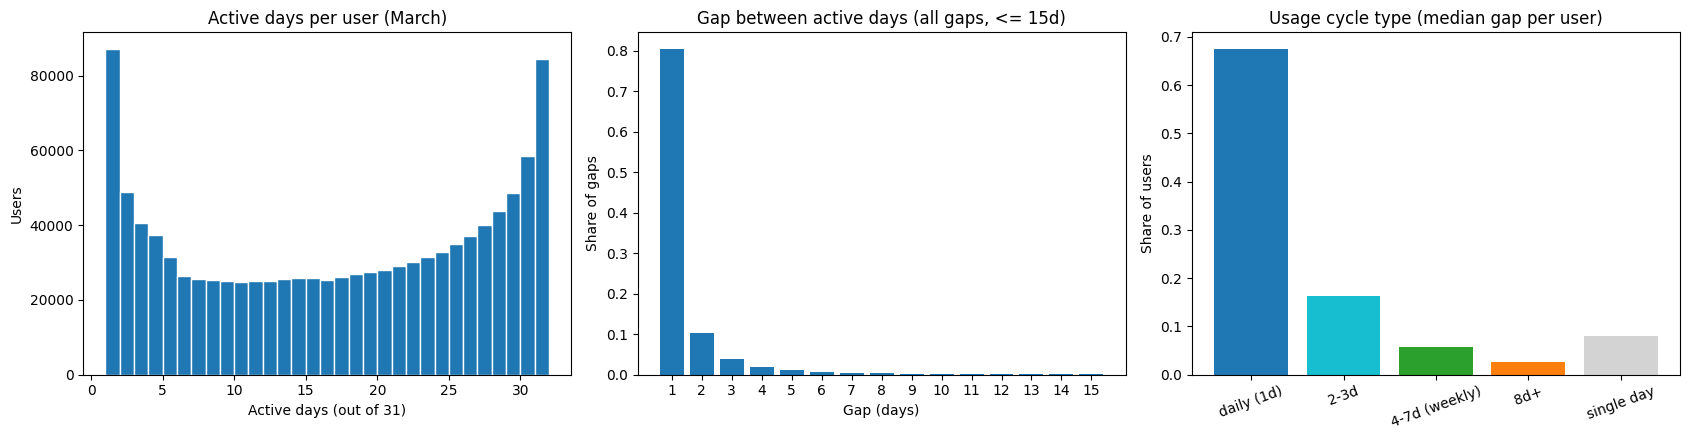


[tenure] 코호트별 요약:
                 users  active_days_median  active_ratio_mean  mean_gap
tenure                                                                 
new (Mar 2017)   90951                 2.0              0.262      2.04
< 1 yr          220619                16.0              0.513      2.31
1-3 yr          302870                19.0              0.585      2.17
3 yr +          489414                20.0              0.597      2.14
[tenure] 이용 주기 유형 비율:
cycle           daily (1d)   2-3d  4-7d (weekly)    8d+  single day
tenure                                                             
new (Mar 2017)       0.433  0.149          0.050  0.021       0.348
< 1 yr               0.635  0.163          0.060  0.031       0.111
1-3 yr               0.709  0.162          0.057  0.027       0.045
3 yr +               0.718  0.164          0.056  0.026       0.036

[channel] 코호트별 요약:
          users  active_days_median  active_ratio_mean  mean_gap
channel                           

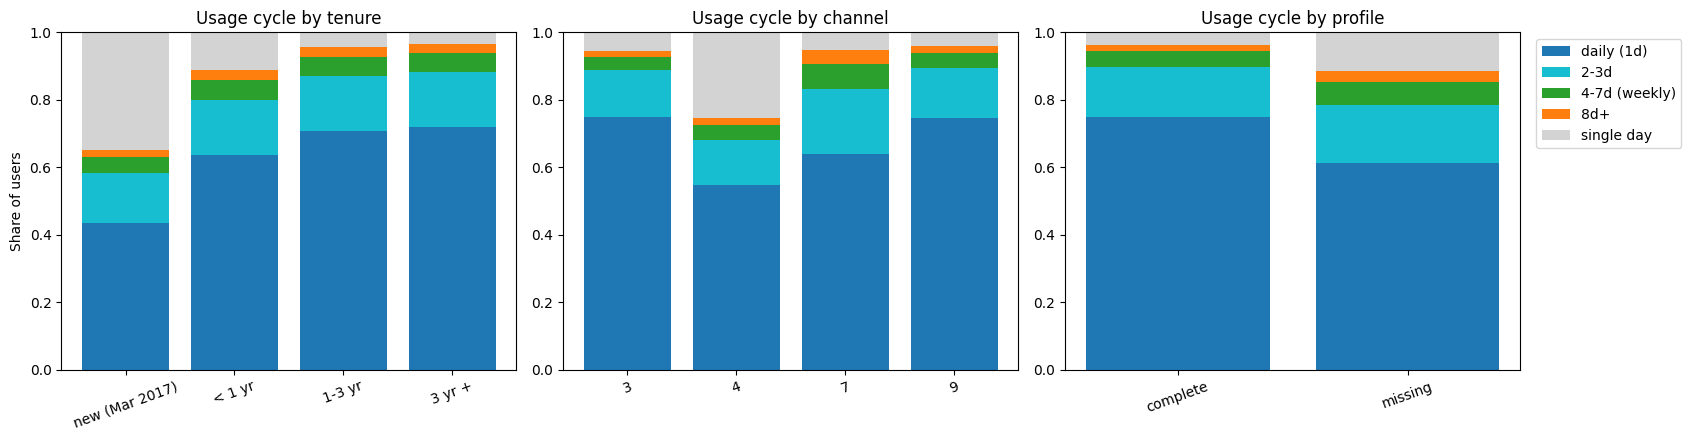

In [20]:
import numpy as np                # 숫자 배열 계산 도구
import matplotlib.pyplot as plt   # 그래프 그리는 도구

# 1) 활동일 표: 하루에 여러 번 들어도 (유저, 날짜) 한 줄 = 활동 1번
# 9절에서 만든 key_all은 (유저 번호 × 64 + 날짜 번호)를 정렬해 둔 것이라, 쪼개기만 하면
# 이미 (유저, 날짜) 순으로 정렬된 표가 됨 → 1,840만 행 문자열 정렬을 통째로 생략함
days = pd.DataFrame({'u': (key_all // 64).astype('int32'),      # 유저 번호
                     'day': (key_all % 64).astype('int16')})    # 3/1을 0일로 둔 날짜 번호
print(f"user_logs 행 수: {len(user_logs):,} → (유저, 날짜) 중복 제거 후: {len(days):,}"
      "  (원래 하루 한 줄이라 중복이 없음)")

# 2) 재방문 간격: 같은 유저의 연속된 두 활동일 사이 일수 (1 = 다음 날 또 들음)
# 이미 (유저, 날짜) 순이므로 바로 앞 행과 비교하면 됨. 유저가 바뀌는 자리는 간격 없음(NaN)
_u, _d = days['u'].to_numpy(), days['day'].to_numpy()
_gap = np.full(len(days), np.nan)
_gap[1:] = np.where(_u[1:] == _u[:-1], _d[1:] - _d[:-1], np.nan)
days['gap'] = _gap

# 3) 유저별 요약: 3월 활동일 수, 첫·마지막 활동일, 간격의 중앙값·평균
users = days.groupby('u').agg(active_days=('day', 'size'),
                              first_day=('day', 'min'),
                              last_day=('day', 'max'),
                              median_gap=('gap', 'median'),
                              mean_gap=('gap', 'mean'))
# 유저 번호를 다시 msno로 바꾸고, 날짜 번호를 날짜로 되돌림
assert (users.index.to_numpy() == np.arange(len(uniq))).all(), '유저 번호와 목록이 어긋남'
users.index = pd.Index(uniq, name='msno')
_base = pd.Timestamp('2017-03-01')
users['first_day'] = _base + pd.to_timedelta(users['first_day'], unit='D')
users['last_day'] = _base + pd.to_timedelta(users['last_day'], unit='D')

# 검증: 표본 5명의 활동일 수가 원본과 맞는지 확인
_s = uniq.sample(5, random_state=2)
_chk = user_logs.loc[user_logs['msno'].isin(_s), ['msno', 'date']].drop_duplicates().groupby('msno').size().sort_index()
assert (_chk.to_numpy() == users.loc[_chk.index, 'active_days'].to_numpy()).all(), '활동일 수가 원본과 다름'
print('검증 통과: 표본 5명의 활동일 수가 원본과 일치')

# 4) 이용 주기 유형: 간격 중앙값으로 나눔 (활동일이 하루뿐이면 간격이 없어서 따로 둠)
CYCLE_ORDER = ['daily (1d)', '2-3d', '4-7d (weekly)', '8d+', 'single day']
users['cycle'] = np.select(
    [users['median_gap'].isna(), users['median_gap'] <= 1, users['median_gap'] <= 3, users['median_gap'] <= 7],
    ['single day', 'daily (1d)', '2-3d', '4-7d (weekly)'], '8d+')

# 5) 코호트 정보 붙이기 (members에 없는 유저는 'unknown')
LAST_DATE = pd.Timestamp('2017-03-31')
# 왼쪽 조인이라 users(3월 활동 유저 110만 명)에 없는 사람은 어차피 버려짐
# → members 677만 명 전체를 붙이지 않고 미리 추려서 조인함 (결과는 동일)
# ⚠️ 3월에 활동했는데 members에 아예 없는 유저가 40명 있음 (1,103,894명 중 교집합 1,103,854명).
#    이들은 특성 컬럼이 모두 NaN이 되어 아래에서 tenure·channel·profile 전부 'unknown'으로 분류됨
info = members[members['msno'].isin(set(uniq))].set_index('msno')[
    ['registered_via', 'registration_init_time', 'gender', 'bd', 'city']]
users = users.join(info, how='left')
reg_date = pd.to_datetime(users['registration_init_time'].astype('Int64').astype(str), format='%Y%m%d', errors='coerce')
tenure_years = (pd.Timestamp('2017-03-01') - reg_date).dt.days / 365
users['tenure'] = np.select(
    [reg_date.isna(), reg_date >= '2017-03-01', tenure_years < 1, tenure_years < 3],
    ['unknown', 'new (Mar 2017)', '< 1 yr', '1-3 yr'], '3 yr +')
users['channel'] = users['registered_via'].map(lambda v: str(int(v)) if v in (3, 4, 7, 9) else ('unknown' if pd.isna(v) else 'other'))
users['profile'] = np.where(users['registered_via'].isna(), 'unknown',
                   np.where(users['gender'].isna() | ~users['bd'].between(10, 80) | (users['city'] == 1), 'missing', 'complete'))

# 3월 신규 가입자는 가입일 이후만 관측되므로 활동일 수가 적게 나옴 → 관측 가능 일수로 나눈 '활동 비율'도 같이 봄
start = reg_date.where(reg_date > pd.Timestamp('2017-03-01'), pd.Timestamp('2017-03-01'))
users['observable_days'] = (LAST_DATE - start).dt.days + 1
users['active_ratio'] = users['active_days'] / users['observable_days']

# ---------------- 전체 ----------------
print(f"\n3월 활동 유저: {len(users):,}명")
print('\n유저별 3월 활동일 수:')
print(users['active_days'].describe(percentiles=[.1, .25, .5, .75, .9]).round(1).to_string())

gap_counts = days['gap'].dropna().astype(int).value_counts().sort_index()
gap_share = gap_counts / gap_counts.sum()
print('\n재방문 간격 분포 (모든 간격 기준, 상위 7일):')
print(gap_share.head(7).round(3).to_string())
print(f"8일 이상: {gap_share[gap_share.index >= 8].sum():.1%}")

cycle_share = users['cycle'].value_counts(normalize=True).reindex(CYCLE_ORDER)
print('\n이용 주기 유형 (유저 기준):')
print(cycle_share.round(3).to_string())

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
ax = axes[0]
ax.hist(users['active_days'], bins=range(1, 33), edgecolor='white')
ax.set_title('Active days per user (March)')
ax.set_xlabel('Active days (out of 31)')
ax.set_ylabel('Users')

ax = axes[1]
shown = gap_share[gap_share.index <= 15]
ax.bar(shown.index.astype(str), shown.values)
ax.set_title('Gap between active days (all gaps, <= 15d)')
ax.set_xlabel('Gap (days)')
ax.set_ylabel('Share of gaps')

ax = axes[2]
ax.bar(cycle_share.index, cycle_share.values, color=['tab:blue', 'tab:cyan', 'tab:green', 'tab:orange', 'lightgray'])
ax.set_title('Usage cycle type (median gap per user)')
ax.set_ylabel('Share of users')
ax.tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

# ---------------- 주요 코호트별 ----------------
COHORTS = {
    'tenure': ['new (Mar 2017)', '< 1 yr', '1-3 yr', '3 yr +'],   # 가입 경과 기간 (3/1 기준)
    'channel': ['3', '4', '7', '9'],                               # 가입 경로 (주요 4개)
    'profile': ['complete', 'missing'],                            # 프로필 입력 여부 (7-3 기준)
}

def cohort_summary(col, order):
    g = users[users[col].isin(order)].groupby(col)
    table = pd.DataFrame({
        'users': g.size(),
        'active_days_median': g['active_days'].median(),
        'active_ratio_mean': g['active_ratio'].mean().round(3),
        'mean_gap': g['mean_gap'].mean().round(2),                 # 유저별 평균 간격의 평균 (중앙값은 대부분 1일이라 차이가 안 보임)
    }).reindex(order)
    cycle = pd.crosstab(users.loc[users[col].isin(order), col], users['cycle'], normalize='index').reindex(index=order, columns=CYCLE_ORDER)
    return table, cycle

fig, axes = plt.subplots(1, len(COHORTS), figsize=(17, 4.5))
for ax, (col, order) in zip(axes, COHORTS.items()):
    table, cycle = cohort_summary(col, order)
    print(f'\n[{col}] 코호트별 요약:')
    print(table.to_string())
    print(f'[{col}] 이용 주기 유형 비율:')
    print(cycle.round(3).to_string())

    # 100% 누적 막대: 코호트마다 이용 주기 유형 구성
    bottom = np.zeros(len(order))
    for c, color in zip(CYCLE_ORDER, ['tab:blue', 'tab:cyan', 'tab:green', 'tab:orange', 'lightgray']):
        ax.bar(order, cycle[c].values, bottom=bottom, color=color, label=c)
        bottom += cycle[c].fillna(0).values
    ax.set_title(f'Usage cycle by {col}')
    ax.set_ylim(0, 1)
    ax.tick_params(axis='x', rotation=20)
axes[0].set_ylabel('Share of users')
axes[-1].legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

**결과 해석**

전체 (3월 활동 유저 약 110만 명)
- **(유저, 날짜) 중복은 없음**: user_logs는 원래 하루 한 줄로 정리돼 있어서, 중복 제거 전후 행 수가 같음.
- **활동일 수는 U자 분포**: 1~2일만 들은 유저와 거의 매일(30~31일) 듣는 유저 양쪽에 몰림. 중앙값 18일.
- **재방문 간격의 80%가 1일**(다음 날 또 들음), 2일 10%, 3일 4% → 대부분 매일 듣는 습관형 서비스임. 단, 자주 듣는 유저일수록 간격 개수가 많아서 이 비율에 더 크게 반영됨.
- **유저 기준 이용 주기**: 매일형 68%, 2~3일 16%, 주간형 6%, 8일 이상 3%, 하루만 활동 8%.

코호트별
| 코호트 | 눈에 띄는 점 |
|---|---|
| 가입 경과 기간 | **3월 신규는 하루만 활동이 35%**, 매일형 43%. 가입이 오래될수록 매일형이 늘어남(1년 미만 64% → 3년 이상 72%). 단, 3월 신규는 관측 기간이 짧아 하루만 활동이 과대평가될 수 있음 (활동 비율 26%). |
| 가입 경로 | **4번 경로는 하루만 활동이 26%**, 활동일 중앙값 5일로 가장 가벼움. 3·9번은 매일형 75%로 가장 충성도가 높음. 7번은 2~3일·주간형 비중이 상대적으로 큼(평균 간격 2.5일). |
| 프로필 입력 여부 | complete는 매일형 75%, 활동일 중앙값 21일. missing은 매일형 61%, 하루만 활동 12%, 활동일 중앙값 14일 → 프로필 미입력 유저가 더 가볍게 이용함. |

**연구에 주는 의미**
- 기준일 방식 D1 재방문율(약 78%)이 높게 나오는 이유가 이 습관형 이용 패턴 때문임 → "평소 습관(D 변수)"이 기대 모델에서 중요한 이유.
- 4번 경로·프로필 미입력·신규 유저는 이용이 가볍고 서로 겹침(7-3절) → 기대 모델에서 이 변수들의 효과가 서로 섞일 수 있음.

### 11-1. 이용 주기 유형 × 청취 행동 상관관계
11절의 이용 주기 유형(간격 중앙값 그룹)과 하루 청취 행동(`num_25` ~ `num_100`, `num_unq`)의 관계를 봄.
- **청취 행동**: 유저별로 **활동한 날 하루 평균** 곡 수를 씀 (활동일 수가 달라도 비교할 수 있게)
- **상관계수**: 각 그룹에 속하는지(1/0)와 하루 평균 곡 수의 **스피어만 상관계수**. 곡 수에 수천 곡짜리 극단값이 있어서 값 대신 순위로 계산함. +면 그 그룹일수록 곡 수가 많고, −면 적음
- **그래프 6개**: 변수 하나당 하나. 그 안에 5개 그룹의 분포를 상자그림으로 그리고, 그룹 이름 아래에 상관계수(r)를 적음

※ 11절 코드 셀(`users`, `CYCLE_ORDER`)을 먼저 실행해야 함.

검증 통과: 표본 5명에서 기존 groupby 방식과 동일
그룹 소속 여부 × 하루 평균 곡 수 스피어만 상관계수 (행 = 그룹, 열 = 변수):
               num_25  num_50  num_75  num_985  num_100  num_unq
daily (1d)      0.245   0.259   0.303    0.325    0.453    0.411
2-3d           -0.098  -0.097  -0.113   -0.117   -0.176   -0.161
4-7d (weekly)  -0.085  -0.084  -0.098   -0.105   -0.147   -0.134
8d+            -0.077  -0.078  -0.089   -0.094   -0.127   -0.117
single day     -0.172  -0.198  -0.235   -0.259   -0.344   -0.309

그룹별 하루 평균 곡 수 (중앙값):
               num_25  num_50  num_75  num_985  num_100  num_unq
cycle                                                           
daily (1d)        4.1     1.0     0.7      0.7     21.0     22.7
2-3d              2.7     0.7     0.4      0.5     11.8     14.3
4-7d (weekly)     2.3     0.6     0.4      0.3      9.3     12.0
8d+               2.0     0.5     0.3      0.3      7.0      9.7
single day        1.0     0.0     0.0      0.0      2.0      4.0


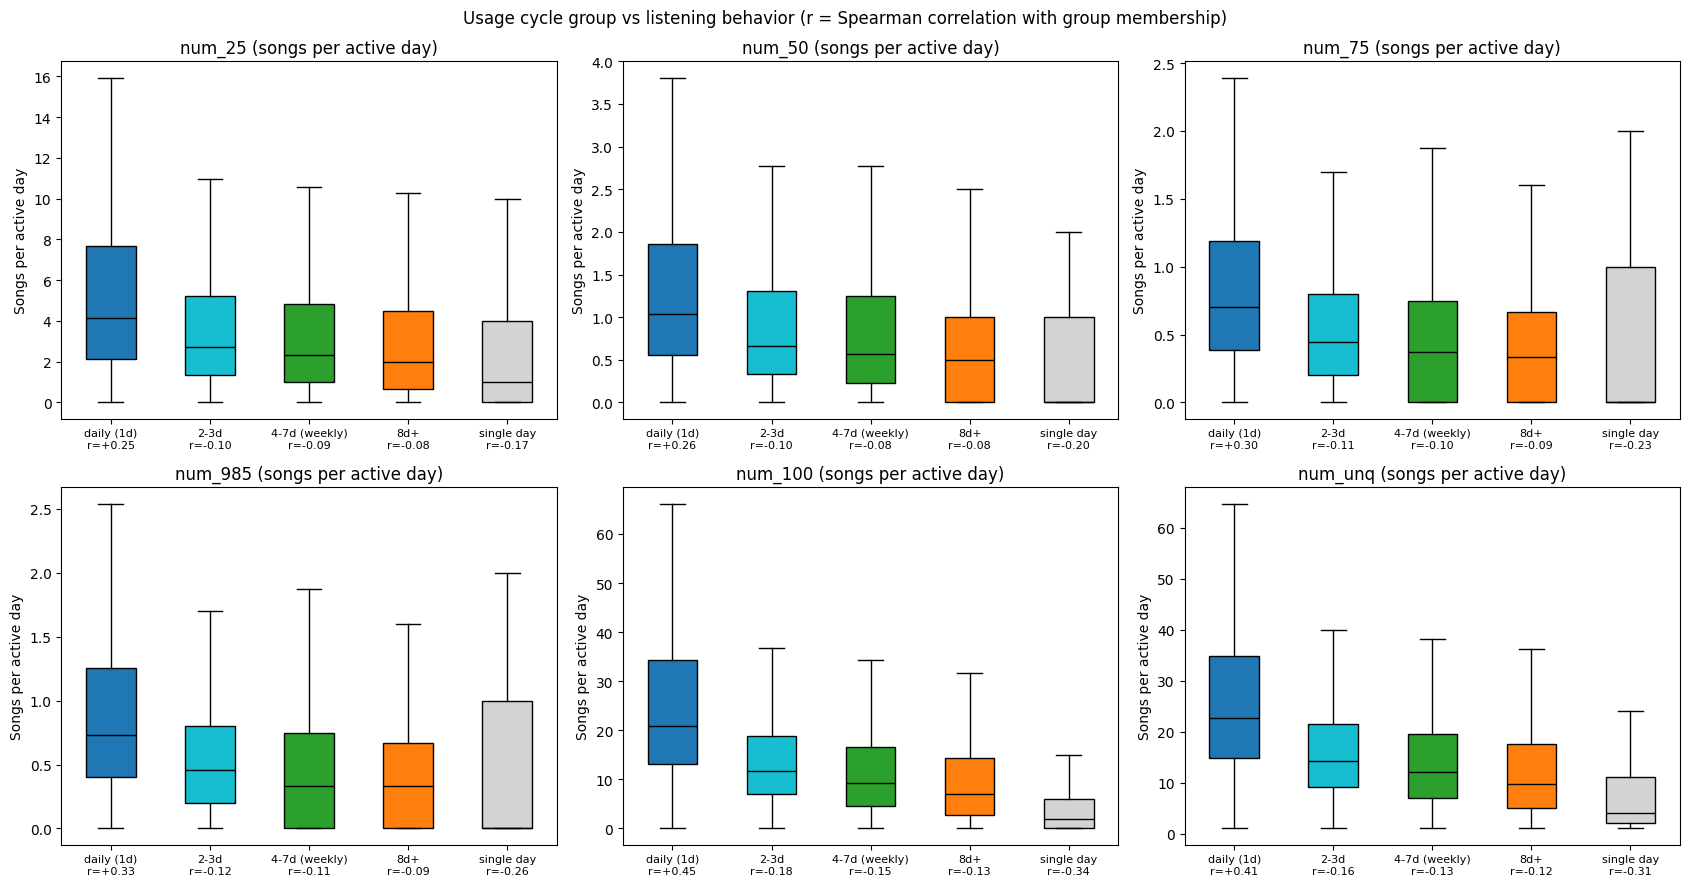

In [21]:
# 이용 주기 유형 × 청취 행동(num_25 ~ num_100, num_unq) 상관관계
# ※ 9절 코드 셀 두 개(code, uniq)와 11절 코드 셀(users, CYCLE_ORDER)을 먼저 실행해야 함
NUM_COLS = ['num_25', 'num_50', 'num_75', 'num_985', 'num_100', 'num_unq']

# 1) 유저별 '활동한 날 하루 평균' 곡 수 — 활동일 수가 달라도 비교할 수 있게 합계가 아니라 평균을 씀
# 문자열 msno로 groupby하면 1,840만 행에서 메모리가 모자라므로,
# 9절에서 만든 유저 번호(code)로 유저별 합계를 세어 평균을 냄 (결과는 같음)
_n_u = len(uniq)
_cnt = np.bincount(code, minlength=_n_u)                      # 유저별 행 수(= 활동일 수)
num_mean = pd.DataFrame(
    {col: np.bincount(code, weights=user_logs[col].to_numpy(), minlength=_n_u) / _cnt
     for col in NUM_COLS},
    index=pd.Index(uniq, name='msno'))

# 검증: 표본 5명에 대해 기존 groupby 방식과 값이 같은지 확인 (표본만 보므로 가벼움)
_s = uniq.sample(5, random_state=0)
_chk = user_logs[user_logs['msno'].isin(_s)].groupby('msno')[NUM_COLS].mean().sort_index()
assert np.allclose(_chk.to_numpy(), num_mean.loc[_chk.index].to_numpy()), '집계 결과가 기존 방식과 다름'
print('검증 통과: 표본 5명에서 기존 groupby 방식과 동일')

cyc = users[['cycle']].join(num_mean)

# 2) 상관계수: 그룹에 속하는지(1/0) × 하루 평균 곡 수
# 곡 수는 수천 곡짜리 극단값이 있어서 값 대신 순위로 계산하는 스피어만 상관계수를 씀 (-1 ~ 1, 0이면 관계 없음)
ranks = cyc[NUM_COLS].rank()
corr = pd.DataFrame({g: ranks.corrwith((cyc['cycle'] == g).astype(float)) for g in CYCLE_ORDER}).T
print('그룹 소속 여부 × 하루 평균 곡 수 스피어만 상관계수 (행 = 그룹, 열 = 변수):')
print(corr.round(3).to_string())

# 그룹별 하루 평균 곡 수의 중앙값 — 상관계수만으로는 크기를 알기 어려워 실제 값도 같이 봄
print('\n그룹별 하루 평균 곡 수 (중앙값):')
print(cyc.groupby('cycle')[NUM_COLS].median().reindex(CYCLE_ORDER).round(1).to_string())

# 3) 그래프 6개: 변수 하나당 그래프 하나, 그 안에 5개 그룹의 분포(상자그림)와 상관계수
COLORS = ['tab:blue', 'tab:cyan', 'tab:green', 'tab:orange', 'lightgray']
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, col in zip(axes.flat, NUM_COLS):
    data = [cyc.loc[cyc['cycle'] == g, col].dropna() for g in CYCLE_ORDER]
    box = ax.boxplot(data, showfliers=False, patch_artist=True,   # 극단값 점은 숨김 (상자 = 25~75%, 가운데 선 = 중앙값)
                     medianprops={'color': 'black'})
    for patch, color in zip(box['boxes'], COLORS):
        patch.set_facecolor(color)
    ax.set_xticks(range(1, len(CYCLE_ORDER) + 1))
    ax.set_xticklabels([f"{g}\nr={corr.loc[g, col]:+.2f}" for g in CYCLE_ORDER], fontsize=8)
    ax.set_title(f'{col} (songs per active day)')
    ax.set_ylabel('Songs per active day')
fig.suptitle('Usage cycle group vs listening behavior (r = Spearman correlation with group membership)')
plt.tight_layout()
plt.show()

**결과 해석**
- **자주 듣는 유저가 하루에도 더 많이 들음**: 매일형만 모든 변수와 양(+)의 상관이고, 나머지 그룹은 모두 음(−). 그룹별 하루 평균 곡 수 중앙값도 매일형 → 2~3일 → 주간형 → 8일 이상 → 하루만 활동 순으로 계속 줄어듦 (예: `num_unq` 22.7 → 14.3 → 12.0 → 9.7 → 4.0곡).
- **끝까지 듣는 곡(`num_100`)과 서로 다른 곡 수(`num_unq`)에서 관계가 가장 강함**: 매일형 r = +0.45, +0.41 / 하루만 활동 r = −0.34, −0.31. 스킵 곡(`num_25`)은 상대적으로 약함(+0.25).
  → 자주 오는 유저는 **곡을 끝까지, 다양하게** 듣고, 하루만 온 유저는 몇 곡 듣다 마는 경향.
- **주의**: 소속 여부(1/0)와의 상관계수는 그룹 크기에 영향을 받음. 매일형(68%)은 크기가 커서 |r|가 크게 나오고, 8일 이상(3%) 같은 작은 그룹은 차이가 있어도 |r|가 작게 나옴 → 그룹 간 크기 차이는 상자그림·중앙값으로 함께 봐야 함.
- **연구에 주는 의미**: 이용 빈도와 하루 청취량이 같이 움직임 → 평소 습관(D 변수)으로 "활동 빈도"와 "하루 청취량"을 둘 다 넣으면 서로 겹치는 정보가 많음. 습관 변수를 고를 때 이 상관을 고려해야 함.

### 11-2. 이용 주기 유형 × 청취 시간
11-1과 같은 방식으로, 그룹 소속 여부(1/0)와 **활동한 날 하루 평균 청취 시간(분)**의 스피어만 상관계수를 봄.
하루(86,400초)를 넘는 이상값(4,200행)은 빼고 평균을 냄.

※ 11절·11-1 코드 셀을 먼저 실행해야 함.

하루 청취 시간 이상값(> 86,400초)으로 뺀 행: 4,200
검증 통과: 표본 5명에서 기존 groupby 방식과 동일

그룹별 하루 평균 청취 시간(분)과 상관계수:
               spearman_r  median_minutes
daily (1d)          0.459            94.1
2-3d               -0.183            54.1
4-7d (weekly)      -0.151            43.5
8d+                -0.129            33.6
single day         -0.340            10.5


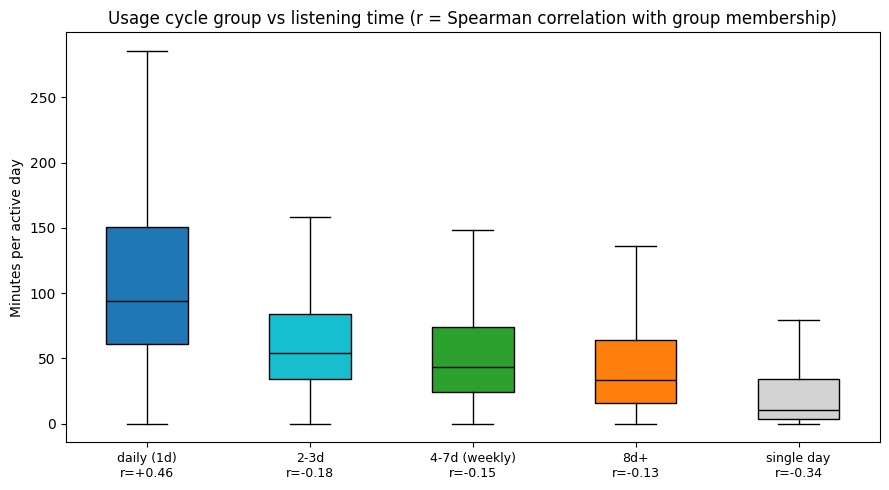

In [22]:
# 이용 주기 유형 × 청취 시간(total_secs) 상관관계
# ※ 9절 코드 셀 두 개(code, uniq)와 11절·11-1 코드 셀(users, CYCLE_ORDER, cyc, COLORS)을 먼저 실행해야 함

# 1) 유저별 '활동한 날 하루 평균' 청취 시간(분)
# 하루(86,400초)를 넘는 값은 말이 안 되는 이상값이라 빼고 평균을 냄 (4절 참고)
# 11-1과 같은 이유로 부분표를 새로 만들지 않고, 유효한 행만 골라 유저 번호로 합계를 냄
_secs = user_logs['total_secs'].to_numpy()
_ok = _secs <= 86400
_cnt_ok = np.bincount(code[_ok], minlength=len(uniq))
_sum_ok = np.bincount(code[_ok], weights=_secs[_ok], minlength=len(uniq))
_minutes = pd.Series(np.where(_cnt_ok > 0, _sum_ok / np.maximum(_cnt_ok, 1) / 60, np.nan),
                     index=pd.Index(uniq, name='msno'))
cyc['minutes'] = _minutes.reindex(cyc.index)
print(f"하루 청취 시간 이상값(> 86,400초)으로 뺀 행: {(~_ok).sum():,}")

# 검증: 표본 5명에 대해 기존 방식과 같은지 확인
_s2 = uniq.sample(5, random_state=1)
_sub = user_logs[user_logs['msno'].isin(_s2)]
_chk2 = (_sub.loc[_sub['total_secs'] <= 86400].groupby('msno')['total_secs'].mean() / 60).sort_index()
assert np.allclose(_chk2.to_numpy(), _minutes.loc[_chk2.index].to_numpy()), '집계 결과가 기존 방식과 다름'
print('검증 통과: 표본 5명에서 기존 groupby 방식과 동일')

# 2) 그룹 소속 여부(1/0) × 하루 평균 청취 시간 — 11-1과 같은 스피어만 상관계수
minutes_rank = cyc['minutes'].rank()
secs_corr = pd.Series({g: minutes_rank.corr((cyc['cycle'] == g).astype(float)) for g in CYCLE_ORDER})
secs_table = pd.DataFrame({'spearman_r': secs_corr.round(3),
                           'median_minutes': cyc.groupby('cycle')['minutes'].median().reindex(CYCLE_ORDER).round(1)})
print('\n그룹별 하루 평균 청취 시간(분)과 상관계수:')
print(secs_table.to_string())

# 3) 그래프: 그룹별 하루 평균 청취 시간 분포 (상자그림, 그룹 이름 아래에 r)
fig, ax = plt.subplots(figsize=(9, 5))
data = [cyc.loc[cyc['cycle'] == g, 'minutes'].dropna() for g in CYCLE_ORDER]
box = ax.boxplot(data, showfliers=False, patch_artist=True, medianprops={'color': 'black'})
for patch, color in zip(box['boxes'], COLORS):
    patch.set_facecolor(color)
ax.set_xticks(range(1, len(CYCLE_ORDER) + 1))
ax.set_xticklabels([f"{g}\nr={secs_corr[g]:+.2f}" for g in CYCLE_ORDER], fontsize=9)
ax.set_ylabel('Minutes per active day')
ax.set_title('Usage cycle group vs listening time (r = Spearman correlation with group membership)')
plt.tight_layout()
plt.show()

**결과 해석**

| 그룹 | 상관계수 r | 하루 평균 청취 시간 (중앙값) |
|---|---|---|
| 매일형 | **+0.46** | **94분** |
| 2~3일 | −0.18 | 54분 |
| 주간형 | −0.15 | 44분 |
| 8일 이상 | −0.13 | 34분 |
| 하루만 활동 | **−0.34** | **11분** |

- 곡 수(11-1)와 같은 모양: 자주 오는 유저일수록 **하루에도 오래 들음**. 매일형은 하루 약 1시간 30분, 하루만 온 유저는 약 10분.
- 상관 크기(+0.46)는 `num_100`(+0.45)과 거의 같음 → 청취 시간은 대부분 끝까지 들은 곡 수로 결정됨.
- 11-1과 마찬가지로 상관계수는 그룹 크기의 영향을 받으므로, 중앙값·상자그림과 함께 해석해야 함.

## 12. 기준일별 D1 리텐션 — 종속변수 수준 점검

기대 모델의 **종속변수 그 자체**(기준일 t에 음악을 들은 유저가 t+1일에도 들었나)를 3월 전체에 대해 봄. 8절의 N-Day 리텐션은 가입일을 Day 0으로 둔 **신규 코호트** 분석이고, 이 절은 **모든 활동 유저 × 모든 활동일**을 기준일로 삼음 (계획서 7.1의 주 분석 단위와 같음).

| 항목 | 정의 |
|---|---|
| 분석 단위 | (유저, 기준일 t) — t일에 음악을 재생한 모든 유저 |
| 결과 변수 | **D1** = t+1일에 재생했나 (0/1) |
| 기준일 범위 | **2017-03-01 ~ 03-30** (3/31은 결과일이 4/1이라 D1을 만들 수 없음) |
| 분모 / 분자 | 그날 음악을 들은 유저 수 / 그중 다음 날에도 들은 유저 수 |

**기간 구분 (계획서 7.1)** — 습관 측정 창을 2월 한 달로 옮기면서 3월은 두 구간으로만 나뉨

| 구간 | 기간 | 역할 |
|---|---|---|
| 습관 측정 | **2017-02-01 ~ 02-28** | 평소 습관(D)을 한 번 재서 고정. 기준일로 쓰지 않음 (13절) |
| **① 학습·정상** | 기준일 **3/1 ~ 3/15** (결과일 3/2~3/16) | 기대 모델을 학습. "하락 이전"으로 간주하는 구간 |
| **② 평가** | 기준일 **3/16 ~ 3/30** (결과일 3/17~3/31) | 편차를 재고 집단을 탐색하는 구간 |

경계는 기준일이 아니라 **결과일**로 정함 — 결과 변수가 t+1이라 마지막 학습 기준일(3/15)의 결과일(3/16)까지가 하락 이전이어야 함. 처음에는 3/1~3/7을 습관 측정에 쓰고 3월을 세 구간으로 나눴으나, 7일 창의 한계가 커서 바꿨음 (근거는 **13-1절**).

보는 것 네 가지
1. **기준일별 D1 추이 + 7일 이동평균** — 요일 효과를 지운 추세가 평평한가
2. **기간별 평균** — 실제 데이터에 하락이 있는가. 행 가중 평균과 날짜 단순평균을 같이 봐서 구성 효과를 분리함
3. **요일 보정 편차** — 학습 기간의 같은 요일을 기대값으로 본 평가 기간 편차 (기대 모델을 쓰지 않는 가장 단순한 전후 비교)
4. **집단별 D1 시계열** — 가입 경과 기간(tenure), 기준일까지의 결제 기록, 프로필 입력 여부

누수 방지: 집단을 나누는 기준도 **기준일 t까지 관측 가능한 정보만** 씀. 결제 여부는 유저별 첫 결제일을 구해 `첫 결제일 ≤ t`로 판정하므로, 날짜가 지날수록 결제자가 늘어나는 구조임 (8-1절 참고).

※ 9절 코드 셀 두 개(`active`, `code`, `day`, `key_all`, `uniq`)와 11절 코드 셀(`users`)을 먼저 실행해야 함.

기준일 행(유저 × 기준일): 17,818,632   기준일 범위: 3/1~3/30   유저: 1,099,987명

기준일별 D1 (분모 = 그날 음악을 들은 유저, 분자 = 다음 날에도 들은 유저):
            base_users  returned     D1 weekday  D1_ma7
day                                                    
2017-03-01      575889    457417  79.43     Wed     NaN
2017-03-02      580623    460190  79.26     Thu     NaN
2017-03-03      590594    443916  75.16     Fri     NaN
2017-03-04      584124    447937  76.69     Sat   77.63
2017-03-05      589177    438929  74.50     Sun   77.66
2017-03-06      577955    456946  79.06     Mon   77.68
2017-03-07      579079    459379  79.33     Tue   77.75
2017-03-08      581288    462812  79.62     Wed   77.83
2017-03-09      584919    464505  79.41     Thu   77.91
2017-03-10      597915    452101  75.61     Fri   77.96
2017-03-11      592497    457879  77.28     Sat   78.04
2017-03-12      598768    449261  75.03     Sun   78.08
2017-03-13      587823    466934  79.43     Mon   78.16
2017-03-14      589627    471206  79.92     Tue

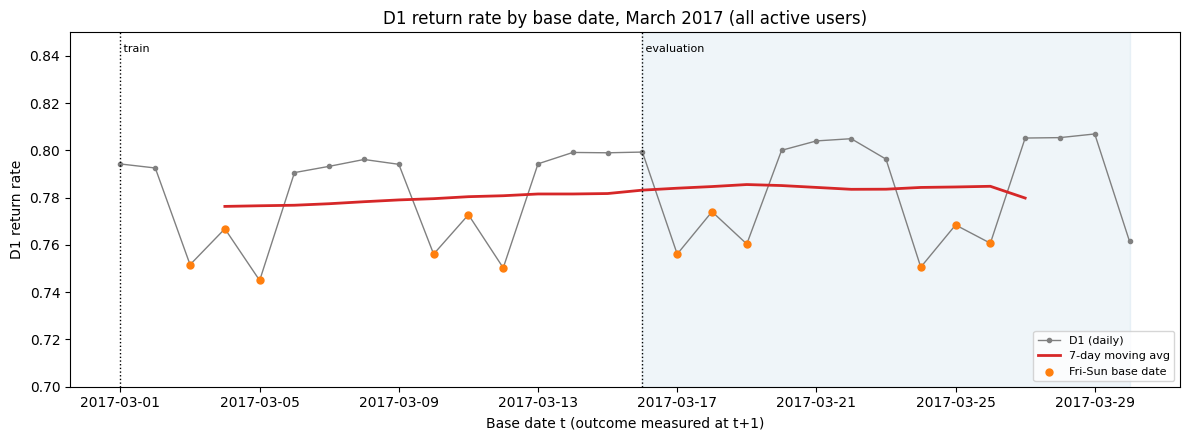

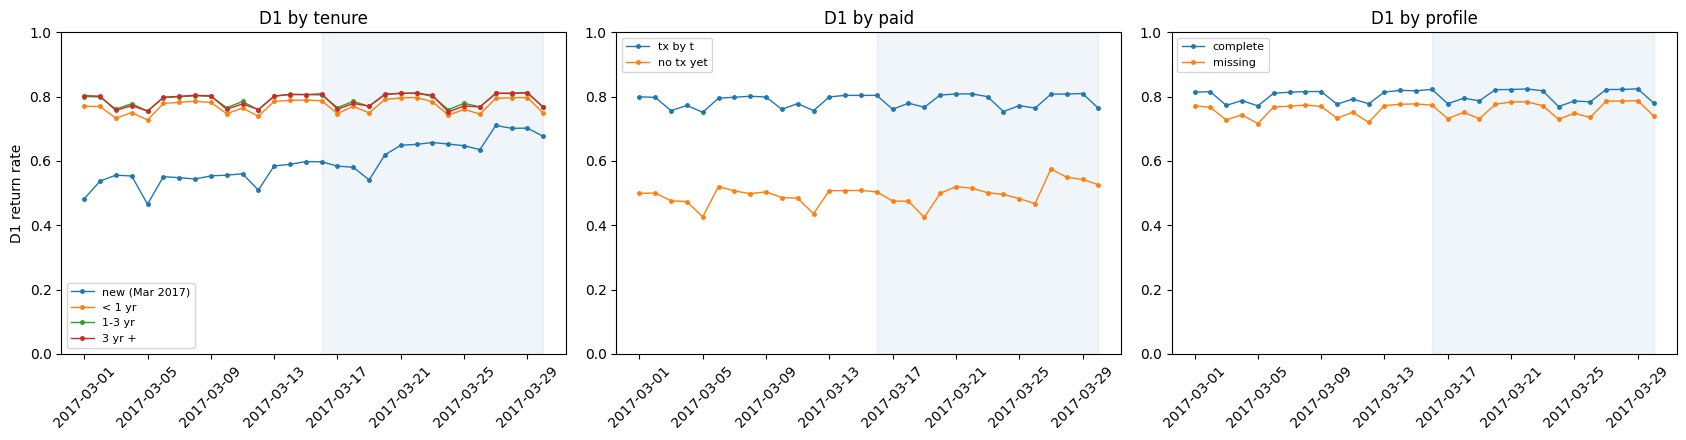

In [29]:
import numpy as np                # 숫자 배열 계산 도구
import matplotlib.pyplot as plt   # 그래프 그리는 도구

# ── 1) 기준일별 D1 ─────────────────────────────────────────────────────
# 9절에서 만든 정수 키로 '다음 날에도 활동했나'를 구함 (10절 첫 셀과 같은 계산)
k_next = code.astype('int64') * 64 + (day + 1)
_i = np.searchsorted(key_all, k_next)
_i[_i >= len(key_all)] = len(key_all) - 1
hit_next = key_all[_i] == k_next

# 기준일은 3/1~3/30 (날짜 번호 0~29)만 씀. 3/31은 결과일이 4/1이라 D1을 만들 수 없음
BASE_LAST = 29
rows_ok = day <= BASE_LAST
base = pd.DataFrame({'u': code[rows_ok], 'day': day[rows_ok].astype('int16'), 'd1': hit_next[rows_ok]})
print('기준일 행(유저 × 기준일): {:,}   기준일 범위: 3/1~3/30   유저: {:,}명'.format(
    len(base), base['u'].nunique()))

# ── 2) 날짜별 분모·분자·D1 ─────────────────────────────────────────────
_g = base.groupby('day')['d1']
daily = pd.DataFrame({'base_users': _g.size(), 'returned': _g.sum().astype('int64'), 'D1': _g.mean()})
daily.index = pd.Timestamp('2017-03-01') + pd.to_timedelta(daily.index, unit='D')
daily['weekday'] = daily.index.day_name().str[:3]
daily['D1_ma7'] = daily['D1'].rolling(7, center=True).mean()   # 요일 효과를 지운 추세 (앞뒤 3일은 빔)
print()
print('기준일별 D1 (분모 = 그날 음악을 들은 유저, 분자 = 다음 날에도 들은 유저):')
print(daily.assign(D1=lambda d: (d['D1'] * 100).round(2),
                   D1_ma7=lambda d: (d['D1_ma7'] * 100).round(2)).to_string())

# ── 3) 기간 구분 비교 (계획서 7.1) — 실제 데이터에 하락이 있나 ───────────
# 습관 측정 창은 2월이라 3월 밖에 있음 → 3월은 학습·평가 두 구간으로만 나뉨 (계획서 7.1)
PERIODS = {'(1) 학습·정상 3/1~3/15': (0, 14), '(2) 평가 3/16~3/30': (15, 29)}
TRAIN_LAST = 14          # 학습 기간 마지막 기준일 3/15 (날짜 번호 14)
_rows = []
for _name, (_a, _b) in PERIODS.items():
    _m = base['day'].between(_a, _b)
    _sub = daily.iloc[_a:_b + 1]
    _rows.append({'구간': _name, '일수': _b - _a + 1, '기준일 행': int(_m.sum()),
                  '유저수(중복제거)': base.loc[_m, 'u'].nunique(),
                  'D1(행 가중)': base.loc[_m, 'd1'].mean(),      # 기대 모델의 종속변수와 같은 단위
                  'D1(날짜 단순평균)': _sub['D1'].mean(),          # 날짜마다 같은 무게 → 구성 효과를 뺀 값
                  '금토일 비중': _sub['weekday'].isin(['Fri', 'Sat', 'Sun']).mean()})
period = pd.DataFrame(_rows)
print()
print('기간 구분 비교 (습관 측정 창은 2월이라 3월 밖에 있음):')
print(period.to_string(index=False, formatters={'D1(행 가중)': '{:.4f}'.format,
                                                'D1(날짜 단순평균)': '{:.4f}'.format,
                                                '금토일 비중': '{:.2f}'.format}))

# ── 4) 요일 보정: 정상 기간의 요일별 D1을 기대값으로 본 평가 기간 편차 ──
# 기대 모델을 쓰지 않는 가장 단순한 전후 비교 (계획서 7.3 비교 방법 중 하나)에 해당함
# 학습 기간은 15일이라 요일마다 2~3일씩 있음 → 요일별 평균을 기대값으로 씀
wd_base = daily.iloc[:TRAIN_LAST + 1].groupby('weekday')['D1'].mean()
ev = daily.iloc[TRAIN_LAST + 1:30].copy()
ev['expected'] = ev['weekday'].map(wd_base)
ev['dev'] = ev['D1'] - ev['expected']
print()
print('평가 기간 요일 보정 편차 (실제 − 정상 기간 같은 요일):')
print(ev[['weekday', 'D1', 'expected', 'dev']].assign(
    D1=lambda d: (d['D1'] * 100).round(2), expected=lambda d: (d['expected'] * 100).round(2),
    dev=lambda d: (d['dev'] * 100).round(2)).to_string())
print('편차 평균: {:+.2f}%p   음수인 날: {}/{}일'.format(
    ev['dev'].mean() * 100, int((ev['dev'] < 0).sum()), len(ev)))

# ── 5) 집단 라벨 붙이기 ────────────────────────────────────────────────
# users(11절)는 유저 번호(uniq) 순서라 code로 바로 색인할 수 있음 — 11절에서 assert로 확인함
base['tenure'] = users['tenure'].to_numpy()[base['u'].to_numpy()]
base['profile'] = users['profile'].to_numpy()[base['u'].to_numpy()]

# 결제 여부는 '기준일까지의 결제 기록'으로 판정함 — 기준일 이후 결제를 쓰면 미래 정보가 섞임 (8-1절 참고)
_txu = pd.read_parquet('data/transactions_all.parquet', columns=['msno', 'transaction_date'])
_c = pd.Categorical(_txu['msno'], categories=uniq).codes                  # 3월 활동 유저가 아니면 -1
_tday = ((pd.to_datetime(_txu['transaction_date'].astype(str), format='%Y%m%d')
          - pd.Timestamp('2017-03-01')).dt.days).to_numpy()
del _txu
_m = _c >= 0
_first = pd.Series(_tday[_m]).groupby(_c[_m]).min()                       # 유저별 첫 결제일 (3/1 = 0, 그 전은 음수)
first_tx_day = np.full(len(uniq), 32767, dtype='int32')                   # 기록이 없으면 아주 큰 값
first_tx_day[_first.index.to_numpy()] = _first.to_numpy()
base['paid'] = np.where(first_tx_day[base['u'].to_numpy()] <= base['day'].to_numpy(), 'tx by t', 'no tx yet')
print()
print('기준일까지 결제 기록이 있는 행 비중: {:.3f}'.format((base['paid'] == 'tx by t').mean()))

# ── 6) 검증 ───────────────────────────────────────────────────────────
assert daily['base_users'].sum() == int(rows_ok.sum()), '분모 합이 활동 행 수와 다름'
_chk = base.loc[base['day'] <= 13, 'd1'].mean()
print('검증 1: 기준일 3/1~3/14 D1 = {:.4f} (9절 exact_return(1) = 0.778과 같아야 함)'.format(_chk))
_uniq_idx = pd.Index(uniq)
for _msno in pd.Series(uniq).sample(5, random_state=7):
    _un = int(_uniq_idx.get_loc(_msno))
    _mine = base.loc[base['u'] == _un, 'tenure'].unique()
    assert len(_mine) == 0 or _mine[0] == users.loc[_msno, 'tenure'], 'tenure 라벨이 11절 표와 다름'
print('검증 2: 표본 5명의 tenure 라벨이 11절 users 표와 일치')

# ── 7) 집단별 D1 시계열 ───────────────────────────────────────────────
COHORTS = {'tenure': ['new (Mar 2017)', '< 1 yr', '1-3 yr', '3 yr +'],   # 가입 경과 기간 (3/1 기준)
           'paid': ['tx by t', 'no tx yet'],                            # 기준일까지의 결제 기록
           'profile': ['complete', 'missing']}                          # 프로필 입력 여부 (7-3절 기준)
series = {}
for _col, _order in COHORTS.items():
    _sub = base[base[_col].isin(_order)]
    _piv = _sub.groupby(['day', _col])['d1'].mean().unstack().reindex(columns=_order)
    _piv.index = pd.Timestamp('2017-03-01') + pd.to_timedelta(_piv.index, unit='D')
    series[_col] = _piv
    _cnt = _sub.groupby(_col)['d1'].agg(rows='size', D1='mean').reindex(_order)
    _cnt['구간별 D1'] = [tuple(round(_sub.loc[(_sub[_col] == g) & _sub['day'].between(a, b), 'd1'].mean(), 3)
                             for a, b in PERIODS.values()) for g in _order]
    print()
    print('[{}] 집단별 D1 — 전체, 그리고 (학습, 평가) 구간별:'.format(_col))
    print(_cnt.to_string(formatters={'D1': '{:.4f}'.format}))

# ── 8) 그래프 ─────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(daily.index, daily['D1'], marker='o', markersize=3, color='gray', linewidth=1, label='D1 (daily)')
ax.plot(daily.index, daily['D1_ma7'], color='tab:red', linewidth=2, label='7-day moving avg')
_we = daily['weekday'].isin(['Fri', 'Sat', 'Sun'])
ax.scatter(daily.index[_we], daily['D1'][_we], color='tab:orange', zorder=3, s=25, label='Fri-Sun base date')
for _d, _lab in [('2017-03-01', 'train'), ('2017-03-16', 'evaluation')]:
    ax.axvline(pd.Timestamp(_d), color='black', linestyle=':', linewidth=1)
    ax.text(pd.Timestamp(_d), 0.845, ' ' + _lab, fontsize=8, va='top')
ax.axvspan(pd.Timestamp('2017-03-16'), pd.Timestamp('2017-03-30'), color='tab:blue', alpha=0.07)
ax.set_ylim(0.70, 0.85)
ax.set_ylabel('D1 return rate')
ax.set_xlabel('Base date t (outcome measured at t+1)')
ax.set_title('D1 return rate by base date, March 2017 (all active users)')
ax.legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for _ax, (_col, _order) in zip(axes, COHORTS.items()):
    for g in _order:
        _ax.plot(series[_col].index, series[_col][g], marker='o', markersize=2.5, linewidth=1, label=g)
    _ax.axvspan(pd.Timestamp('2017-03-16'), pd.Timestamp('2017-03-30'), color='tab:blue', alpha=0.07)
    _ax.set_ylim(0, 1)
    _ax.set_title('D1 by ' + _col)
    _ax.tick_params(axis='x', rotation=45)
    _ax.legend(fontsize=8)
axes[0].set_ylabel('D1 return rate')
plt.tight_layout()
plt.show()

**결과 해석**

**(1) 전체 수준과 추세** — 기준일별 D1은 **74.5~80.7%** 사이에서 요일에 따라 오르내림(최저 3/5 일요일, 최고 3/29 수요일). 요일 효과를 지운 7일 이동평균은 **77.6~78.6%**로 거의 평평하고 월중에 아주 조금 오름. 분모(그날 음악을 들은 유저)는 **57.6만~60.9만 명**으로 안정적임.

**(2) 기간별 비교 — 실제 데이터에는 하락이 없음**

| 구간 | 일수 | 기준일 행 | 유저 수 | D1 (행 가중) | D1 (날짜 단순평균) | 금·토·일 비중 |
|---|---|---|---|---|---|---|
| ① 학습·정상 3/1~3/15 | 15 | 880만 2,984 | 100만 6,863 | 0.7796 | 0.7798 | **0.40** |
| ② 평가 3/16~3/30 | 15 | 901만 5,648 | 99만 9,247 | **0.7836** | 0.7836 | **0.40** |

- 평가 기간이 학습 기간보다 **0.40%p 높음** → 주입 실험의 출발점에 실제 하락이 섞여 있지 않음. 다만 **무주입 조건이 완전히 평평하지는 않아서** 거짓 경보율은 이 약한 상승을 기준선으로 두고 읽어야 함
- **금·토·일 비중이 두 구간 모두 0.40으로 같음** — 3/1이 수요일이라 15일씩 자르면 요일 구성이 거의 대칭이 됨(학습은 수요일 3번, 평가는 목요일 3번, 나머지 요일은 2번씩). 이전 설계(학습 0.43 / 평가 0.38)에서 생기던 요일 불균형이 사라짐
- 행 가중 평균과 날짜 단순평균이 거의 같음 → **날짜별 모집단 크기 변화의 영향은 무시할 수준.** 다만 이 비교는 날짜별 크기만 잡아내고 **같은 날 안에서의 구성 변화는 잡지 못함** (13절 참고)

**(3) 요일 보정 편차** — 학습 기간의 같은 요일 평균을 기대값으로 보면 편차 평균 **+0.41%p**, 15일 중 음수인 날은 3일(3/24 −0.33, 3/25 −0.13, 3/30 −3.19).

- **3/30만 −3.19%p로 혼자 크게 튐** (다른 목요일은 +0.60, +0.30). 월말 효과인지 데이터가 3/31에서 잘려서인지는 3월만으로 구분할 수 없음 (10절과 같은 한계). 평가 기간의 **마지막 기준일**이라 집단별 편차를 해석할 때 주의가 필요함
- 일요일(3/19 +1.28, 3/26 +1.31)이 일관되게 높은 것도 눈에 띔 → 요일 변수만으로 다 흡수되지 않는 월중 변화가 남아 있음

**(4) 집단별 D1 — 집단 간 차이가 매우 큼**

| 집단 | 행 | D1 (전체) | 학습 → 평가 |
|---|---|---|---|
| 3월 신규 | 32만 7,048 | **0.6035** | 0.551 → 0.639 |
| 1년 미만 | 340만 1,370 | 0.7698 | 0.766 → 0.774 |
| 1~3년 | 531만 8,439 | 0.7892 | 0.788 → 0.791 |
| 3년 이상 | 877만 1,374 | 0.7883 | 0.787 → 0.790 |
| 결제 기록 있음 (t까지) | 1,754만 8,307 | 0.7861 | 0.785 → 0.787 |
| **결제 기록 없음** | 27만 325 | **0.4917** | 0.487 → 0.497 |
| 프로필 입력 | 943만 5,759 | 0.8024 | 0.801 → 0.804 |
| 프로필 미입력 | 838만 2,472 | 0.7583 | 0.756 → 0.761 |

- 집단 간 격차가 매우 큼 — 결제 기록 없음 0.492 vs 있음 0.786(**29%p**), 프로필 입력 여부 4.4%p. 기대 모델이 이 차이를 흡수하지 못하면 **원래 리텐션이 낮은 집단이 그대로 상위 가설로 올라옴** (계획서 RQ2 구성 변화 실험이 노리는 지점)
- ⚠️ **3월 신규의 0.551 → 0.639 상승은 개선이 아니라 생존 효과임** — 기준일이 늦을수록 가입 후 경과일이 쌓이고, 초반에 떠난 유저는 기준일 행에 들어오지 않음. 따라서 **가입 후 경과일을 기대 모델 변수(A)에 반드시 넣어야 함.** 넣지 않으면 "신규 유저"가 기간 비교에서 가짜 가설로 올라오거나, 반대로 진짜 하락을 상승으로 가려버림

## 13. 평소 습관 변수(D) 점검 — 측정과 기간 간 안정성

기대 모델의 설명 변수 묶음 **D(평소 습관)** 를 실제로 만들어 보는 절임. 11절에서 "자주 오는 유저가 하루에도 많이·끝까지·다양하게 듣는다"를 확인했고, 그 차이를 모델에 넣을 변수를 여기서 계산함.

| 항목 | 정의 |
|---|---|
| 측정 창 | **2017-02-01 ~ 02-28 (28일 = 정확히 4주)** — 유저당 한 번만 재서 **고정값**으로 씀 |
| 적용 대상 | 기준일 **3/1 ~ 3/30** 의 (유저, 기준일) 행 — 12절 `base` 전체 |
| 결과 변수 | **D1** = t+1일에 재생했나 (12절과 같음) |
| 자료 | **1절에서 올린 `user_logs_feb`** (= `data/user_logs_feb2017.parquet`, v1 원본 3.92억 행에서 2월만 추출, 1,608만 행) |

### 변수 7개

| # | 변수 | 축 | 계산 (측정 창 전체에 대해 한 번) |
|---|---|---|---|
| ① | 활동일 수 | **빈도** | 음악을 재생한 날 수 (0~28) |
| ② | 하루 평균 청취 시간 | **양** | `total_secs` 합 ÷ 활동일 수 (분) |
| ③ | 완청 비율 | **질** | `num_100` 합 ÷ 전체 재생 곡 수 합 |
| ④ | 서로 다른 곡 비율 | **다양성** | `num_unq` 합 ÷ 전체 재생 곡 수 합 |
| ⑤ | 마지막 활동 이후 일수 | **최근성** | 2/28 − 측정 창 마지막 활동일 (0~27) |
| ⑥ | **활동 추세** | **추세** | 2/15~2/28 활동일 수 − 2/1~2/14 활동일 수 (−14~+14) |
| ⑦ | **주말 활동 비중** | **시간 패턴** | 토·일 활동일 ÷ 전체 활동일. 2월은 4주라 주말이 정확히 8일(28.6%)임 |
| + | `no_habit` 플래그 | — | 측정 창에 활동이 없어 **잴 수 없는 유저** (①=0, ②~⑦=결측) |

**왜 고정값인가** — 기준일마다 직전 N일을 다시 계산하면, 이벤트로 생긴 행동 감소까지 "이 유저의 평소 모습"으로 보게 되어 **찾아야 할 이상을 기대 모델이 흡수**해 버림 (계획서 표 6). 측정 창이 2월이라 3월과 **완전히 분리**되어 있어 이 문제가 생길 여지가 없음.

**왜 `no_habit`을 따로 두나** — 결측만으로는 집단 탐색의 **조건을 만들 수 없음**. 플래그가 없으면 빔 서치가 이 집단을 가설 후보로 집지 못함.

**왜 창이 2월 한 달인가** — 처음에는 3/1~3/7 7일로 재려 했으나 천장 효과가 심해 바꿨음. 근거는 **13-1절**에서 수치로 확인함.

보는 것 네 가지
1. **측정 범위와 이상값** — 몇 명에게서 재지나, `total_secs` 이상값은 얼마나 되나
2. **분포와 D1의 관계** — 7개가 각각 집단을 가르나([A]~[C]), 활동일 수를 통제해도 남나([D]), 서로 중복되지 않나([E])
3. **측정 불가 집단** — 크기와 구성([A][G])
4. **기간 간 안정성** — 습관을 과거에 고정 측정하므로 기준일이 멀어질수록 값이 낡지 않나([F])

누수 방지: 습관은 기준일 **이전**(2월)에서만 계산하므로 결과일(t+1) 정보가 섞이지 않음. 구간을 나누는 분위수 경계도 **학습 기간(3/1~3/15)** 분포에서만 정함 — 평가 기간까지 포함해 정하면 평가 기간 정보가 설계에 새어 들어감.

※ **1절(`user_logs_feb`)**, 9절(`code`, `day`, `key_all`, `uniq`), 11절(`users`), **12절(`base`)** 을 먼저 실행해야 함.

2월 로그 16,079,619행 중 3월 활동 유저의 행 15,579,565개 (96.9%)를 씀
total_secs  음수 0행(0.0000%)  /  86,400초 초과 3,820행(0.0238%)  → 초과 행만 ②에서 제외

측정 창(2월)에 활동한 유저 954,116명 / 3월 활동 유저 1,103,894명 (86.4%)
  ③④ 계산 불가(곡 수 합 0) 0명   ② 계산 불가(이상값 제외 후 0일) 26명

습관 7개 분포 (측정 창 활동 유저 기준, 유저당 1행):
         act_days  mins_per_day    pct_full  pct_unique  days_since_last       trend  weekend_ratio
count 954,116.000   954,090.000 954,116.000 954,116.000      954,116.000 954,116.000    954,116.000
mean       16.329       112.268       0.701       0.771            1.816       0.410          0.289
std         8.444       106.951       0.204       0.177            3.976       3.034          0.150
min         1.000         0.000       0.000       0.002            0.000     -14.000          0.000
5%          2.000        20.125       0.305       0.406            0.000      -4.000          0.000
25%         9.000        50.968       0.588       0.689            0.000      -1.000          0.235
50%        17.000        82.7

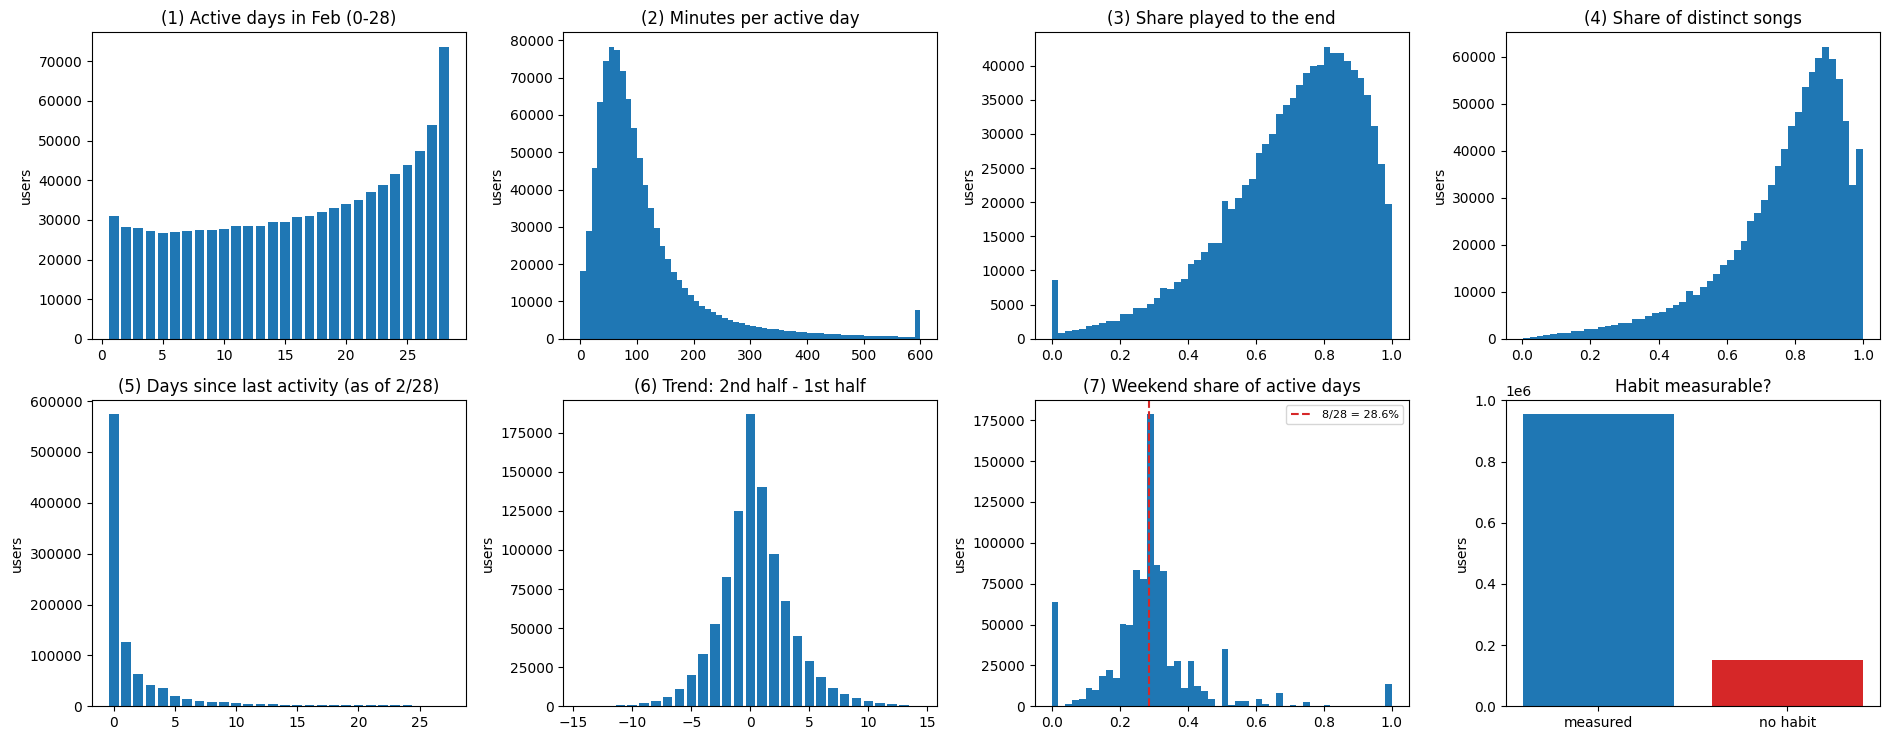

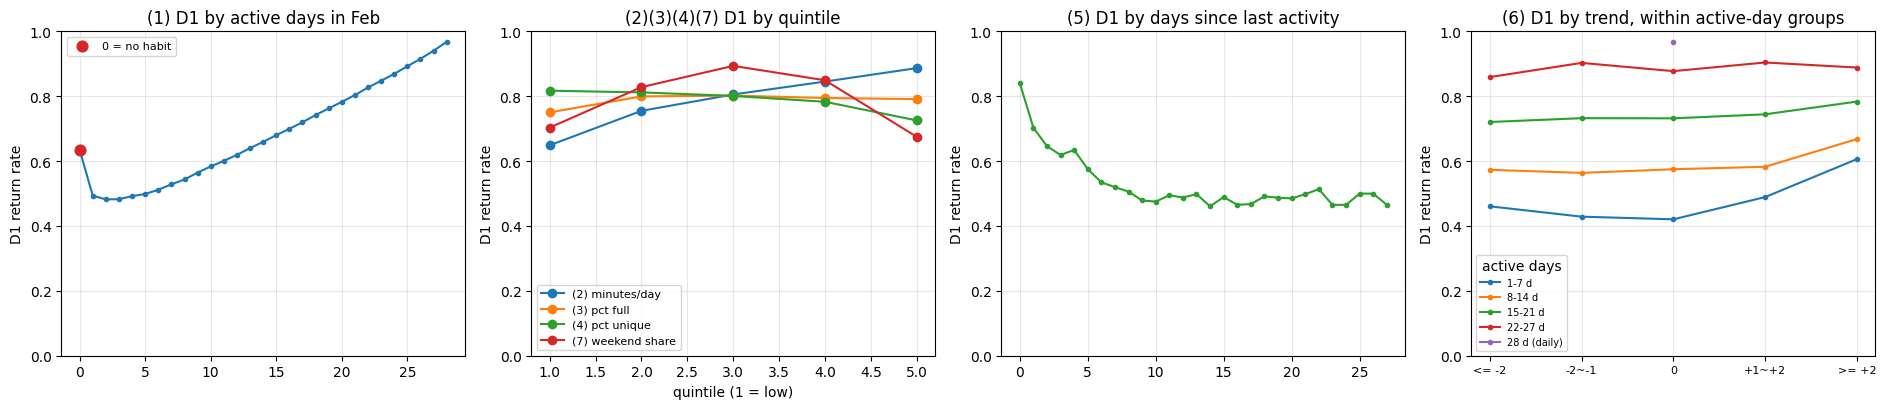

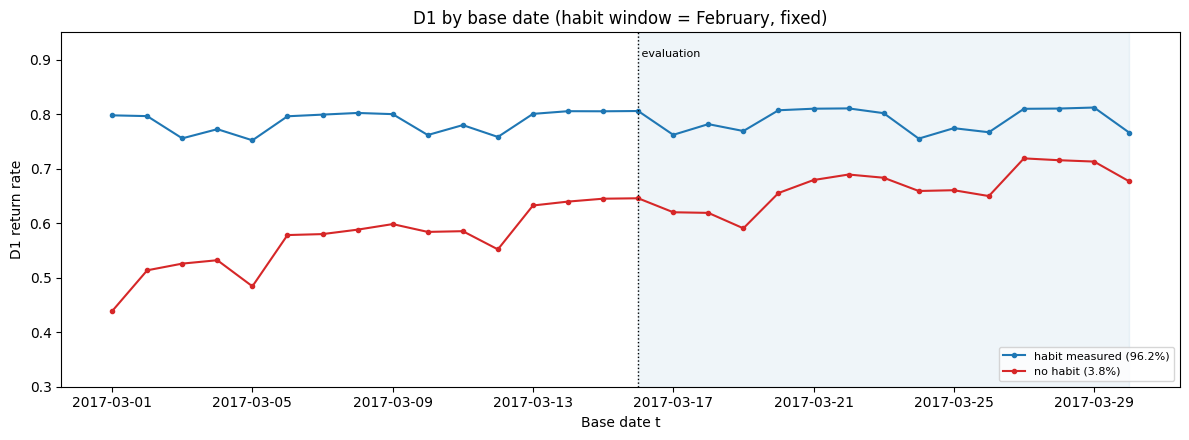

In [25]:
import numpy as np                # 숫자 배열 계산 도구
import matplotlib.pyplot as plt   # 그래프 그리는 도구

# ── 1) 측정 창(2월 한 달)에서 유저별 습관 7개를 집계함 ──────────────────
# 습관은 '한 번 재서 고정'하는 값임. 기준일마다 직전 N일을 다시 계산하면 이벤트로 생긴
# 행동 감소까지 '평소 모습'으로 보게 되어 찾아야 할 이상을 모델이 흡수함 (계획서 표 6)
# 2월을 쓰는 이유는 13-1절에서 수치로 확인함 (7일 창은 천장 효과가 심함)
# 2월 로그는 1절에서 user_logs_feb 로 이미 올려 둠 (여기서 따로 읽지 않음)
_h = user_logs_feb
_hc = pd.Categorical(_h['msno'], categories=uniq).codes.astype('int32')   # 유저 번호 (문자열 연산을 피함)
_hd = (_h['date'].to_numpy() % 100 - 1).astype('int8')                    # 2/1 → 0 ... 2/28 → 27
_in = _hc >= 0                                                            # 3월에도 활동한 유저만 (기준일 행이 있는 유저)
print('2월 로그 {:,}행 중 3월 활동 유저의 행 {:,}개 ({:.1%})를 씀'.format(len(_h), _in.sum(), _in.mean()))

# total_secs 이상값 — 하루에 불가능한 값(24시간 초과)은 ② 계산에서만 뺌
_ts = _h['total_secs'].to_numpy()
_songs = (_h['num_25'] + _h['num_50'] + _h['num_75'] + _h['num_985'] + _h['num_100']).to_numpy()
_n100 = _h['num_100'].to_numpy()
_nunq = _h['num_unq'].to_numpy()
del _h            # 이름만 지움. user_logs_feb 자체는 그대로 둠
_neg, _over = _ts < 0, _ts > 86400
print('total_secs  음수 {:,}행({:.4%})  /  86,400초 초과 {:,}행({:.4%})  → 초과 행만 ②에서 제외'.format(
    _neg.sum(), _neg.mean(), _over.sum(), _over.mean()))
_hc, _hd, _ts, _songs, _n100, _nunq = (a[_in] for a in (_hc, _hd, _ts, _songs, _n100, _nunq))
_ok = ~(_neg | _over)[_in]

# 유저 번호별 합계 (np.bincount = groupby보다 가볍고 결과는 같음)
_n = len(uniq)
_bc = lambda w=None, f=None: np.bincount(_hc if f is None else _hc[f], minlength=_n,
                                         weights=w if f is None else (None if w is None else w[f]))
_days = _bc().astype('int16')                                  # ① 활동일 수 (하루 한 줄)
_vd = _bc(None, _ok)                                           # 이상값을 뺀 날 수
_secs = _bc(_ts.astype('float64'), _ok)
_sg = _bc(_songs.astype('float64'))
_f100 = _bc(_n100.astype('float64'))
_funq = _bc(_nunq.astype('float64'))
_last = np.full(_n, -1, 'int8'); np.maximum.at(_last, _hc, _hd)             # 2월 마지막 활동일
_first14 = _bc(None, _hd <= 13)                                             # 2/1~2/14 활동일 수
_second14 = _bc(None, _hd >= 14)                                            # 2/15~2/28 활동일 수
# 2017-02-01이 수요일이라 (날짜번호 % 7)이 3이면 토요일, 4면 일요일임. 2월은 정확히 4주라 주말이 8일임
_wkend = _bc(None, np.isin(_hd % 7, [3, 4]))
_has = _days > 0                                               # 측정 창에 활동한 유저

HABIT_COLS = ['act_days', 'mins_per_day', 'pct_full', 'pct_unique',
              'days_since_last', 'trend', 'weekend_ratio']
habit = pd.DataFrame(index=np.arange(_n))
habit['act_days'] = _days                                                                     # ① 빈도
with np.errstate(invalid='ignore', divide='ignore'):
    habit['mins_per_day'] = np.where(_vd > 0, _secs / np.maximum(_vd, 1) / 60, np.nan)        # ② 양
    habit['pct_full'] = np.where(_sg > 0, _f100 / np.maximum(_sg, 1), np.nan)                 # ③ 질
    habit['pct_unique'] = np.where(_sg > 0, _funq / np.maximum(_sg, 1), np.nan)               # ④ 다양성
habit['days_since_last'] = np.where(_has, 27 - _last, np.nan)                                 # ⑤ 최근성
habit['trend'] = np.where(_has, _second14 - _first14, np.nan)                                 # ⑥ 추세
habit['weekend_ratio'] = np.where(_has, _wkend / np.maximum(_days, 1), np.nan)                # ⑦ 시간 패턴
habit.loc[~_has, ['mins_per_day', 'pct_full', 'pct_unique']] = np.nan
habit['no_habit'] = ~_has              # 측정 불가 플래그 — 결측으로는 집단 탐색 조건을 만들 수 없어 따로 둠
del _ts, _songs, _n100, _nunq, _hd

print('\n측정 창(2월)에 활동한 유저 {:,}명 / 3월 활동 유저 {:,}명 ({:.1%})'.format(
    _has.sum(), _n, _has.mean()))
print('  ③④ 계산 불가(곡 수 합 0) {:,}명   ② 계산 불가(이상값 제외 후 0일) {:,}명'.format(
    int((_has & (_sg == 0)).sum()), int((_has & (_vd == 0)).sum())))
print('\n습관 7개 분포 (측정 창 활동 유저 기준, 유저당 1행):')
print(habit.loc[_has, HABIT_COLS].describe(percentiles=[.05, .25, .5, .75, .95]).to_string(
    float_format='{:,.3f}'.format))

# ── 2) 기준일 행(3/1~3/30)에 습관을 붙임 ──────────────────────────────
# 12절의 base를 그대로 씀. 측정 창이 2월이라 3월 전체를 기준일로 쓸 수 있음
hb = base[['u', 'day', 'd1', 'tenure']].copy()
for c in HABIT_COLS + ['no_habit']:
    hb[c] = habit[c].to_numpy()[hb['u'].to_numpy()]
hb['period'] = np.where(hb['day'] <= 14, '(1) train 3/1-15', '(2) eval 3/16-30')
print('\n기준일 행 {:,}  유저 {:,}명  전체 D1 {:.4f}'.format(len(hb), hb['u'].nunique(), hb['d1'].mean()))

# 검증 1: 습관 없음 = 2월에 활동이 없음. 원본 2월 파일로 직접 확인함
_s = pd.Series(hb['u'].unique()).sample(5, random_state=3)
_febu = set(user_logs_feb['msno'].unique())
for _u in _s:
    assert bool(habit.loc[_u, 'no_habit']) == (uniq.iloc[_u] not in _febu), '습관 측정 여부가 원본과 다름'
print('검증 1: 표본 5명의 습관 측정 여부가 2월 원본과 일치')

# 검증 2: 활동일 수를 원본에서 다시 세어 비교함
_re = user_logs_feb.loc[user_logs_feb['msno'].isin(uniq.iloc[_s.to_numpy()]), 'msno'].value_counts()
for _u in _s:
    assert int(_re.get(uniq.iloc[_u], 0)) == int(habit.loc[_u, 'act_days']), '활동일 수가 원본과 다름'
print('검증 2: 표본 5명의 2월 활동일 수가 원본과 일치')
del _febu, _re

# ── 3) 연속 변수는 학습 기간(3/1~3/15) 분위수로 5구간을 고정함 ───────────
# 경계를 평가 기간까지 포함해 정하면 평가 기간 정보가 설계에 새어 들어감 (계획서 6.4)
QCOLS = ['mins_per_day', 'pct_full', 'pct_unique', 'weekend_ratio']
_tr = hb['period'] == '(1) train 3/1-15'
cuts = {}
for c in QCOLS:
    cuts[c] = np.nanquantile(hb.loc[_tr, c].to_numpy(), [.2, .4, .6, .8])
    hb[c + '_q'] = np.digitize(hb[c].to_numpy(), cuts[c]) + 1
    hb.loc[hb[c].isna(), c + '_q'] = 0                    # 0 = 측정 불가
print('\n학습 기간 분위수로 고정한 5구간 경계:')
for c in QCOLS:
    print('  {:<15s} {}'.format(c, np.round(cuts[c], 3)))


def by(col, label):
    """집단별 행 수·비중·D1 표임"""
    g = hb.groupby(col, observed=True)['d1'].agg(rows='size', D1='mean')
    g['share'] = g['rows'] / len(hb)
    return g[['rows', 'share', 'D1']].rename_axis(label)


def spread(col, drop_missing=True):
    """그 변수가 D1을 얼마나 갈라놓는가 = 가장 큰 칸 − 가장 작은 칸. 측정 불가 칸은 뺌"""
    g = hb.groupby(col, observed=True)['d1'].agg(['size', 'mean'])
    g = g[g['size'] >= 20000]
    if drop_missing:
        g = g.drop(index=[v for v in (0, -1) if v in g.index], errors='ignore')
    return (g['mean'].max() - g['mean'].min()) * 100, g['mean'].idxmin(), g['mean'].idxmax()


print('\n[A] 습관 측정 여부별 D1')
print(by('no_habit', 'no_habit').to_string(float_format='{:.4f}'.format))
print('\n[B] ① 활동일 수별 D1 (0 = 측정 창 비활동). 길어서 일부만 보임')
_t = by('act_days', 'act_days')
print(_t.loc[[0, 1, 4, 7, 14, 21, 27, 28]].to_string(float_format='{:.4f}'.format))

print('\n[C] 변수별 스프레드 — 그 변수 하나로 D1이 얼마나 갈리나 (측정 불가 칸 제외)')
_rows = []
for c, lab in [('act_days', '① 활동일 수'), ('mins_per_day_q', '② 하루 평균 청취 시간'),
               ('pct_full_q', '③ 완청 비율'), ('pct_unique_q', '④ 서로 다른 곡 비율'),
               ('days_since_last', '⑤ 마지막 활동 이후 일수'), ('trend', '⑥ 활동 추세'),
               ('weekend_ratio_q', '⑦ 주말 활동 비중')]:
    sp, lo, hi = spread(c)
    _rows.append({'변수': lab, '스프레드(%p)': sp, '최저 칸': lo, '최고 칸': hi})
print(pd.DataFrame(_rows).sort_values('스프레드(%p)', ascending=False).to_string(
    index=False, float_format='{:.1f}'.format))

print('\n[D] ⑥ 활동 추세 — 활동일 수를 통제해도 효과가 남는가')
hb['act_grp'] = pd.cut(hb['act_days'], [0, 7, 14, 21, 27, 28],
                       labels=['1~7일', '8~14일', '15~21일', '22~27일', '28일(매일)'])
hb['trend_grp'] = pd.cut(hb['trend'], [-15, -2, -0.5, 0.5, 2, 15],
                         labels=['-2↓(감소)', '-2~-1', '0(같음)', '+1~+2', '+2↑(증가)'])
hb['wkend_grp'] = pd.cut(hb['weekend_ratio'], [-.01, .2, .26, .32, .4, 1.01],
                         labels=['~20%(평일형)', '20~26%', '26~32%', '32~40%', '40%+(주말형)'])
for _c, _nm in [('trend_grp', '⑥ 활동 추세'), ('wkend_grp', '⑦ 주말 활동 비중')]:
    _p = hb.pivot_table(index='act_grp', columns=_c, values='d1', aggfunc='mean', observed=True)
    _p['스프레드%p'] = (_p.max(1) - _p.min(1)) * 100
    print('\n-- {} (행 = 활동일 수 구간)'.format(_nm))
    print(_p.to_string(float_format='{:.3f}'.format))

print('\n[E] 습관 변수끼리 상관 (스피어만, 측정 창 활동 유저 표본 30만)')
print(habit.loc[_has, HABIT_COLS].sample(300000, random_state=0).corr(method='spearman').to_string(
    float_format='{:.2f}'.format))

# ── 4) 학습 기간 vs 평가 기간 — 습관이 낡으면서 생기는 드리프트 ───────────
def shift(col, label):
    """학습 vs 평가 구간의 비중·D1 변화표임"""
    _p = hb.pivot_table(index=col, columns='period', values='d1', aggfunc=['size', 'mean'], observed=True)
    _sz, _mn = _p['size'], _p['mean']
    out = pd.DataFrame({'학습_비중': _sz.iloc[:, 0] / _sz.iloc[:, 0].sum(),
                        '평가_비중': _sz.iloc[:, 1] / _sz.iloc[:, 1].sum(),
                        '학습_D1': _mn.iloc[:, 0], '평가_D1': _mn.iloc[:, 1]})
    out['비중차(%p)'] = (out['평가_비중'] - out['학습_비중']) * 100
    out['D1차(%p)'] = (out['평가_D1'] - out['학습_D1']) * 100
    print('\n[F-{}] {}'.format(label, col))
    print(out.to_string(float_format='{:.4f}'.format))


shift('no_habit', 1)
shift('act_grp', 2)

# 측정 불가 집단이 가입 후 경과일로 설명되는지 (3월 신규면 A군 변수가 흡수함)
_no = hb[hb['no_habit']]
print('\n[G] 측정 불가 집단({:.2%})의 가입 시기 구성 — 3월 신규면 가입 후 경과일이 설명함'.format(
    hb['no_habit'].mean()))
_g = _no.groupby('tenure')['d1'].agg(rows='size', D1='mean')
_g['share'] = _g['rows'] / len(_no)
print(_g[['rows', 'share', 'D1']].sort_values('rows', ascending=False).to_string(float_format='{:.4f}'.format))

# ── 5) 그래프 ─────────────────────────────────────────────────────────
# (1) 습관 7개 분포
fig, axes = plt.subplots(2, 4, figsize=(19, 7.5))
_hv = habit.loc[_has]
axes[0, 0].bar(np.arange(1, 29), [(_hv['act_days'] == i).sum() for i in range(1, 29)], color='tab:blue')
axes[0, 0].set_title('(1) Active days in Feb (0-28)')
axes[0, 1].hist(_hv['mins_per_day'].clip(upper=600), bins=60, color='tab:blue')
axes[0, 1].set_title('(2) Minutes per active day')
axes[0, 2].hist(_hv['pct_full'].dropna(), bins=50, color='tab:blue')
axes[0, 2].set_title('(3) Share played to the end')
axes[0, 3].hist(_hv['pct_unique'].dropna(), bins=50, color='tab:blue')
axes[0, 3].set_title('(4) Share of distinct songs')
axes[1, 0].bar(np.arange(0, 28), [(_hv['days_since_last'] == i).sum() for i in range(28)], color='tab:blue')
axes[1, 0].set_title('(5) Days since last activity (as of 2/28)')
axes[1, 1].bar(np.arange(-14, 15), [(_hv['trend'] == i).sum() for i in range(-14, 15)], color='tab:blue')
axes[1, 1].set_title('(6) Trend: 2nd half - 1st half')
axes[1, 2].hist(_hv['weekend_ratio'].dropna(), bins=50, color='tab:blue')
axes[1, 2].axvline(8 / 28, color='tab:red', linestyle='--', label='8/28 = 28.6%')
axes[1, 2].set_title('(7) Weekend share of active days')
axes[1, 2].legend(fontsize=8)
axes[1, 3].bar(['measured', 'no habit'], [int(_has.sum()), int((~_has).sum())], color=['tab:blue', 'tab:red'])
axes[1, 3].set_title('Habit measurable?')
for _ax in axes.ravel():
    _ax.set_ylabel('users')
plt.tight_layout()
plt.show()

# (2) 습관과 D1의 관계
fig, axes = plt.subplots(1, 4, figsize=(19, 4.2))
_t = by('act_days', 'x')
axes[0].plot(_t.index, _t['D1'], marker='o', markersize=3, color='tab:blue')
axes[0].scatter([0], [_t.loc[0, 'D1']], color='tab:red', zorder=3, s=60, label='0 = no habit')
axes[0].set_title('(1) D1 by active days in Feb')
axes[0].legend(fontsize=8)
for c, lab in zip(QCOLS, ['(2) minutes/day', '(3) pct full', '(4) pct unique', '(7) weekend share']):
    _t = by(c + '_q', 'x')
    axes[1].plot(_t.index[1:], _t['D1'].iloc[1:], marker='o', label=lab)
axes[1].set_title('(2)(3)(4)(7) D1 by quintile')
axes[1].set_xlabel('quintile (1 = low)')
axes[1].legend(fontsize=8)
_t = by('days_since_last', 'x')
axes[2].plot(_t.index, _t['D1'], marker='o', markersize=3, color='tab:green')
axes[2].set_title('(5) D1 by days since last activity')
# 그림 안 글자는 한글 폰트가 없어 깨지므로 영문으로 바꿔 표시함 (표 출력은 한글 그대로)
_ACT_EN = {'1~7일': '1-7 d', '8~14일': '8-14 d', '15~21일': '15-21 d',
           '22~27일': '22-27 d', '28일(매일)': '28 d (daily)'}
_p = hb.pivot_table(index='trend_grp', columns='act_grp', values='d1', aggfunc='mean', observed=True)
for g in _p.columns:
    axes[3].plot(range(len(_p)), _p[g], marker='o', markersize=3, label=_ACT_EN.get(str(g), str(g)))
axes[3].set_xticks(range(len(_p)))
axes[3].set_xticklabels(['<= -2', '-2~-1', '0', '+1~+2', '>= +2'], fontsize=8)
axes[3].set_title('(6) D1 by trend, within active-day groups')
axes[3].legend(fontsize=7, title='active days')
for _ax in axes:
    _ax.set_ylim(0, 1)
    _ax.set_ylabel('D1 return rate')
    _ax.grid(alpha=.3)
plt.tight_layout()
plt.show()

# (3) 드리프트: 측정 불가 집단의 기준일별 D1
fig, ax = plt.subplots(figsize=(12, 4.5))
_d = hb.groupby(['day', 'no_habit'], observed=True)['d1'].mean().unstack()
_x = pd.Timestamp('2017-03-01') + pd.to_timedelta(_d.index, unit='D')
ax.plot(_x, _d[False], marker='o', markersize=3, color='tab:blue',
        label='habit measured ({:.1%})'.format(1 - hb['no_habit'].mean()))
ax.plot(_x, _d[True], marker='o', markersize=3, color='tab:red',
        label='no habit ({:.1%})'.format(hb['no_habit'].mean()))
ax.axvspan(pd.Timestamp('2017-03-16'), pd.Timestamp('2017-03-30'), color='tab:blue', alpha=.07)
ax.axvline(pd.Timestamp('2017-03-16'), color='black', linestyle=':', linewidth=1)
ax.text(pd.Timestamp('2017-03-16'), 0.92, ' evaluation', fontsize=8, va='top')
ax.set_ylim(0.3, 0.95)
ax.set_ylabel('D1 return rate')
ax.set_xlabel('Base date t')
ax.set_title('D1 by base date (habit window = February, fixed)')
ax.legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.show()

**결과 해석**

**(1) 측정 범위와 이상값** — 2월 로그 1,607만 9,619행 중 3월에도 활동한 유저의 행 **1,557만 9,565개(96.9%)** 를 씀. `total_secs` **음수는 0행**, 하루(86,400초)를 넘는 행이 **3,820행(0.0238%)** 뿐이라 제외해도 분포가 거의 변하지 않음(3월의 0.0245%와 같은 수준). 전체 곡 수 합이 0인 유저는 없고, ②만 26명이 결측임.

측정 창에 활동한 유저는 **95만 4,116명 / 110만 3,894명(86.4%)**. 기준일 **행** 기준으로는 측정 불가가 **3.76%** 임.

**(2) 변수 7개의 스프레드** — 스프레드 = 그 변수로 집단을 나눴을 때 **가장 높은 칸의 D1 − 가장 낮은 칸의 D1**. 클수록 그 변수 하나가 유저를 잘 갈라놓는다는 뜻임 (측정 불가 칸은 제외).

| 변수 | 스프레드 | 최저 칸 → 최고 칸 |
|---|---|---|
| ① 활동일 수 | **48.6%p** | 2일 → 28일 |
| ② 하루 평균 청취 시간 | 23.8%p | 1분위 → 5분위 |
| ⑤ 마지막 활동 이후 일수 | 22.8%p | 10일 → 1일 |
| **⑦ 주말 활동 비중** | **21.9%p** | 5분위(주말형) → 3분위 |
| **⑥ 활동 추세** | **20.2%p** | −7일 → +12일 |
| ④ 서로 다른 곡 비율 | 9.2%p | 5분위 → 1분위 |
| ③ 완청 비율 | **5.2%p** | 1분위 → 3분위 |

- **① 활동일 수가 압도적**(48.6%p). 2월 창에서는 1일 0.494 → 28일 **0.968** 까지 갈림
- **③ 완청 비율이 5개 중 가장 약함**(5.2%p, 역U자). LightGBM은 역U자도 학습하므로 유지하되, 로지스틱 기준선에는 분위 더미로 넣어야 함
- ④는 방향이 반대 — 모든 재생이 서로 다른 곡인 유저(비율 높음)가 **덜** 남음. "탐색만 하고 애착이 생기지 않은 이용"

**(3) ⑥⑦은 활동일 수를 통제해도 살아남음** — 새로 넣은 두 변수가 ①의 그림자가 아닌지 확인한 것임.

⑥ 활동 추세 (행 = 활동일 수 구간)

| 활동일 수 | −2↓(감소) | 0(같음) | +2↑(증가) | 칸 안 스프레드 |
|---|---|---|---|---|
| 1~7일 | 0.461 | 0.420 | **0.606** | **18.5%p** |
| 8~14일 | 0.573 | 0.575 | **0.668** | 10.4%p |
| 15~21일 | 0.720 | 0.732 | **0.783** | 6.3%p |
| 22~27일 | 0.859 | 0.877 | 0.888 | 4.5%p |

👉 **"2월 후반에 활동이 늘고 있던 사람이 더 잘 남는다"** — 모든 구간에서 단조 증가. 활동일 수가 적을수록 효과가 큼.

⑦ 주말 활동 비중 (2월은 주말이 8/28 = **28.6%** 임)

| 활동일 수 | ~20%(평일형) | **26~32%** | 40%+(주말형) | 칸 안 스프레드 |
|---|---|---|---|---|
| 1~7일 | 0.506 | **0.569** | 0.464 | 10.5%p |
| 8~14일 | 0.602 | **0.641** | 0.568 | 7.3%p |
| 15~21일 | 0.753 | 0.754 | **0.690** | 7.1%p |

👉 자연 비율(28.6%) 근처가 가장 높고, **주말에 몰린 유저(40%+)가 일관되게 가장 낮음.** "주말에만 듣는 유저"는 마케팅에서 바로 쓸 수 있는 집단임.

**(4) 7개가 서로 다른 정보를 담음** — 스피어만 상관에서 겹치는 쌍은 ①⑤(−0.59), ①②(+0.50), ②③(+0.48)뿐이고, **⑥은 최대 |0.24|, ⑦은 최대 |0.04|** 로 거의 독립임. 빈도·양·질·다양성·최근성·추세·시간패턴의 **일곱 축이 실제로 다른 축**임.

> 검토했다가 **뺀 후보들**: 간격 중앙값(거의 전원이 같은 값이라 변별력 0), 간격 편차(①과 −0.85로 중복), 4주 중 활동 주 수(87%가 "4주", ①과 0.70), 주별 편차(U자라 해석 불가), 변동계수(활동일 수를 통제하면 **방향이 뒤집혀** 해석이 서지 않음). 조건이 늘면 작은 집단이 우연히 뜨는 다중검정 부담이 커지므로 **양보다 해석 가능성**을 기준으로 삼았음.

**(5) ⚠️ 측정 불가 집단은 기간이 갈수록 D1이 올라감 (설계상 주의)**

| 집단 | 학습 비중 | 평가 비중 | 학습 D1 | 평가 D1 | D1 차 |
|---|---|---|---|---|---|
| 습관 측정됨 | 97.23% | 95.27% | 0.7853 | 0.7894 | **+0.41%p** |
| **습관 측정 불가** | 2.77% | 4.73% | 0.5797 | 0.6660 | **+8.64%p** |

습관을 2월에 고정 측정하므로, 기준일이 멀어질수록 이 집단의 구성이 바뀜(3월에 처음 나타난 유저가 쌓임). 7일 창이던 이전 설계에서는 집단 크기 6.1% · 드리프트 +11.04%p였는데, **크기는 3.76%, 드리프트는 +8.64%p로 줄었고 측정된 집단(95%)의 드리프트도 +1.21 → +0.41%p로 3분의 1이 됨.**

측정 불가 집단의 구성 (가입 시기별)

| 가입 시기 | 비중 | D1 |
|---|---|---|
| **3월 신규** | **48.8%** | 0.604 |
| 3년 이상 | 20.8% | 0.671 |
| 1~3년 | 16.3% | 0.687 |
| 1년 미만 | 14.1% | 0.628 |

👉 **절반이 3월 신규 가입자**임(이전 설계에서는 27.3%). 이들은 2월에 존재하지도 않았으므로 측정 불가가 당연하고, **A군의 "가입 후 경과일"이 이미 설명함.** 설명되지 않는 부분은 전체 행의 **1.9%** 로 줄어듦.

**연구에 주는 의미**
- 편차의 방향이 **양(+)** 이므로 이 집단이 하락 가설로 잘못 올라올 위험은 없음
- 다만 주입 실험에서 이 집단을 정답 집단으로 삼으면 **+8.6%p가 주입한 하락을 상쇄**해 탐지를 어렵게 만듦 → **측정 불가 집단은 별도 시나리오로 분리**해 보고하고, 무주입 거짓 경보율도 측정 가능/불가로 나누어 제시함
- 창을 더 늘려도 **3월 신규는 영원히 측정 불가**이므로 이 구조는 완전히 없앨 수 없음 → 한계로 명시함

### 13-1. 습관 측정 창을 왜 2월 한 달로 정했나

처음 설계는 습관을 **3/1~3/7 일주일**로 재고 3월을 세 구간(습관측정 / 정상·학습 / 평가)으로 나누는 것이었음. 그 창을 **2월 한 달(28일)** 로 바꾼 근거를 수치로 남김.

판단 기준은 **스프레드**임.

> **스프레드 = 그 변수로 집단을 나눴을 때 가장 높은 칸의 D1 − 가장 낮은 칸의 D1**
> 그 변수 하나가 유저를 얼마나 갈라놓는가를 뜻함. 크면 기대 모델의 설명 변수로도, 집단 탐색의 축으로도 쓸모가 있고, 작으면 거의 정보가 없다는 뜻임.

**비교를 공정하게 맞춘 두 가지**

| 맞춘 것 | 이유 |
|---|---|
| 기준일을 **3/8~3/30** 으로 통일 | 7일 창(3/1~3/7)은 3/1~3/7을 기준일로 쓸 수 없음. 두 창 모두에 적용 가능한 행으로만 비교해야 함 |
| 칸 수를 **5분위로 통일** | 창이 길면 값의 가짓수가 저절로 늘어(활동일 수 8칸 → 29칸) 스프레드가 부풀려짐. 해상도 이득은 [B]에서 따로 봄 |

보는 것 세 가지
1. **[A] 같은 변수를 두 창에서 재면 스프레드가 어떻게 달라지나**
2. **[B] 7일이 왜 부족한가** — 천장 효과(한 칸에 뭉침)와 측정 불가
3. **[C] 창의 길이와 최근성 중 무엇이 중요한가** — 다섯 가지 창 후보 비교

※ 13절(`habit`, `base`)과 1절(`user_logs`), 9절(`uniq`, `key_all`)을 먼저 실행해야 함.

비교용 기준일 행 (3/8~3/30, 두 창 모두 적용 가능): 13,741,191

[A] 창 길이에 따른 변수별 스프레드 (%p) — 클수록 집단을 잘 가름
    칸 수를 5분위로 통일해 비교함 (창이 길면 값의 가짓수가 늘어 저절로 커지기 때문)
            변수  7일 창(3/1~3/7)  28일 창(2월)   차이
       ① 활동일 수           35.4       39.9  4.6
 ② 하루 평균 청취 시간           22.4       23.3  0.9
       ③ 완청 비율            5.9        5.1 -0.9
  ④ 서로 다른 곡 비율           11.5        9.1 -2.5
⑤ 마지막 활동 이후 일수           21.1       19.1 -2.0
       ⑥ 활동 추세            NaN       14.4  NaN
    ⑦ 주말 활동 비중            NaN       21.4  NaN
※ ⑥⑦은 7일(1주)로는 계산할 수 없음 — ⑥은 전·후반을 나눌 수 없고, ⑦은 주말이 2일뿐이라 비중이 불안정함
※ 값을 그대로 쓰면(5분위로 묶지 않으면) ① 활동일 수는 7일 창 43.0%p / 28일 창 47.3%p 로,
   칸이 8개에서 29개로 늘어난 만큼 더 벌어짐. 아래 [B]의 천장 효과가 그 이유임

[B] 왜 7일로는 부족한가 — 천장 효과와 측정 불가
             창  최댓값  측정 불가(=0)  천장(=최댓값)에 몰린 비중  천장 집단 D1  구간 수
7일 창 (3/1~3/7)    7     0.0610           0.3518    0.9278     8
    28일 창 (2월)   28     0.0428           0.1165    0.9666    29


C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_23012\3550181709.py:99: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  _g = _sub.groupby(pd.cut(_sub['feb'], [-1, 0, 13, 20, 24, 27, 28],



7일 창에서 "7일 내내 활동"으로 한 칸에 뭉친 4,834,260행(35.2%)을 2월 활동일 수로 다시 쪼갠 결과:
           rows  share     D1
feb                          
0일         9955 0.0021 0.8994
1~13일    203166 0.0420 0.8537
14~20일   498348 0.1031 0.8506
21~24일   950539 0.1966 0.8948
25~27일  1816033 0.3757 0.9408
28일     1356219 0.2805 0.9734
→ 한 칸 안에서 D1이 0.8506 ~ 0.9734 (12.3%p)로 갈림. 7일 창은 이 정보를 통째로 버리고 있었음

[C] 창의 길이와 최근성 중 무엇이 중요한가 — ① 활동일 수의 스프레드로 비교
                창  길이(일)  끝~3/8 거리  측정 불가  천장 비중  ① 스프레드(5분위, %p)
  3/1~3/7 (처음 설계)      7         1 0.0610 0.3518          35.3774
2/22~3/7 (최근 14일)     14         1 0.0401 0.2159          40.8688
         3/1~3/14     14        -6 0.0234 0.2454          47.1276
    2/1~2/28 (채택)     28         8 0.0428 0.1165          39.9300
    2/1~3/7 (35일)     35         1 0.0301 0.0987          40.9596
→ 창을 늘리면 천장 뭉침과 측정 불가가 크게 줄어듦. 다만 스프레드만 보면 "가깝고 짧은 창"도 좋음
   그러나 가까운 창은 학습 기준일과 겹쳐 미래 정보가 섞이므로 쓸 수 없음 (3/1~3/14는 3/8~3/14를 포함함).
   2월 창은 3월과 완전히 분리되어 이 문제가 없고, 측정 불가도 가장 적은 편임 → 2월

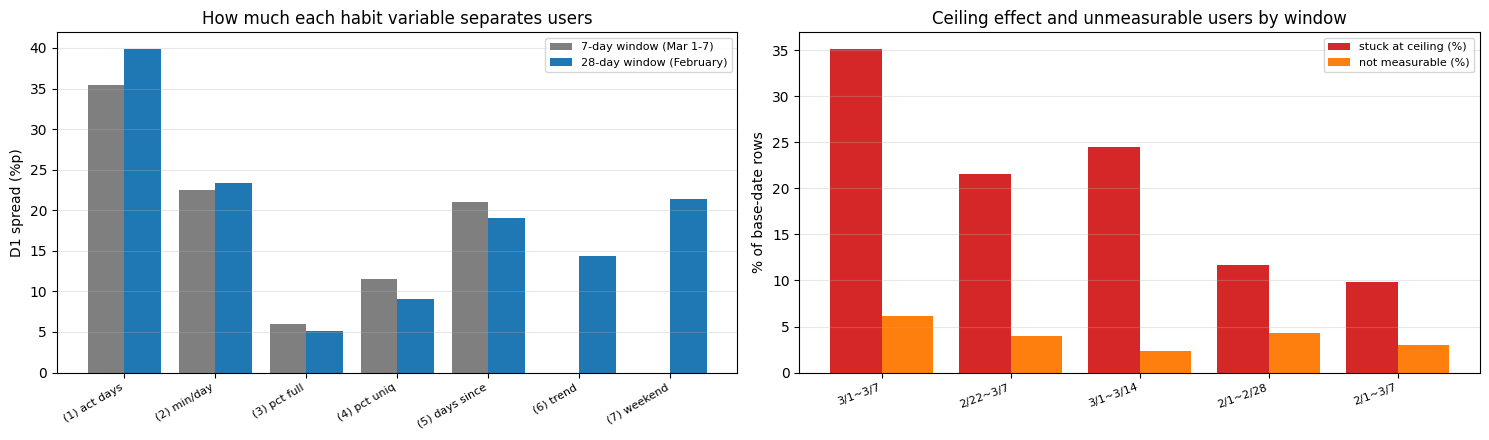

In [27]:
import numpy as np                # 숫자 배열 계산 도구
import matplotlib.pyplot as plt   # 그래프 그리는 도구

# 습관 측정 창을 왜 2월 한 달로 정했는지 수치로 보임.
# 처음 설계는 3/1~3/7 7일이었음. 같은 변수를 두 창에서 계산해 '스프레드'로 비교함.
#   스프레드 = 그 변수로 집단을 나눴을 때 가장 높은 칸의 D1 − 가장 낮은 칸의 D1
#            = 그 변수 하나가 유저를 얼마나 갈라놓는가. 클수록 좋은 변수임

# ── 1) 3월 로그에서 7일 창(3/1~3/7) 변수를 다시 계산함 ──────────────────
_w = user_logs.loc[user_logs['date'] <= 20170307,
                   ['msno', 'date', 'num_25', 'num_50', 'num_75', 'num_985', 'num_100',
                    'num_unq', 'total_secs']]
_wc = pd.Categorical(_w['msno'], categories=uniq).codes.astype('int32')
_wd = (_w['date'].to_numpy() % 100 - 1).astype('int8')
_wts = _w['total_secs'].to_numpy()
_wsg = (_w['num_25'] + _w['num_50'] + _w['num_75'] + _w['num_985'] + _w['num_100']).to_numpy()
_wok = (_wts >= 0) & (_wts <= 86400)
_n = len(uniq)
_b = lambda w=None, f=None: np.bincount(_wc if f is None else _wc[f], minlength=_n,
                                        weights=w if f is None else (None if w is None else w[f]))
w7 = pd.DataFrame(index=np.arange(_n))
w7['act_days'] = _b().astype('int16')
_vd7 = _b(None, _wok)
with np.errstate(invalid='ignore', divide='ignore'):
    w7['mins_per_day'] = np.where(_vd7 > 0, _b(_wts.astype('float64'), _wok) / np.maximum(_vd7, 1) / 60, np.nan)
    _sg7 = _b(_wsg.astype('float64'))
    w7['pct_full'] = np.where(_sg7 > 0, _b(_w['num_100'].to_numpy().astype('float64')) / np.maximum(_sg7, 1), np.nan)
    w7['pct_unique'] = np.where(_sg7 > 0, _b(_w['num_unq'].to_numpy().astype('float64')) / np.maximum(_sg7, 1), np.nan)
_l7 = np.full(_n, -1, 'int8'); np.maximum.at(_l7, _wc, _wd)
_has7 = w7['act_days'].to_numpy() > 0
w7['days_since_last'] = np.where(_has7, 6 - _l7, np.nan)
w7.loc[~_has7, ['mins_per_day', 'pct_full', 'pct_unique']] = np.nan
del _w, _wc, _wd, _wts, _wsg

# 비교는 같은 기준일 행에서 해야 공정함. 7일 창은 3/1~3/7을 기준일로 쓸 수 없으므로
# 두 창 모두에 쓸 수 있는 3/8~3/30 행으로 맞춤
cmp = base.loc[base['day'] >= 7, ['u', 'd1']].copy()
_u = cmp['u'].to_numpy()
print('비교용 기준일 행 (3/8~3/30, 두 창 모두 적용 가능): {:,}'.format(len(cmp)))


def nz(a):
    """활동일 수는 0이 '측정 불가'를 뜻하므로 결측으로 바꿔 계산에서 뺌"""
    a = np.asarray(a, dtype=float)
    return np.where(a > 0, a, np.nan)


def sp_of(values, raw=False):
    """변수 하나의 스프레드(= 최고 칸 D1 − 최저 칸 D1, %p)를 구함. 측정 불가(결측)는 빼고 계산함.
    창 길이가 다르면 값의 가짓수도 달라져 칸 수가 들쭉날쭉해지므로, 비교할 때는 5분위로 통일함.
    raw=True면 값을 그대로 씀 (그 창에서 실제로 쓸 수 있는 해상도를 보고 싶을 때)"""
    v = np.asarray(values, dtype=float)[_u]
    ok = ~np.isnan(v)
    v2, y2 = v[ok], cmp['d1'].to_numpy()[ok]
    g = pd.Series(v2) if raw else pd.Series(np.digitize(v2, np.nanquantile(v2, [.2, .4, .6, .8])))
    t = pd.Series(y2).groupby(g).agg(['size', 'mean'])
    t = t[t['size'] >= 20000]
    return (t['mean'].max() - t['mean'].min()) * 100


print('\n' + '=' * 84)
print('[A] 창 길이에 따른 변수별 스프레드 (%p) — 클수록 집단을 잘 가름')
print('    칸 수를 5분위로 통일해 비교함 (창이 길면 값의 가짓수가 늘어 저절로 커지기 때문)')
print('=' * 84)
_rows = []
for col, lab in [('act_days', '① 활동일 수'), ('mins_per_day', '② 하루 평균 청취 시간'),
                 ('pct_full', '③ 완청 비율'), ('pct_unique', '④ 서로 다른 곡 비율'),
                 ('days_since_last', '⑤ 마지막 활동 이후 일수')]:
    _f = nz if col == 'act_days' else (lambda x: x)
    a, b2 = sp_of(_f(w7[col].to_numpy())), sp_of(_f(habit[col].to_numpy()))
    _rows.append({'변수': lab, '7일 창(3/1~3/7)': a, '28일 창(2월)': b2, '차이': b2 - a})
_rows.append({'변수': '⑥ 활동 추세', '7일 창(3/1~3/7)': np.nan,
              '28일 창(2월)': sp_of(habit['trend'].to_numpy()), '차이': np.nan})
_rows.append({'변수': '⑦ 주말 활동 비중', '7일 창(3/1~3/7)': np.nan,
              '28일 창(2월)': sp_of(habit['weekend_ratio'].to_numpy()), '차이': np.nan})
spread_tbl = pd.DataFrame(_rows)
print(spread_tbl.to_string(index=False, float_format='{:.1f}'.format))
print('※ ⑥⑦은 7일(1주)로는 계산할 수 없음 — ⑥은 전·후반을 나눌 수 없고, ⑦은 주말이 2일뿐이라 비중이 불안정함')
print('※ 값을 그대로 쓰면(5분위로 묶지 않으면) ① 활동일 수는 7일 창 {:.1f}%p / 28일 창 {:.1f}%p 로,'
      .format(sp_of(nz(w7['act_days'].to_numpy()), raw=True), sp_of(nz(habit['act_days'].to_numpy()), raw=True)))
print('   칸이 8개에서 29개로 늘어난 만큼 더 벌어짐. 아래 [B]의 천장 효과가 그 이유임')

print('\n' + '=' * 84)
print('[B] 왜 7일로는 부족한가 — 천장 효과와 측정 불가')
print('=' * 84)
_rows = []
for nm, v in [('7일 창 (3/1~3/7)', w7['act_days'].to_numpy()), ('28일 창 (2월)', habit['act_days'].to_numpy())]:
    vv = v[_u]
    mx = vv.max()
    _rows.append({'창': nm, '최댓값': mx, '측정 불가(=0)': (vv == 0).mean(),
                  '천장(=최댓값)에 몰린 비중': (vv == mx).mean(),
                  '천장 집단 D1': cmp['d1'].to_numpy()[vv == mx].mean(),
                  '구간 수': len(np.unique(vv))})
print(pd.DataFrame(_rows).to_string(index=False, float_format='{:.4f}'.format))

# 7일 창에서 '7일 내내'로 뭉친 유저를, 2월 활동일 수로 다시 쪼개면 갈라지는가
_top = w7['act_days'].to_numpy()[_u] == 7
_sub = pd.DataFrame({'feb': habit['act_days'].to_numpy()[_u][_top], 'd1': cmp['d1'].to_numpy()[_top]})
_g = _sub.groupby(pd.cut(_sub['feb'], [-1, 0, 13, 20, 24, 27, 28],
                         labels=['0일', '1~13일', '14~20일', '21~24일', '25~27일', '28일']))['d1'].agg(
    rows='size', D1='mean')
_g['share'] = _g['rows'] / _top.sum()
print('\n7일 창에서 "7일 내내 활동"으로 한 칸에 뭉친 {:,}행({:.1%})을 2월 활동일 수로 다시 쪼갠 결과:'.format(
    _top.sum(), _top.mean()))
print(_g[['rows', 'share', 'D1']].to_string(float_format='{:.4f}'.format))
print('→ 한 칸 안에서 D1이 {:.4f} ~ {:.4f} ({:.1f}%p)로 갈림. 7일 창은 이 정보를 통째로 버리고 있었음'.format(
    _g['D1'].min(), _g['D1'].max(), (_g['D1'].max() - _g['D1'].min()) * 100))

print('\n' + '=' * 84)
print('[C] 창의 길이와 최근성 중 무엇이 중요한가 — ① 활동일 수의 스프레드로 비교')
print('=' * 84)
# 2월·3월을 이어 붙인 (유저, 상대일) 목록. 2/1 = -28 ... 3/31 = 30
_fb = pd.read_parquet('data/user_logs_feb2017.parquet', columns=['msno', 'date'])
_fc = pd.Categorical(_fb['msno'], categories=uniq).codes.astype('int32')
_fd = (_fb['date'].to_numpy() % 100 - 1).astype('int16') - 28
_ok2 = _fc >= 0
_AU = np.concatenate([_fc[_ok2], (key_all // 64).astype('int32')])
_AD = np.concatenate([_fd[_ok2], (key_all % 64).astype('int16')])
del _fb, _fc, _fd
_rows = []
for nm, lo, hi in [('3/1~3/7 (처음 설계)', 0, 6), ('2/22~3/7 (최근 14일)', -7, 6),
                   ('3/1~3/14', 0, 13), ('2/1~2/28 (채택)', -28, -1), ('2/1~3/7 (35일)', -28, 6)]:
    _s = (_AD >= lo) & (_AD <= hi)
    v = np.bincount(_AU[_s], minlength=_n).astype('int16')
    vv = v[_u]
    _rows.append({'창': nm, '길이(일)': hi - lo + 1, '끝~3/8 거리': 7 - hi,
                  '측정 불가': (vv == 0).mean(), '천장 비중': (vv == vv.max()).mean(),
                  '① 스프레드(5분위, %p)': sp_of(nz(v))})
print(pd.DataFrame(_rows).to_string(index=False, float_format='{:.4f}'.format))
print('→ 창을 늘리면 천장 뭉침과 측정 불가가 크게 줄어듦. 다만 스프레드만 보면 "가깝고 짧은 창"도 좋음')
print('   그러나 가까운 창은 학습 기준일과 겹쳐 미래 정보가 섞이므로 쓸 수 없음 (3/1~3/14는 3/8~3/14를 포함함).')
print('   2월 창은 3월과 완전히 분리되어 이 문제가 없고, 측정 불가도 가장 적은 편임 → 2월을 선택함')

# ── 그래프: 스프레드 비교 ─────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
_lab = ['(1) act days', '(2) min/day', '(3) pct full', '(4) pct uniq', '(5) days since', '(6) trend', '(7) weekend']
_x = np.arange(len(_lab))
axes[0].bar(_x - 0.2, spread_tbl['7일 창(3/1~3/7)'].fillna(0), 0.4, label='7-day window (Mar 1-7)', color='tab:gray')
axes[0].bar(_x + 0.2, spread_tbl['28일 창(2월)'], 0.4, label='28-day window (February)', color='tab:blue')
axes[0].set_xticks(_x); axes[0].set_xticklabels(_lab, rotation=30, ha='right', fontsize=8)
axes[0].set_ylabel('D1 spread (%p)')
axes[0].set_title('How much each habit variable separates users')
axes[0].legend(fontsize=8); axes[0].grid(axis='y', alpha=.3)
_c = pd.DataFrame(_rows)
axes[1].bar(np.arange(len(_c)) - 0.2, _c['천장 비중'] * 100, 0.4, label='stuck at ceiling (%)', color='tab:red')
axes[1].bar(np.arange(len(_c)) + 0.2, _c['측정 불가'] * 100, 0.4, label='not measurable (%)', color='tab:orange')
axes[1].set_xticks(np.arange(len(_c)))
axes[1].set_xticklabels([n.split(' ')[0] for n in _c['창']], rotation=20, ha='right', fontsize=8)
axes[1].set_ylabel('% of base-date rows')
axes[1].set_title('Ceiling effect and unmeasurable users by window')
axes[1].legend(fontsize=8); axes[1].grid(axis='y', alpha=.3)
plt.tight_layout()
plt.show()

**결과 해석**

**(1) 창을 늘리면 가장 중요한 변수가 세진다 — 나머지는 조금 약해진다**

칸 수를 5분위로 통일한 스프레드(%p), 기준일 3/8~3/30

| 변수 | 7일 창 (3/1~3/7) | 28일 창 (2월) | 차이 |
|---|---|---|---|
| **① 활동일 수** | 35.4 | **39.9** | **+4.6** |
| ② 하루 평균 청취 시간 | 22.4 | 23.3 | +0.9 |
| ③ 완청 비율 | 5.9 | 5.1 | −0.9 |
| ④ 서로 다른 곡 비율 | 11.5 | 9.1 | −2.5 |
| ⑤ 마지막 활동 이후 일수 | 21.1 | 19.1 | −2.0 |
| **⑥ 활동 추세** | **계산 불가** | **14.4** | — |
| **⑦ 주말 활동 비중** | **계산 불가** | **21.4** | — |

읽는 법

- **가장 강한 변수 ①이 +4.6%p 세짐.** 값을 그대로 쓰면(5분위로 묶지 않으면) **43.0%p → 47.3%p** 로 더 벌어짐 — 칸이 8개에서 29개로 늘어난 만큼 해상도가 좋아진 것임
- ③④⑤는 **0.9~2.5%p 약해짐.** 28일 평균을 내면 비율이 고르게 다듬어지고(③④), ⑤는 창 끝(2/28)이 기준일에서 더 멀어지기 때문임. **잃는 것이 있다는 점을 숨기지 않음**
- **⑥⑦은 7일로는 아예 계산할 수 없음** — ⑥은 전·후반을 나눌 수 없고, ⑦은 주말이 2일뿐이라 비중이 불안정함. 둘을 합치면 **35.8%p어치의 새 축**이 생김
- 종합하면 **①의 이득 + 새 변수 2개 > ③④⑤의 손실**

**(2) 7일이 부족한 진짜 이유 — 천장 효과**

| 창 | 최댓값 | 구간 수 | 측정 불가 | **천장(최댓값)에 몰린 비중** | 천장 집단 D1 |
|---|---|---|---|---|---|
| 7일 (3/1~3/7) | 7일 | 8 | 6.10% | **35.18%** | 0.9278 |
| 28일 (2월) | 28일 | **29** | **4.28%** | **11.65%** | 0.9666 |

7일 창에서는 **기준일 행의 35%가 "7일 내내 활동" 한 칸에 뭉쳐** 서로 구분되지 않음. 그 483만 4,260행을 2월 활동일 수로 다시 쪼개면 이렇게 갈림.

| 2월 활동일 수 | 1~13일 | 14~20일 | 21~24일 | 25~27일 | 28일 |
|---|---|---|---|---|---|
| 비중 (이 집단 내) | 4.2% | 10.3% | 19.7% | 37.6% | 28.1% |
| D1 | 0.854 | **0.851** | 0.895 | 0.941 | **0.973** |

👉 한 칸 안에서 D1이 **12.3%p**나 갈림. **7일 창은 전체의 35%에 대해 이만큼의 정보를 통째로 버리고 있었음.**

**(3) 창의 길이와 최근성 중 무엇이 중요한가**

① 활동일 수의 5분위 스프레드로 비교 (기준일 3/8~3/30)

| 창 | 길이 | 끝~3/8 거리 | 측정 불가 | 천장 비중 | ① 스프레드 | 쓸 수 있나 |
|---|---|---|---|---|---|---|
| 3/1~3/7 (처음 설계) | 7일 | 1일 | 6.10% | 35.18% | 35.4%p | ○ |
| 3/1~3/14 | 14일 | **−6일** | 2.34% | 24.54% | **47.1%p** | **✕ 누수** |
| 2/22~3/7 | 14일 | 1일 | 4.01% | 21.59% | 40.9%p | ○ |
| **2/1~2/28 (채택)** | **28일** | 8일 | 4.28% | **11.65%** | 37.7%p | **○** |
| 2/1~3/7 | 35일 | 1일 | 3.01% | **9.87%** | 40.4%p | ○ |

- **가깝고 짧은 창이 스프레드만 보면 유리함** (3/1~3/14가 47.1%p로 1위). 그러나 이 창은 **학습 기준일 3/8~3/14와 겹쳐** 기준일 t 이후의 활동이 습관에 섞임 → **미래 정보 누수라 쓸 수 없음**
- 누수 없는 후보 중에서는 **2/1~3/7(35일)** 이 수치상 가장 낫고, **2/1~2/28(2월)** 이 그다음임

**(4) 그런데도 2월 한 달을 고른 이유 — 수치만으로 정하지 않았음**

2/1~3/7(35일)이 스프레드·천장에서 조금 앞서지만, 다음 이유로 **2월 한 달**을 택했음.

| 근거 | 내용 |
|---|---|
| **임의 선택이 없음** | 35일 창은 "왜 하필 3/7까지인가"를 따로 설명해야 함. 월 경계는 설명이 필요 없음 |
| **학습·평가가 대칭** | 2월을 창으로 쓰면 3월 전체를 기준일로 쓸 수 있어 **15일 vs 15일**로 나뉨. 35일 창은 학습 7일 vs 평가 16일로 비대칭 |
| **요일이 저절로 맞음** | 2월은 **정확히 4주**라 창 자체의 요일 균형이 완벽하고, 3월을 반으로 자르면 학습·평가의 금·토·일 비중이 둘 다 **0.40**으로 같아짐 (12절) |
| **학습 데이터 2.1배** | 413만 → **880만 행**. 조건 3개 조합 집단까지 안정적으로 학습하려면 양이 중요함 |
| **창과 분석 기간이 완전히 분리** | 2월과 3월이 겹칠 여지가 0이라 누수 논란이 생기지 않음 |
| **실무 서사** | "지난달 습관으로 이번 달을 진단한다" — 운영에서 그대로 쓸 수 있는 형태 |

**(5) 남은 한계**

- 2월 창은 기준일에서 **8~30일 떨어져** 있어, 가까운 창보다 설명력이 낮음. 그 대가로 누수가 없고 구조가 대칭이 됨
- 창을 아무리 늘려도 **3월 신규 가입자는 측정 불가**임 (측정 불가 집단의 48.8%) → 13절 (5) 참고
- **학습 기간이 7일 → 15일로 길어짐** = 실무 적용 시 "하락 이전 15일이 깨끗해야 한다"는 제약. 다만 이는 방법의 요구사항이 아니라 이 연구의 선택이므로, **학습을 3/9~3/15 7일로 줄인 민감도 분석**을 함께 보고해 "7일로도 된다"를 보일 예정임 (계획서 7.1)

### 13-2. 측정 창의 공휴일 3일은 그냥 둬도 되나

측정 창으로 고른 2017년 2월에는 **공휴일이 3일** 있음. 13-1절에서 2월을 고른 이유(천장 효과·누수·요일 균형)를 확인했지만, 공휴일이 습관 측정을 흐리지 않는지는 따로 봐야 함.

| 날짜 | DAU | 무슨 날 |
|---|---|---|
| **2/01 (수)** | **542,320** ← 2월 최저 | 설 연휴 마지막 날 (1/27~2/1, 6일) |
| 2/24 (금) | 594,178 ← 2월 최고 | 평소 수준 |
| 2/25 (토) · 2/26 (일) | 577,396 · 562,206 | 228 연휴 (4일 연휴 시작) |
| **2/27 (월)** | **564,515** | 대체공휴일 |
| **2/28 (화)** | 580,923 | 평화기념일 |

**왜 주말 변수(⑦)에 섞지 않는가**: 주말은 매주 반복되는 안정적인 리듬임(2월에 8일, 4주 × 2일). 반면 공휴일 3일은 DAU가 542,320 · 564,515 · 580,923 으로 **서로 40,000 가까이 벌어짐** — 긴 설 연휴와 짧은 228 연휴는 전혀 다른 행동임. 한 칸에 넣으면 주말 신호를 공휴일 잡음으로 희석시킴.

**왜 공휴일 변수를 따로 만들지도 않는가**: 3일뿐이라 값이 0 / ⅓ / ⅔ / 1 네 가지밖에 안 되어 분위를 가를 수 없고, 성격이 다른 두 연휴를 한 변수에 섞는 문제가 되돌아옴. 변수 후보를 고르는 기준이 "**해석 가능성 > 변수 개수**"이므로(13절에서 변동계수·간격 편차를 뺀 것과 같은 이유) 변수로 만들지 않음.

그러면 남는 질문은 하나임 — **그냥 둬도 되는가.** 습관 7개를 두 번 계산해 나란히 비교함.

| | 측정 창 | 반반 분할(⑥) | 창의 끝(⑤) |
|---|---|---|---|
| **(A)** | 28일 전체 — **현재 정의** | 2/1~2/14 / 2/15~2/28 (14·14일) | 2/28 |
| **(B)** | 공휴일 3일을 뺀 **25일** | 2/2~2/14 / 2/15~2/26 (13·12일) | 2/26 |

영향이 미미하다면 **상관 ≈ 1**, **분위 일치율이 높고**, **D1 스프레드 차이 ≈ 0** 이어야 함. 스프레드는 13절과 같은 정의임(가장 높은 분위 − 가장 낮은 분위, 2만 행 미만 칸 제외).

> ⑥은 반반 분할의 일수가 (B)에서 13·12일로 어긋나므로, 두 정의를 같은 눈금에 두기 위해 **활동 비율의 차이를 14일로 환산**해 계산함. 그래서 (A)의 ⑥ 값은 13절의 "활동일 수 차이"와 숫자가 같지 않음.


기준일 행 17,818,632 / 3월 활동 유저 1,103,894명 / 전체 D1 0.7816
공휴일 3일의 2월 로그 비중: 1,644,814행 / 15,579,565행 = 10.56%   (날짜 비중 3/28 = 10.71%)

[1] 공휴일을 빼면 측정 불가로 넘어가는 유저
2월 활동 있음  (A) 28일: 954,116명 (86.43%)   (B) 25일: 942,810명 (85.41%)
공휴일 3일에만 활동한 유저: 11,306명 (3월 활동 유저의 1.0242%)
   → 기준일 행 89,046개 (0.4997%), 이 행들의 D1 = 0.6641 (전체 0.7816) — 버리기 아까운 집단임

[2] 변수별 비교 — (A) 28일 전체  vs  (B) 공휴일 3일 제외 25일
                A 평균     B 평균 상관(A,B) 분위 일치율 A 스프레드 B 스프레드    차이
변수                                                              
① 활동일 수      14.1133  12.6233 0.99686 90.70%  40.04  39.64 -0.39
② 하루 청취 시간  112.2680 112.3534 0.99272 87.80%  23.88  23.62 -0.26
③ 완청 비율       0.7008   0.7019 0.97796 89.35%   5.18   5.21 +0.03
④ 서로 다른 곡     0.7712   0.7722 0.98121 88.03%   9.24   9.28 +0.05
⑤ 마지막 이후 일수   1.8163   1.7077 0.84060 26.09%  19.74  16.78 -2.96
⑥ 활동 추세       0.4099   0.3986 0.96846 73.93%  14.89  16.23 +1.34
⑦ 주말 활동 비중    0.2894   0.3321 0.93801 81.72%  21.86  20.80 -1.07

※ ⑤와 ⑥은 이 비교로 공휴일 효과를 가

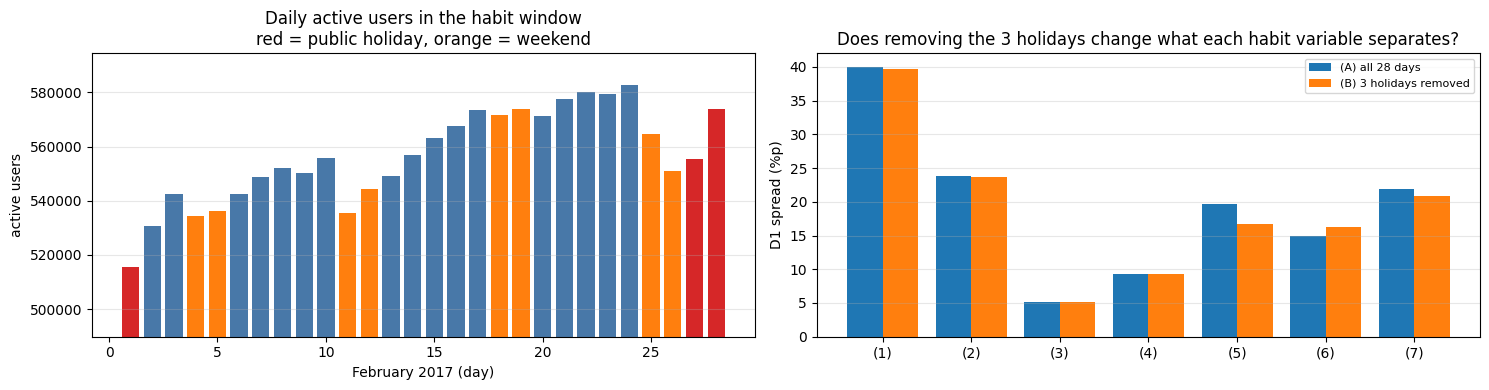

In [ ]:
# 측정 창인 2월에는 공휴일이 3일 있음 — 2/1(설 연휴 마지막 날), 2/27(대체공휴일), 2/28(평화기념일).
# 2/25~2/28이 4일 연휴였고, 2/1은 1/27부터 이어진 6일 설 연휴의 마지막 날임.
# 공휴일은 주말과 성격이 달라(1회성이고 서로도 다름) 주말 변수에 섞을 수 없음. 그래서
# "공휴일을 변수로 만들지 않고 그냥 둬도 되는가"를 수치로 확인함.
# 방법: 습관 7개를 두 번 계산해 나란히 비교함.
#   (A) 28일 전체 — 현재 정의
#   (B) 공휴일 3일을 뺀 25일
# 영향이 미미하다면 상관 ≈ 1, 분위 일치율이 높고, D1 스프레드 차이가 ≈ 0 이어야 함.

_HOL = [0, 26, 27]                                    # 2/1 → 0 ... 2/28 → 27
_HOLKR = ['2/01 Wed (Lunar NY)', '2/27 Mon (bridge)', '2/28 Tue (Peace Memorial)']

# ── 1) 기준일 행과 D1 — 9절이 만들어 둔 캐시에서 바로 읽음 ───────────────
_z = np.load('data/cache/active_keys.npz')
_ka = _z['key_all']
_uq = pd.read_parquet('data/cache/active_users.parquet')['msno']
_bsel = (_ka % 64) <= 29                                            # 기준일 3/1~3/30
_bk = _ka[_bsel]
_bu = (_bk // 64).astype('int32')                                   # 기준일 행의 유저 번호
_p = np.searchsorted(_ka, _bk + 1)
_y1 = ((_p < len(_ka)) & (_ka[np.minimum(_p, len(_ka) - 1)] == _bk + 1)).astype('float32')
_NU = len(_uq)
print('기준일 행 {:,} / 3월 활동 유저 {:,}명 / 전체 D1 {:.4f}'.format(len(_bu), _NU, _y1.mean()))

# ── 2) 2월 로그를 배열로 펼침 (13절과 같은 방식) ─────────────────────────
_hc = pd.Categorical(user_logs_feb['msno'], categories=_uq).codes.astype('int32')
_hd2 = (user_logs_feb['date'].to_numpy() % 100 - 1).astype('int8')
_ts2 = user_logs_feb['total_secs'].to_numpy()
_sg2 = (user_logs_feb['num_25'] + user_logs_feb['num_50'] + user_logs_feb['num_75']
        + user_logs_feb['num_985'] + user_logs_feb['num_100']).to_numpy()
_f2, _q2 = user_logs_feb['num_100'].to_numpy(), user_logs_feb['num_unq'].to_numpy()
_keep = _hc >= 0                                                    # 3월에도 활동한 유저만
_ok2 = ~((_ts2 < 0) | (_ts2 > 86400))                               # ② 계산에서 뺄 이상값
_hc, _hd2, _ts2, _sg2, _f2, _q2, _ok2 = (a[_keep] for a in (_hc, _hd2, _ts2, _sg2, _f2, _q2, _ok2))
_ish = np.isin(_hd2, _HOL)
print('공휴일 3일의 2월 로그 비중: {:,}행 / {:,}행 = {:.2%}   (날짜 비중 3/28 = 10.71%)'.format(
    _ish.sum(), len(_hc), _ish.mean()))

# ── 3) 날짜 집합을 받아 습관 7개를 계산하는 함수 ─────────────────────────
def _agg(sel, lo, hi, lo_n, hi_n, end_day):
    """sel = 쓸 날짜(행) 표시. lo/hi = 전반·후반 날짜 표시, lo_n/hi_n = 그 일수,
       end_day = 창의 마지막 날짜 번호 (⑤의 기준점)"""
    _bc = lambda w=None, f=None: np.bincount(
        _hc[sel if f is None else (sel & f)], minlength=_NU,
        weights=None if w is None else w[sel if f is None else (sel & f)])
    _dy = _bc().astype('int16')
    _vd = _bc(None, _ok2)
    _has2 = _dy > 0
    out = pd.DataFrame(index=np.arange(_NU))
    with np.errstate(invalid='ignore', divide='ignore'):
        out['act_days'] = _dy.astype('float32')                                            # ①
        out['mins_per_day'] = np.where(_vd > 0, _bc(_ts2, _ok2) / np.maximum(_vd, 1) / 60, np.nan)  # ②
        _s = _bc(_sg2.astype('float64'))
        out['pct_full'] = np.where(_s > 0, _bc(_f2.astype('float64')) / np.maximum(_s, 1), np.nan)   # ③
        out['pct_unique'] = np.where(_s > 0, _bc(_q2.astype('float64')) / np.maximum(_s, 1), np.nan) # ④
    _lst = np.full(_NU, -1, 'int16'); np.maximum.at(_lst, _hc[sel], _hd2[sel])
    out['days_since_last'] = np.where(_has2, end_day - _lst, np.nan)                        # ⑤
    # ⑥ 추세 — 반반 분할의 일수가 다를 수 있으므로 비율로 재고 14일 눈금으로 환산함
    out['trend'] = np.where(_has2, (_bc(None, hi) / hi_n - _bc(None, lo) / lo_n) * 14, np.nan)
    out['weekend_ratio'] = np.where(_has2, _bc(None, np.isin(_hd2 % 7, [3, 4]))             # ⑦
                                    / np.maximum(_dy, 1), np.nan)
    out['_has'] = _has2
    return out

_all = np.ones(len(_hd2), bool)
_HA = _agg(_all, _hd2 <= 13, _hd2 >= 14, 14, 14, 27)                      # (A) 28일: 2/1~2/14 / 2/15~2/28
_HB = _agg(~_ish, (_hd2 >= 1) & (_hd2 <= 13), (_hd2 >= 14) & (_hd2 <= 25), 13, 12, 25)
#          (B) 25일: 전반 2/2~2/14(13일) / 후반 2/15~2/26(12일), 창 끝은 2/26

_HKR = {'act_days': '① 활동일 수', 'mins_per_day': '② 하루 청취 시간', 'pct_full': '③ 완청 비율',
        'pct_unique': '④ 서로 다른 곡', 'days_since_last': '⑤ 마지막 이후 일수',
        'trend': '⑥ 활동 추세', 'weekend_ratio': '⑦ 주말 활동 비중'}

# ── 4) 공휴일에만 활동한 유저 — 공휴일을 빼면 측정 불가로 넘어가는 집단 ──
print('\n' + '=' * 90)
print('[1] 공휴일을 빼면 측정 불가로 넘어가는 유저')
print('=' * 90)
_onlyh = _HA['_has'].to_numpy() & ~_HB['_has'].to_numpy()
print('2월 활동 있음  (A) 28일: {:,}명 ({:.2%})   (B) 25일: {:,}명 ({:.2%})'.format(
    _HA['_has'].sum(), _HA['_has'].mean(), _HB['_has'].sum(), _HB['_has'].mean()))
_rows_h = np.isin(_bu, np.flatnonzero(_onlyh))
print('공휴일 3일에만 활동한 유저: {:,}명 (3월 활동 유저의 {:.4%})'.format(_onlyh.sum(), _onlyh.mean()))
print('   → 기준일 행 {:,}개 ({:.4%}), 이 행들의 D1 = {:.4f} (전체 {:.4f}) — 버리기 아까운 집단임'.format(
    _rows_h.sum(), _rows_h.mean(), _y1[_rows_h].mean(), _y1.mean()))

# ── 5) 변수별 비교 ───────────────────────────────────────────────────────
def _spread(v):
    """유저별 값을 기준일 행으로 펼친 뒤 5분위 D1 스프레드(%p). 2만 행 미만 칸은 제외함"""
    x = v[_bu]
    m = ~np.isnan(x)
    g = np.digitize(x[m], np.nanquantile(x[m], [.2, .4, .6, .8]))
    tb = pd.DataFrame({'g': g, 'y': _y1[m]}).groupby('g')['y'].agg(['size', 'mean'])
    tb = tb[tb['size'] >= 20000]
    return (tb['mean'].max() - tb['mean'].min()) * 100 if len(tb) > 1 else np.nan

print('\n' + '=' * 90)
print('[2] 변수별 비교 — (A) 28일 전체  vs  (B) 공휴일 3일 제외 25일')
print('=' * 90)
_rr = []
for _c in HABIT_COLS:
    _a, _bb = _HA[_c].to_numpy('float64'), _HB[_c].to_numpy('float64')
    _m = ~np.isnan(_a) & ~np.isnan(_bb)
    _qa = np.digitize(_a[_m], np.nanquantile(_a[_m], [.2, .4, .6, .8]))
    _qb = np.digitize(_bb[_m], np.nanquantile(_bb[_m], [.2, .4, .6, .8]))
    _sa, _sb = _spread(_a), _spread(_bb)
    _rr.append({'변수': _HKR[_c], 'A 평균': np.nanmean(_a), 'B 평균': np.nanmean(_bb),
                '상관(A,B)': np.corrcoef(_a[_m], _bb[_m])[0, 1], '분위 일치율': (_qa == _qb).mean(),
                'A 스프레드': _sa, 'B 스프레드': _sb, '차이': _sb - _sa})
hol_cmp = pd.DataFrame(_rr).set_index('변수')
print(hol_cmp.to_string(formatters={
    'A 평균': '{:.4f}'.format, 'B 평균': '{:.4f}'.format, '상관(A,B)': '{:.5f}'.format,
    '분위 일치율': '{:.2%}'.format, 'A 스프레드': '{:.2f}'.format, 'B 스프레드': '{:.2f}'.format,
    '차이': '{:+.2f}'.format}))
print('\n※ ⑤와 ⑥은 이 비교로 공휴일 효과를 가릴 수 없음 — ⑤는 창의 끝이 2/28에서 2/26으로 옮겨가고,')
print('   ⑥은 반반 분할이 13일/12일로 깨져 비율 환산까지 함께 바뀜. 공휴일만의 효과가 아님.')

# ── 6) ⑦ 주말 활동 비중 — 분모에서 공휴일을 빼면 칸이 깨지는지 확인 ──────
print('\n' + '=' * 90)
print('[3] ⑦ 주말 활동 비중 — 분모에서 공휴일을 빼면 5분위가 고르게 잘리나')
print('=' * 90)
for _lab, _v, _ref in [('A) 주말 8일 ÷ 전체 활동일 (28일, 현재 정의)', _HA['weekend_ratio'].to_numpy('float64'), 8 / 28),
                       ('B) 주말 8일 ÷ 공휴일 제외 활동일 (25일)', _HB['weekend_ratio'].to_numpy('float64'), 8 / 25)]:
    _x = _v[_bu]
    _m = ~np.isnan(_x)
    _g = np.digitize(_x[_m], np.nanquantile(_x[_m], [.2, .4, .6, .8]))
    _tb = pd.DataFrame({'g': _g, 'y': _y1[_m]}).groupby('g')['y'].agg(행='size', D1='mean')
    _tb.index = [f'{i+1}분위' for i in _tb.index]
    print(f'\n  {_lab}  (평균 {np.nanmean(_v):.4f}, 고르게 듣는 유저의 기준값 {_ref:.4f})')
    print('   ' + _tb.to_string(float_format='{:.4f}'.format).replace('\n', '\n   '))

# ── 7) 기대 모델 쪽 영향 — 두 정의로 D1을 설명했을 때 성능 차이 ──────────
print('\n' + '=' * 90)
print('[4] 기대 모델 쪽 영향 — 습관 7개 + 미측정 플래그로 D1을 설명')
print('=' * 90)
try:
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import roc_auc_score
    _sp = np.random.default_rng(0).choice(len(_bu), 2_000_000, replace=False)   # 200만 행 표본
    _half = np.arange(len(_sp)) % 2 == 0                                       # 절반 학습 / 절반 보류
    _auc = []
    for _lab, _H in [('A) 28일 전체', _HA), ('B) 공휴일 3일 제외', _HB)]:
        _X = np.nan_to_num(_H[HABIT_COLS].to_numpy('float32')[_bu[_sp]], nan=0.0)
        _X = np.c_[_X, ~_H['_has'].to_numpy()[_bu[_sp]]]
        _X = (_X - _X.mean(0)) / np.where(_X.std(0) > 0, _X.std(0), 1)
        _yy = _y1[_sp]
        _lr = LogisticRegression(max_iter=300).fit(_X[_half], _yy[_half])
        _auc.append({'정의': _lab, 'AUC (보류 절반)': roc_auc_score(_yy[~_half], _lr.decision_function(_X[~_half]))})
    _ad = pd.DataFrame(_auc)
    print(_ad.to_string(index=False, float_format='{:.5f}'.format))
    print('   AUC 차이: {:+.5f} — 공휴일을 빼면 오히려 조금 떨어짐'.format(
        _ad['AUC (보류 절반)'].iloc[1] - _ad['AUC (보류 절반)'].iloc[0]))
except ImportError:
    print('  sklearn이 없어 건너뜀 (결론에는 영향 없음)')

# ── 8) 그래프 ────────────────────────────────────────────────────────────
_dau = pd.Series(np.bincount(_hd2, minlength=28))
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
ax = axes[0]
_col = ['#d62728' if d in _HOL else ('#ff7f0e' if d % 7 in (3, 4) else '#4878a8') for d in range(28)]
ax.bar(range(1, 29), _dau.to_numpy(), color=_col)
ax.set_xlabel('February 2017 (day)')
ax.set_ylabel('active users')
ax.set_title('Daily active users in the habit window\nred = public holiday, orange = weekend')
ax.set_ylim(_dau.min() * 0.95, _dau.max() * 1.02)
ax.grid(axis='y', alpha=.3)

ax = axes[1]
_xx = np.arange(len(HABIT_COLS))
ax.bar(_xx - 0.2, hol_cmp['A 스프레드'].to_numpy(), 0.4, label='(A) all 28 days')
ax.bar(_xx + 0.2, hol_cmp['B 스프레드'].to_numpy(), 0.4, label='(B) 3 holidays removed')
ax.set_xticks(_xx)
ax.set_xticklabels([f'({i+1})' for i in _xx])
ax.set_ylabel('D1 spread (%p)')
ax.set_title('Does removing the 3 holidays change what each habit variable separates?')
ax.legend(fontsize=8)
ax.grid(axis='y', alpha=.3)
plt.tight_layout()
plt.show()

del _HA, _HB, _hc, _hd2, _ts2, _sg2, _f2, _q2, _ok2, _ka, _ish   # 메모리 정리


**결과 해석**

**(1) 가장 단순한 증거 — 공휴일이라고 청취량이 줄지 않는다**

공휴일 3일이 2월 로그에서 차지하는 비중이 **10.56%** 입니다. 날짜 비중(3일 ÷ 28일 = **10.71%**)과 거의 같습니다 → 공휴일의 청취량은 평소의 **98.6%** 입니다.

**(2) ①②③④는 사실상 무영향**

| 변수 | 상관(A,B) | 분위 일치율 | A 스프레드 | B 스프레드 | 차이 |
|---|---|---|---|---|---|
| ① 활동일 수 | **0.9969** | 90.7% | 40.04 | 39.64 | −0.39 |
| ② 하루 청취 시간 | **0.9927** | 87.8% | 23.88 | 23.62 | −0.26 |
| ③ 완청 비율 | **0.9780** | 89.4% | 5.18 | 5.21 | +0.03 |
| ④ 서로 다른 곡 | **0.9812** | 88.0% | 9.24 | 9.28 | +0.05 |

공휴일 3일을 빼도 유저별 값이 거의 그대로이고(상관 0.978~0.997), **D1을 가르는 힘의 차이가 0.03~0.39%p** 입니다. ① 활동일 수의 평균이 14.11 → 12.62로 줄어든 것은 세는 날이 28일에서 25일로 줄었기 때문이고, 유저 간 **순위는 거의 그대로**입니다.

**(3) ⑦ 주말 활동 비중 — 공휴일을 분모에서 빼면 오히려 나빠진다**

처음에는 "2/1·2/27·2/28 활동이 평일로 세어지니 분모에서 빼야 한다"고 봤는데, 재 보니 **반대**였습니다.

| | A) 분모 28일 (현재) | B) 분모 25일 |
|---|---|---|
| 스프레드 | **21.86%p** | 20.80%p |
| 3분위 칸 | 3,567,842행 | **1,607,964행** ← 칸이 깨짐 |
| 4분위 칸 | 3,308,325행 | **5,550,851행** |

분모를 25로 바꾸면 값이 듬성듬성해져 **5분위가 고르게 안 잘립니다**(3분위 161만 vs 4분위 555만). 빔 서치의 구간 경계를 분위로 잡는 설계에서는 이게 직접적인 손해입니다. **⑦은 현재 정의(토·일 8일 ÷ 전체 28일 활동일)를 유지합니다.**

두 정의 모두 D1이 **역U자**(3~4분위가 가장 높고 양 끝이 낮음)인 것은 같습니다 — 주말에만 듣거나 평일에만 듣는 극단이 둘 다 덜 남습니다.

**(4) ⑤·⑥은 이 비교로 판단할 수 없음**

| | 왜 |
|---|---|
| **⑤ 마지막 이후 일수** (일치율 26.1%) | (B)는 창의 끝이 2/28 → **2/26으로 옮겨가** 변수의 기준점 자체가 달라집니다. 공휴일 효과가 아니라 **창 끝 이동 효과**입니다. 다만 2/28 DAU가 **580,923** 으로 2월 화요일 평균(579,279)과 사실상 같아, 창의 마지막 날로 쓰는 데 문제는 없습니다 |
| **⑥ 활동 추세** (일치율 73.9%) | (B)에서 반반 분할이 13일/12일로 깨져 **비율 환산**까지 동시에 바뀌었습니다. 공휴일만의 효과로 돌릴 수 없습니다. 스프레드가 14.89 → 16.23으로 커졌으니 해롭지는 않습니다 |

**(5) 모델 쪽 영향과, 빼면 생기는 비용**

| | |
|---|---|
| **AUC** (습관 7개 + 미측정 플래그, 200만 행, 절반 보류) | A **0.74855** vs B 0.74616 → **차이 −0.0024** |
| **비용** | 공휴일 3일에만 활동한 유저가 **11,306명**(3월 활동 유저의 1.02%). 공휴일을 빼면 이들이 "습관 미측정"으로 넘어갑니다 — 기준일 행 89,046개(0.50%)이고 D1이 **0.6641**(전체 0.7816)로 낮아, 습관 변수로 설명해야 할 집단을 잃는 셈입니다 |

**결론 — 공휴일은 그냥 둔다**

| | |
|---|---|
| 공휴일 변수 | **만들지 않음** |
| 습관 변수 7개 | **28일 전체를 그대로 사용.** 정의 변경 없음 |
| 근거 | 로그 비중 10.56% ≈ 날짜 비중 10.71% / 상관 0.978~0.997 / 스프레드 차이 0.03~0.39%p / AUC 차이 0.0024 / 빼면 1.02% 유저가 측정 불가로 넘어감 |

**연구에 주는 의미 (⑥의 해석을 바꿔야 함)**

2월은 **설 연휴(1/27~2/1) 바로 다음 달**입니다. DAU가 2/1 542,320 → 2/24 594,178로 월 내내 **+9.6%** 오릅니다. 즉 ⑥ 활동 추세는 상당 부분 **"설 연휴에서 얼마나 평소로 돌아왔나"** 를 재고 있습니다. 모두에게 공통으로 걸리는 효과라 분위 순위는 흔들리지 않지만, 가설 문장은 이렇게 읽어야 정확합니다.

> ~~"2월 후반에 활동이 급감한 집단"~~ → **"설 연휴 이후 평소 수준으로 돌아오지 않은 집단"**

**연구에 주는 의미 (공휴일은 거짓 경보 원인으로 남음)**

습관 변수 쪽은 안전하지만, **기준일 쪽에서는 공휴일이 D1을 2~4%p 깎습니다**(2/27 −2.53%p, 2/28 −4.10%p, 요일 보정 후 — 4절 참조). 2017년 3월에는 대만 공휴일이 없어 **주 분석은 안전**하지만, 다른 서비스·기간에 이 방법을 적용할 때는 공휴일이 가짜 하락으로 잡힐 수 있으므로 **적용 조건으로 명시해야 합니다.**
